# Πρόβλεψη κίνησης κινητού δικτύου: Telecom Italia, Μιλάνο (grid 5060)

#### Δομή του notebook
1. Το τηλεπικοινωνιακό πρόβλημα, το experimental setting, οι μεταβλητές και τα δεδομένα: απομόνωση του τετραγώνου,
   σχηματισμός των χρονοσειρών, διαχωρισμός train/test, διερευνητική ανάλυση.
2. ARIMA, s-ARIMA, ARIMA-x: θεωρία, εκτίμηση των υπερπαραμέτρων $d, p, q$ (και $D, P, Q$), εκτίμηση των μοντέλων,
   rolling-window πρόβλεψη.
3. Deep learning (LSTM): θεωρία, κανονικοποίηση, από-περιοδικοποίηση, εκπαίδευση.
4. Foundation model (TimesFM 3.0): θεωρία, zero-shot και fine-tuning.
5. Αποτίμηση όλων των μοντέλων: RMSE, MAE, MAPE, MASE, απεικονίσεις, κριτήρια επιτυχίας, διαστήματα πρόβλεψης 95%.
6. Τηλεπικοινωνιακή σημασία, ενορχήστρωση σε δίκτυο 6G πραγματικού χρόνου, χρόνοι inference.


## 1. Το τηλεπικοινωνιακό πρόβλημα, το experimental setting και τα δεδομένα

Πρώτα εξηγούμε το πρόβλημα και από πού προέρχονται τα δεδομένα, και μετά φτιάχνουμε τις χρονοσειρές και εξετάζουμε τι
δείχνουν.

### 1.1 Το τηλεπικοινωνιακό πρόβλημα και η σημασία του στα δίκτυα 5G/6G

Η πρόβλεψη φορτίου κίνησης (traffic load forecasting) εκτιμά τον μελλοντικό όγκο δραστηριότητας (δεδομένα, κλήσεις,
μηνύματα) σε μια κυψέλη ή γεωγραφική περιοχή, με βάση το ιστορικό της. Στα δίκτυα 5G και 6G η ιδέα είναι η διαχείριση
πόρων να γίνεται προληπτικά (proactive) και όχι αντιδραστικά (reactive), δηλαδή πριν εμφανιστεί η συμφόρηση. Αυτό είναι εφικτό γιατί στα 5G/6G πολλές λειτουργίες
του δικτύου τρέχουν ως λογισμικό και η χωρητικότητα μπορεί να αλλάζει δυναμικά. Αν το δίκτυο
ξέρει ότι σε 10 έως 50 λεπτά η ζήτηση σε μια κυψέλη θα αυξηθεί, μπορεί έγκαιρα να:

* δεσμεύσει φάσμα (PRBs, carrier aggregation) ή να ενεργοποιήσει small cells που ήταν σε κατάσταση ύπνου,
* κλιμακώσει τις εικονικές λειτουργίες δικτύου (UPF στο core, CU/DU του vRAN) και τους πόρους του edge (MEC),
* μοιράσει τη χωρητικότητα ανάμεσα στα network slices (eMBB, URLLC, mMTC),
* μεταφέρει φορτίο σε γειτονικές κυψέλες (mobility load balancing).

Αντίστροφα, όταν προβλέπεται χαμηλό φορτίο, μπορεί να απελευθερώσει πόρους και να απενεργοποιήσει εξοπλισμό για
εξοικονόμηση ενέργειας. Το πόσο ασφαλές είναι αυτό εξαρτάται από το πόσο καλή είναι η πρόβλεψη.

Η σχέση με το ZSM. Το Zero-touch network and Service Management (ZSM) του ETSI ορίζει μια αρχιτεκτονική πλήρως
αυτοματοποιημένης διαχείρισης δικτύου. Ο βασικός μηχανισμός του είναι ο κλειστός βρόχος: *παρακολούθηση* (monitor)
$\rightarrow$ *ανάλυση* (analyze) $\rightarrow$ *απόφαση* (decide) $\rightarrow$ *εκτέλεση* (execute), και ξανά από την αρχή. Η
πρόβλεψη κίνησης ανήκει στο στάδιο της ανάλυσης: μετατρέπει τις μετρήσεις του παρελθόντος σε εκτίμηση του μέλλοντος, και
πάνω σε αυτή ενεργεί το στάδιο της απόφασης. Χωρίς πρόβλεψη ο βρόχος μπορεί μόνο να αντιδρά. Αντίστοιχο ρόλο έχουν η NWDAF
στο 5G core (3GPP TS 23.288) και ο RAN Intelligent Controller (RIC) στην αρχιτεκτονική O-RAN. Η ενορχήστρωση σε πραγματικό
δίκτυο θα τη συζητήσουμε αργότερα.

Το πρόβλημα ακριβώς. Για το τετράγωνο 5060 του Μιλάνου έχουμε τρεις χρονοσειρές με ένα σημείο ανά δεκάλεπτο: Internet, SMS
και Calls. Σε κάθε χρονική στιγμή $t$, με γνωστές όλες τις τιμές ως και το $t$, θέλουμε να προβλέψουμε:

* short-term: την τιμή του επόμενου δεκαλέπτου, $\hat y_{t+1}$ ($h = 1$, 10 λεπτά μπροστά),
* long-term: τις τιμές των πέντε επόμενων δεκαλέπτων, $\hat y_{t+1}, \dots, \hat y_{t+5}$ ($H = 5$, έως 50 λεπτά μπροστά).

Κάθε σειρά προβλέπεται χωριστά, από το δικό της παρελθόν. Το ARIMA-x χρησιμοποιεί επιπλέον δείκτες ώρας και ημέρας, που
είναι γνωστοί από πριν.

### 1.2 Experimental setting: πώς προέκυψαν τα δεδομένα

Τα παρακάτω προέρχονται από το άρθρο που περιγράφει το dataset (Barlacchi et al., *Scientific Data*, 2015). Τα δεδομένα
δημοσιεύτηκαν από την Telecom Italia για το *Big Data Challenge 2014* και καλύπτουν το διάστημα 1 Νοεμβρίου 2013 έως 1
Ιανουαρίου 2014.

Τα δεδομένα προέρχονται από Call Detail Records (CDRs). Στα SMS γράφεται ένα CDR για κάθε SMS που στέλνεται ή λαμβάνεται, και
στις κλήσεις για κάθε κλήση που ξεκινά ή λαμβάνεται. Στο Internet γράφεται όταν ξεκινά ή τελειώνει μια σύνδεση, και κατά τη
διάρκειά της αν κρατήσει πάνω από 15 λεπτά ή αν μεταφερθούν πάνω από 5 MB.

Το Μιλάνο χωρίζεται σε πλέγμα $100 \times 100$ τετραγώνων, περίπου $235 \times 235$ m το καθένα. Κάθε αλληλεπίδραση ανήκει στην
περιοχή κάλυψης της κεραίας (RBS) που την εξυπηρέτησε, και μοιράζεται στα τετράγωνα ανάλογα με την επικάλυψή τους με αυτή. Το
«τετράγωνο» δεν είναι λοιπόν κυψέλη, και η τιμή του δεν είναι ακριβώς ό,τι συνέβη μέσα στα όριά του. Χρονικά, η δραστηριότητα
αθροίζεται σε δεκάλεπτα.

Οι τιμές είναι κλιμακωμένες με μια σταθερά $k$ της Telecom Italia, της οποίας η τιμή δεν δημοσιεύεται, ώστε να μην
αποκαλύπτεται το πραγματικό πλήθος κλήσεων, SMS και συνδέσεων. Έτσι είναι σχετικοί δείκτες δραστηριότητας χωρίς φυσική
μονάδα, κάτι που επηρεάζει την ερμηνεία των μετρικών σφάλματος, όπως θα δούμε αργότερα.

Τρία όρια των δεδομένων που πρέπει να έχουμε υπόψη:

* Το Internet μετρά πλήθος CDRs και όχι bytes. Με τον κανόνα των 15 λεπτών και των 5 MB ακολουθεί εν μέρει τον όγκο, αλλά δεν
  είναι ο όγκος.
* Καλύπτονται μόνο οι πελάτες της Telecom Italia και όσοι χρησιμοποιούν το δίκτυο της με roaming. Το άρθρο εκτιμά ότι αυτό
  είναι το πολύ το 34% του πληθυσμού.
* Τα δεδομένα είναι του 2013, πριν από το 5G, και το άρθρο δεν αναφέρει την τεχνολογία του δικτύου. Η χρήση τους ως εικόνα του
  φορτίου ενός δικτύου 5G/6G είναι δική μας υπόθεση εργασίας, που ακολουθεί την εκφώνηση.

### 1.3 Οι μεταβλητές και το τετράγωνο 5060

Κάθε γραμμή των αρχείων αντιστοιχεί σε ένα τετράγωνο, ένα δεκάλεπτο και έναν κωδικό χώρας:

| Μεταβλητή | Σημασία |
|:---|:---|
| `square_id` | το τετράγωνο του πλέγματος (1 έως 10000) |
| `time_interval` | αρχή του δεκαλέπτου, σε ms |
| `country_code` | κωδικός χώρας, με διαφορετική σημασία ανά δραστηριότητα: από πού ήρθε το εισερχόμενο SMS ή η κλήση, πού πήγε το εξερχόμενο, από πού ξεκίνησε η κίνηση Internet |
| `sms_in`, `sms_out` | δραστηριότητα εισερχόμενων και εξερχόμενων SMS |
| `call_in`, `call_out` | δραστηριότητα εισερχόμενων και εξερχόμενων κλήσεων |
| `internet` | δραστηριότητα Internet (CDRs) |

Το άρθρο δεν εξηγεί τον κωδικό 0, ούτε τι σημαίνει ένα κενό πεδίο. Στις επιλογές μας θα το δηλώνουμε ως υπόθεση.

Το τετράγωνο 5060. Σύμφωνα με τα όριά του στο αρχείο του πλέγματος, βρίσκεται πάνω στην Piazza del Duomo, και η Galleria
Vittorio Emanuele II είναι αμέσως βόρεια του. Είναι ένα κεντρικό, τουριστικό σημείο της πόλης, οπότε πριν δούμε τα
δεδομένα περιμένουμε έντονη δραστηριότητα, ημερήσια και εβδομαδιαία περιοδικότητα και αισθητή επίδραση των εορτών.


### 1.4 Απομόνωση του τετραγώνου 5060

Το αρχείο `data/grid5060_rows.tsv` περιέχει μόνο τις γραμμές του τετραγώνου 5060 και βρίσκεται ήδη στο repository.
Παράχθηκε με το `python download_dataset.py`, που διαβάζει τα 62 ημερήσια αρχεία (περίπου 21 GB), ελέγχει τα checksums
και κρατά μόνο το grid 5060. Δεν χρειάζεται να ξανατρέξει.


### 1.5 Σχηματισμός των χρονοσειρών και έλεγχος missing values

Στο επόμενο κελί κάνουμε δύο υποθέσεις που δεν αναφέρονται στο άρθρο:

* Τα κενά πεδία γίνονται 0, δηλαδή υποθέτουμε ότι κενό σημαίνει καμία καταγεγραμμένη δραστηριότητα.
* Ο χρόνος μετατρέπεται σε τοπική ώρα (`Europe/Rome`), με την υπόθεση ότι τα ms μετρούν από το Unix epoch σε UTC. Το στηρίζει το
  ότι έτσι η πρώτη και η τελευταία τιμή πέφτουν ακριβώς στις 00:00 της 1/11 και στις 23:50 της 1/1.

Αθροίζουμε πάνω σε όλα τα country codes, γιατί μας ενδιαφέρει η συνολική δραστηριότητα του τετραγώνου, και σχηματίζουμε τις
τρεις σειρές:

$$\text{Internet}_t, \qquad \text{SMS}_t = \text{SMS}^{\text{in}}_t + \text{SMS}^{\text{out}}_t, \qquad \text{Calls}_t = \text{Call}^{\text{in}}_t + \text{Call}^{\text{out}}_t$$

Κανένα διάστημα των 10, 20, 30 ή 60 λεπτών δεν είναι εντελώς χωρίς γραμμές, οπότε κρατάμε την πιο λεπτομερή ανάλυση, τα 10
λεπτά. Το `resample("10min").sum()` εξασφαλίζει ένα σημείο ανά δεκάλεπτο.


In [1]:
import pandas as pd

# Read TSV file
cols = ["square_id", "time_ms", "country_code", "sms_in", "sms_out", "call_in", "call_out", "internet"]
raw = pd.read_csv("data/grid5060_rows.tsv", sep="\t", header=None, names=cols)

# Convert time and replace NaNs
act = ["sms_in", "sms_out", "call_in", "call_out", "internet"]
raw[act] = raw[act].fillna(0.0)                       # empty field = no activity
raw["time"] = pd.to_datetime(raw["time_ms"], unit="ms", utc=True).dt.tz_convert("Europe/Rome").dt.tz_localize(None)
raw.head()

# Produce internet, sms and calls series
g = raw.groupby("time")[act].sum()                     # sum over all country codes
df = pd.DataFrame({"internet": g["internet"],
                   "sms": g["sms_in"] + g["sms_out"],
                   "calls": g["call_in"] + g["call_out"]})

# missing-value check at several resolutions: count intervals with no data at all
start, end = df.index.min().normalize(), df.index.max().normalize() + pd.Timedelta("1D")
for res in ["10min", "20min", "30min", "1h"]:
    full = pd.date_range(start, end, freq=res, inclusive="left")
    counts = df.resample(res).size().reindex(full, fill_value=0)
    print(res, len(full), "timestamps,", (counts == 0).sum(), "missing")

df = df.resample("10min").sum()
df.head()

10min 8928 timestamps, 0 missing
20min 4464 timestamps, 0 missing
30min 2976 timestamps, 0 missing
1h 1488 timestamps, 0 missing


,internet,sms,calls
time,,,
2013-11-01 00:00:00,392.178279,17.557269,18.132743
2013-11-01 00:10:00,402.885548,50.770405,15.653305
2013-11-01 00:20:00,350.060713,25.363502,12.460866
2013-11-01 00:30:00,427.730728,10.329996,23.500200
2013-11-01 00:40:00,434.044619,19.226668,12.441366


### 1.6 Διαχωρισμός train / test

Το test set είναι το τελευταίο τέταρτο της σειράς, στρογγυλεμένο σε ολόκληρες ημέρες, ώστε τα εποχικά μοντέλα ($s = 144$) να
βλέπουν πλήρεις περιόδους. Ο διαχωρισμός είναι χρονολογικός, γιατί ένας τυχαίος θα έβαζε μελλοντικές τιμές στο train (*data
leakage*). Η εκφώνηση προτείνει 1/3 ή 1/4: με 1/4 το train έχει 46 ημέρες (6624 σημεία) και το test 16 ημέρες (2304 σημεία).

Το test καλύπτει το διάστημα 17/12/2013 έως 01/01/2014, δηλαδή τα Χριστούγεννα και την Πρωτοχρονιά. Το train (01/11 έως 16/12)
έχει μόνο μεμονωμένες αργίες και καμία αντίστοιχη εορταστική περίοδο, οπότε το test ελέγχει και συνθήκες που τα μοντέλα δεν
έχουν δει.


In [2]:
TEST_FRAC = 0.25
SEASON = 144 # 1 day = 144*10 minutes
SERIES = ["internet", "sms", "calls"]

N = len(df)
n_test = int(round(N * TEST_FRAC / SEASON)) * SEASON       # the test set starts at midnight
n_train = N - n_test
print(f"N = {N}, train = {n_train}, test = {n_test}")

N = 8928, train = 6624, test = 2304


### 1.7 Διερευνητική ανάλυση (EDA)

Οι επιλογές που θα κάνουμε αργότερα για τα μοντέλα (εποχική περίοδος $s$, εξωγενείς μεταβλητές, ποιες ημέρες χρειάζονται ειδική
μεταχείριση) πρέπει να στηρίζονται σε αυτό που δείχνουν τα δεδομένα. Η EDA απαντά σε τέσσερα ερωτήματα: υπάρχει
περιοδικότητα και ποια; διαφέρουν οι εργάσιμες από τα Σαββατοκύριακα; υπάρχουν ανωμαλίες (αργίες, αιχμές); πόσο μοιάζουν οι
τρεις σειρές μεταξύ τους;

Το πρώτο κελί ορίζει:
* τις αργίες του διαστήματος: Αγίων Πάντων (1/11), Sant'Ambrogio (7/12, τοπική αργία του Μιλάνου), Αμόλυντος Σύλληψη (8/12),
  Χριστούγεννα (25/12), Santo Stefano (26/12), Πρωτοχρονιά (1/1),
* τη συνάρτηση `day_type`, που χωρίζει τις ημέρες σε τρεις κατηγορίες: εργάσιμη, Σάββατο, Κυριακή ή αργία. Το να μπαίνουν οι
  αργίες μαζί με τις Κυριακές είναι δική μας επιλογή: υποθέτουμε ότι μοιάζουν, χωρίς να το έχουμε ελέγξει ξεχωριστά.


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

COLOR = {"internet": "#2a78d6", "sms": "#eb6834", "calls": "#1baf7a"}
# All Saints, Sant'Ambrogio (Milan), Immaculate Conception, Christmas, St Stephen, New Year
HOLIDAYS = pd.to_datetime(["2013-11-01", "2013-12-07", "2013-12-08", "2013-12-25", "2013-12-26", "2014-01-01"])

def day_type(idx):
    """0 = working day, 1 = Saturday, 2 = Sunday / holiday"""
    t = np.where(idx.dayofweek == 5, 1, 0)
    return np.where((idx.dayofweek == 6) | idx.normalize().isin(HOLIDAYS), 2, t)

train, test = df.iloc[:n_train], df.iloc[n_train:]
t_split = test.index[0]
print(f"train {train.index[0]} -> {train.index[-1]}")
print(f"test  {test.index[0]} -> {test.index[-1]}")

train 2013-11-01 00:00:00 -> 2013-12-16 23:50:00
test  2013-12-17 00:00:00 -> 2014-01-01 23:50:00


Ολόκληρη η σειρά. Με γκρι σκιάζονται τα Σαββατοκύριακα και οι αργίες, και η διακεκομμένη γραμμή δείχνει την
αρχή του test set. Εδώ ψάχνουμε την τάση (υπάρχει ή όχι), τον εβδομαδιαίο ρυθμό και τυχόν ασυνήθιστες ημέρες.

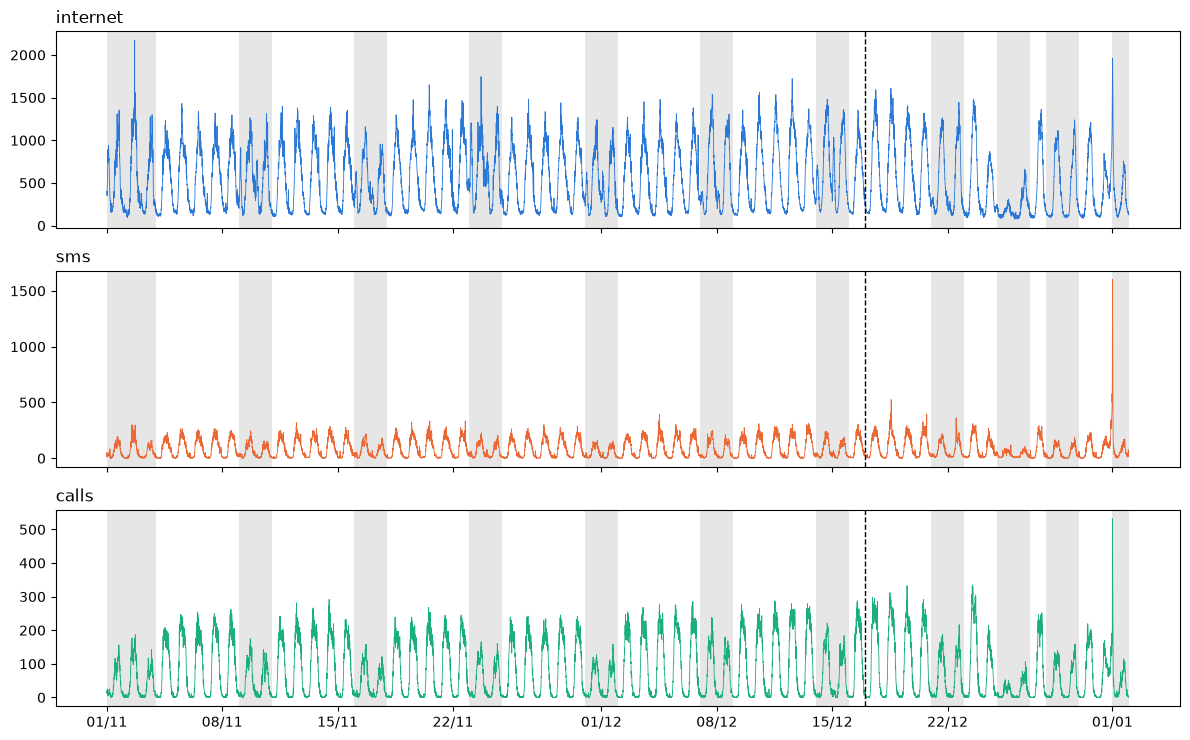

In [4]:
# Full series, weekends/holidays shaded, dashed line = start of test set
fig, axes = plt.subplots(3, 1, figsize=(12, 7.5), sharex=True)
for ax, s in zip(axes, SERIES):
    ax.plot(df.index, df[s], color=COLOR[s], lw=0.6)
    for d in pd.date_range(df.index[0].normalize(), df.index[-1].normalize(), freq="D"):
        if d.dayofweek >= 5 or d in HOLIDAYS:
            ax.axvspan(d, d + pd.Timedelta("1D"), color="0.9", lw=0)
    ax.axvline(t_split, color="k", ls="--", lw=1)
    ax.set_title(s, loc="left")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
fig.tight_layout(); plt.show()

Η μέση εβδομάδα, από Δευτέρα έως Κυριακή. Για κάθε δεκάλεπτο της εβδομάδας παίρνουμε τη μέση τιμή στο train, χωρίς
τις αργίες (1/11, 7/12, 8/12), και η σκιά δείχνει μία τυπική απόκλιση γύρω της. Κάθε σημείο είναι μέσος όρος μόλις 6
ή 7 τιμών, οπότε η καμπύλη έχει λίγο θόρυβο.

Οι πέντε εργάσιμες μοιάζουν σχεδόν ίδιες. Το Σαββατοκύριακο αλλάζει η εικόνα: τα SMS και οι κλήσεις πέφτουν, ενώ το
Internet έχει μια δεύτερη ανύψωση τις πρώτες ώρες του Σαββάτου και της Κυριακής, με φαρδιά σκιά, δηλαδή η νυχτερινή
κίνηση αλλάζει πολύ από εβδομάδα σε εβδομάδα. Αυτός είναι ο εβδομαδιαίος κύκλος που περιγράφουν αργότερα οι όροι
Fourier περιόδου 1008 του ARIMA-x.


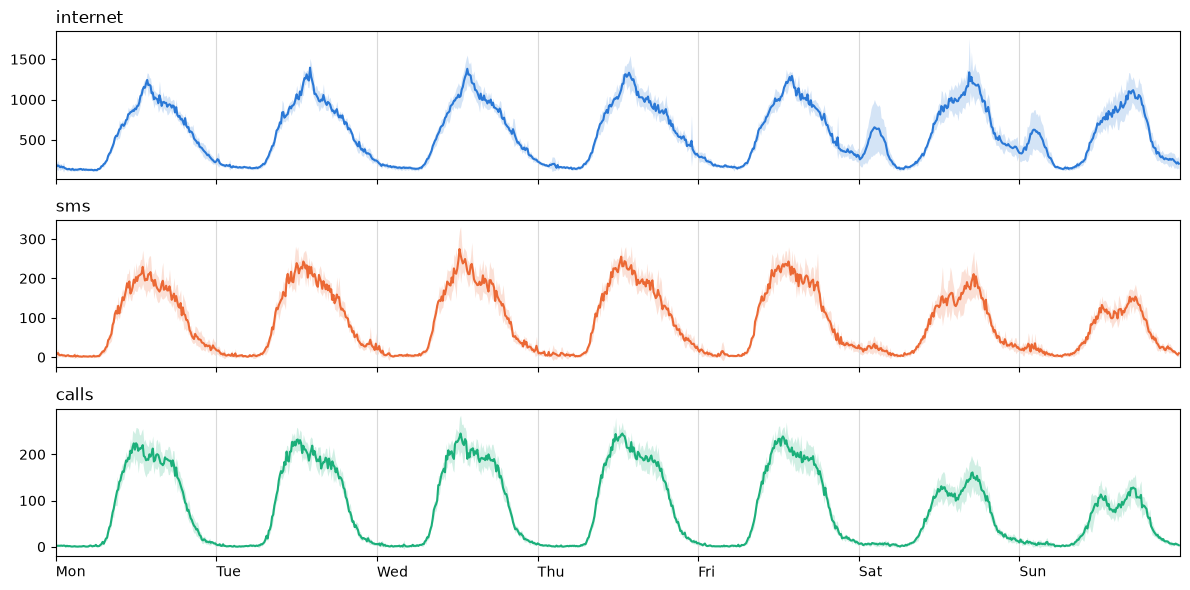

In [5]:
# Mean week (Monday to Sunday) on the train set, holidays left out. Band = one standard deviation
wk = train[~train.index.normalize().isin(HOLIDAYS)]
wk_slot = wk.index.dayofweek * SEASON + wk.index.hour * 6 + wk.index.minute // 10
x = np.arange(7 * SEASON) / SEASON
fig, axes = plt.subplots(3, 1, figsize=(12, 6), sharex=True)
for ax, s in zip(axes, SERIES):
    by_slot = wk[s].groupby(wk_slot)
    mean, std = by_slot.mean().values, by_slot.std().values
    ax.fill_between(x, mean - std, mean + std, color=COLOR[s], alpha=0.2, lw=0)
    ax.plot(x, mean, color=COLOR[s])
    ax.set_title(s, loc="left"); ax.grid(axis="x", color="0.85")
axes[-1].set_xticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], ha="left")
axes[-1].set_xlim(0, 7)
fig.tight_layout(); plt.show()

Μέσο ημερήσιο προφίλ ανά τύπο ημέρας. Για κάθε δεκάλεπτο της ημέρας (slot 0 έως 143) υπολογίζουμε τη μέση τιμή,
χωριστά για εργάσιμες, Σάββατα και Κυριακές ή αργίες. Χρησιμοποιούμε μόνο το train, γιατί αυτά τα προφίλ
καθοδηγούν την επιλογή μοντέλου και δεν πρέπει να «δουν» το test.

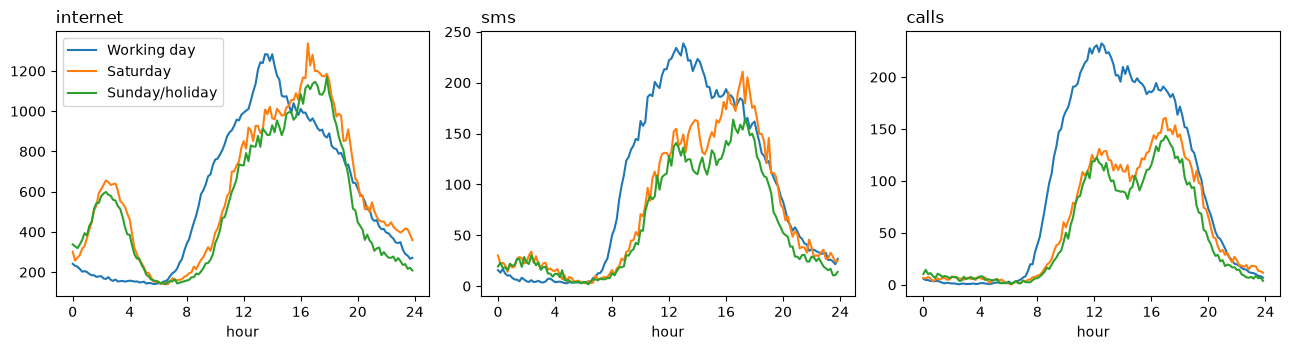

In [6]:
# Mean daily profile per day type (train set only)
tr = train.copy()
tr["slot"] = tr.index.hour * 6 + tr.index.minute // 10
tr["type"] = day_type(tr.index)
names = {0: "Working day", 1: "Saturday", 2: "Sunday/holiday"}
hours = np.arange(SEASON) / 6
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, s in zip(axes, SERIES):
    for k in range(3):
        ax.plot(hours, tr[tr["type"] == k].groupby("slot")[s].mean().values, label=names[k])
    ax.set_title(s, loc="left"); ax.set_xlabel("hour"); ax.set_xticks(range(0, 25, 4))
axes[0].legend()
fig.tight_layout(); plt.show()

Ημερήσια σύνολα. Αθροίζοντας ανά ημέρα εξαφανίζεται ο ημερήσιος κύκλος και μένει ο εβδομαδιαίος ρυθμός και οι
ειδικές ημέρες (γκρι: Σαββατοκύριακα και αργίες).

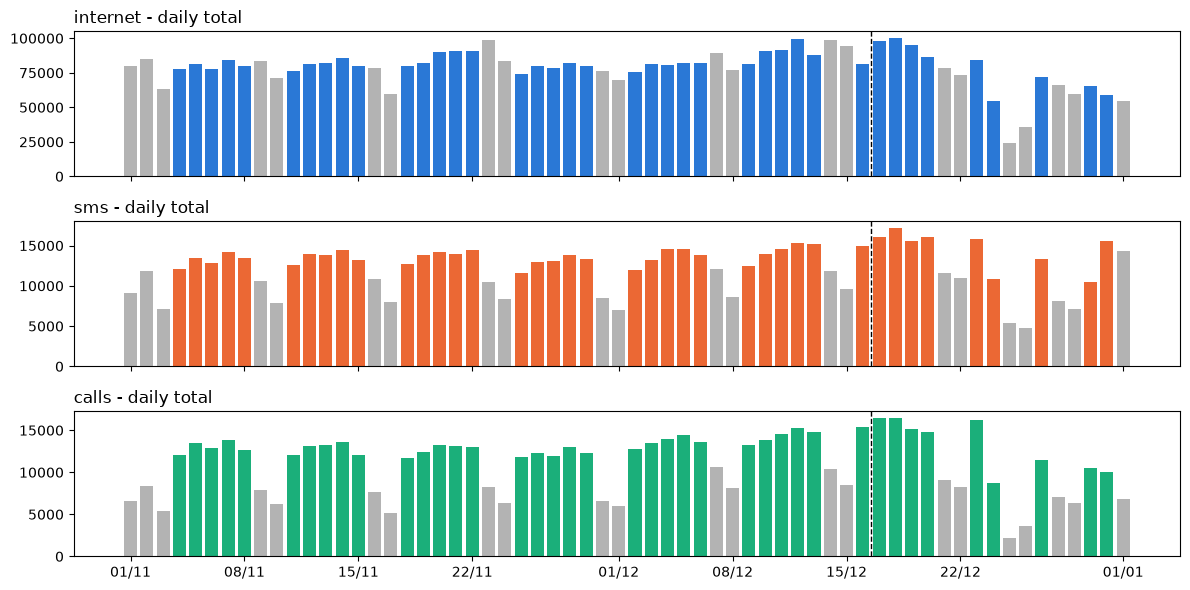

In [7]:
# Daily totals (grey = weekend/holiday)
daily = df.resample("D").sum()
fig, axes = plt.subplots(3, 1, figsize=(12, 6), sharex=True)
for ax, s in zip(axes, SERIES):
    c = ["0.7" if (d.dayofweek >= 5 or d in HOLIDAYS) else COLOR[s] for d in daily.index]
    ax.bar(daily.index, daily[s], color=c, width=0.8)
    ax.axvline(t_split - pd.Timedelta("12h"), color="k", ls="--", lw=1)
    ax.set_title(s + " - daily total", loc="left")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
fig.tight_layout(); plt.show()

Περιγραφικά στατιστικά και συσχέτιση. Η συσχέτιση Pearson δείχνει πόσο ανεβοκατεβαίνουν μαζί οι τρεις σειρές.


In [50]:
# Summary statistics and correlation between the three series
display(df.describe().T)
display(df.corr().round(3))

,count,mean,std,min,25%,50%,75%,max
internet,8928.0,547.156496,376.406598,77.226475,193.706089,438.280193,864.318821,2172.038157
sms,8928.0,84.817577,85.815283,0.003122,11.842894,52.158589,149.550749,1602.041699
calls,8928.0,76.645422,82.094554,0.000000,4.497874,36.834428,146.385241,531.921029


,internet,sms,calls
internet,1.000,0.879,0.900
sms,0.879,1.000,0.925
calls,0.900,0.925,1.000


#### Παρατηρήσεις από την EDA

Χωρίζουμε όσα μετρήσαμε από όσα υποθέτουμε για την αιτία τους. Τα δεδομένα δείχνουν πότε ανεβαίνει η δραστηριότητα, αλλά δεν
περιέχουν το γιατί.

Τι μετρήσαμε:

* Ημερήσιος κύκλος. Και οι τρεις σειρές έχουν ισχυρή ημερήσια περιοδικότητα, γι' αυτό παίρνουμε $s = 144$. Τις εργάσιμες η μέση
  κορυφή είναι στις 12:30 (Calls), 13:00 (SMS) και 13:30 (Internet), και το Internet έχει το ελάχιστό του γύρω στις 05:40.
* Νυχτερινές τιμές. Τα Calls έχουν 200 δεκάλεπτα με τιμή 0 στο train και 120 στο test. Το Internet δεν πέφτει ποτέ κάτω από περίπου 77.
* Εβδομαδιαίος κύκλος. Χωρίς τις αργίες, το μέσο ημερήσιο σύνολο του Σαββατοκύριακου είναι το 55% (Calls), 69% (SMS) και 97%
  (Internet) μιας εργάσιμης. Η κορυφή μετατοπίζεται γύρω στις 16:30 έως 17:10. Από τις 01:00 έως τις 04:00 το Internet είναι τα
  Σάββατα και τις Κυριακές περίπου 3 φορές υψηλότερο από τις εργάσιμες (545 έναντι 170), με μεγάλες διαφορές από εβδομάδα σε
  εβδομάδα.
* Τάση. Δεν φαίνεται, κάτι που θα ελέγξουμε τυπικά αργότερα.
* Συσχέτιση. Οι τρεις σειρές συσχετίζονται έντονα (Pearson 0.88 έως 0.93). Το μεγαλύτερο μέρος της είναι ο κοινός κύκλος: στο train, αν
  αφαιρέσουμε το μέσο προφίλ κάθε τύπου ημέρας, πέφτει από 0.89 έως 0.96 σε 0.34 έως 0.41.
* Γιορτές. Σε σχέση με μια μέση εργάσιμη του train, τα Χριστούγεννα το Internet είναι 71% χαμηλότερο, τα SMS 61% και τα Calls 84%, και
  στις 26/12 56%, 65% και 73% αντίστοιχα.
* Πρωτοχρονιά. Τα μεσάνυχτα εμφανίζεται η μεγαλύτερη αιχμή της σειράς για SMS και Calls: SMS $= 1602$ στις 00:10, περίπου 70
  φορές η μέση τιμή μιας Κυριακής ή αργίας του train την ίδια ώρα (23), και Calls $= 532$ στις 00:00, περίπου 50 φορές (10.5).
  Το Internet φτάνει το 1964 στις 00:10, περίπου 6 φορές (328). Το μέγιστό του σε όλη τη σειρά είναι 2172, στις 02/11 στις 16:30,
  μέσα στο train.

Τι συμπεραίνουμε για τα μοντέλα: ο τύπος ημέρας φαίνεται χρήσιμος ως πληροφορία, π.χ. ως εξωγενής μεταβλητή. Οι γιορτές και οι αιχμές
των SMS και Calls δεν έχουν αντίστοιχο στο train, οπότε περιμένουμε *distribution shift* στο test.

Πιθανές εξηγήσεις, που δεν μπορούμε να ελέγξουμε με αυτά τα δεδομένα:

* Το ελάχιστο του Internet μπορεί να οφείλεται σε background κίνηση των smartphones, που δεν χρειάζεται ενεργό χρήστη.
* Η νυχτερινή άνοδος του Σαββατοκύριακου ταιριάζει με νυχτερινή ζωή στο κέντρο, αλλά μπορεί να έχει και άλλη αιτία.
* Η συσχέτιση θα ταίριαζε με το ότι τις σειρές οδηγεί σε μεγάλο βαθμό το πόσοι άνθρωποι βρίσκονται στην περιοχή.
* Η μεγάλη αιχμή των SMS και Calls τα μεσάνυχτα της Πρωτοχρονιάς είναι λογικό να σχετίζεται με τις ευχές, αλλά τα δεδομένα δεν δείχνουν
  τον λόγο.
* Οι μηδενικές τιμές των Calls μπορεί να είναι πραγματική απουσία κλήσεων ή αποτέλεσμα της υπόθεσης για τα κενά πεδία.


## 2. ARIMA, s-ARIMA, ARIMA-x

### 2.1 Θεωρία

#### 2.1.1 Στασιμότητα: γιατί είναι η βασική προϋπόθεση

Ένα μοντέλο ARIMA εκτιμά σταθερές παραμέτρους από το παρελθόν και τις εφαρμόζει στο μέλλον. Αυτό έχει νόημα μόνο
αν η στατιστική συμπεριφορά της σειράς δεν αλλάζει με τον χρόνο. Αυτή η ιδιότητα λέγεται (ασθενής) στασιμότητα.
Μια σειρά $y_t$ είναι στάσιμη όταν:

$$\mathbb{E}[y_t] = \mu \;\;\text{(σταθερός μέσος)}, \qquad \operatorname{Var}(y_t) = \sigma_y^2 \;\;\text{(σταθερή διασπορά)}, \qquad \operatorname{Cov}(y_t,\, y_{t-k}) = \gamma_k \;\;\text{(εξαρτάται μόνο από το } k\text{)}$$

Αν η σειρά έχει τάση ή «περιπλανιέται» χωρίς να επιστρέφει σε ένα μέσο επίπεδο, τότε ο μέσος όρος που θα μάθει το
μοντέλο από το train δεν θα ισχύει στο test.

Τελεστής υστέρησης. Για να γράφουμε τα μοντέλα σύντομα χρησιμοποιούμε τον τελεστή $B$, που μετακινεί τη σειρά ένα
βήμα πίσω:

$$B\,y_t = y_{t-1}, \qquad B^k y_t = y_{t-k}$$

Με αυτόν ορίζονται η διαφόριση (διαφορά από το προηγούμενο βήμα) και η εποχική διαφόριση (διαφορά από το ίδιο
σημείο της προηγούμενης περιόδου $s$):

$$\nabla y_t = (1 - B)\,y_t = y_t - y_{t-1}, \qquad \nabla_s\, y_t = (1 - B^s)\,y_t = y_t - y_{t-s}$$

Η διαφόριση αφαιρεί μια τάση ή μια «περιπλάνηση» και η εποχική διαφόριση αφαιρεί ένα μοτίβο που επαναλαμβάνεται
κάθε $s$ βήματα. Και οι δύο μετατρέπουν μια μη στάσιμη σειρά σε στάσιμη.

#### 2.1.2 Τα δομικά στοιχεία: AR, MA, ARMA

Σε όλα τα παρακάτω, $\varepsilon_t$ είναι λευκός θόρυβος: ασυσχέτιστες τυχαίες διαταραχές με μέσο 0 και
διασπορά $\sigma^2$. Είναι το «απρόβλεπτο» μέρος κάθε βήματος.

AR(p), αυτοπαλινδρόμηση. Η τρέχουσα τιμή είναι γραμμικός συνδυασμός των $p$ προηγούμενων τιμών:

$$y_t = c + \phi_1 y_{t-1} + \phi_2 y_{t-2} + \dots + \phi_p y_{t-p} + \varepsilon_t
\qquad\Longleftrightarrow\qquad
\phi(B)\,y_t = c + \varepsilon_t, \quad \phi(B) = 1 - \phi_1 B - \dots - \phi_p B^p$$

*Διαίσθηση:* η σειρά «θυμάται» πού βρισκόταν. Αν η κίνηση είναι υψηλή τώρα, θα είναι μάλλον υψηλή και σε 10 λεπτά.

MA(q), κινητός μέσος. Η τρέχουσα τιμή εξαρτάται από τις $q$ προηγούμενες διαταραχές (τα «ξαφνιάσματα»):

$$y_t = \mu + \varepsilon_t + \theta_1 \varepsilon_{t-1} + \dots + \theta_q \varepsilon_{t-q}
\qquad\Longleftrightarrow\qquad
y_t = \mu + \theta(B)\,\varepsilon_t, \quad \theta(B) = 1 + \theta_1 B + \dots + \theta_q B^q$$

*Διαίσθηση:* ένα απρόσμενο γεγονός (π.χ. ένα πλήθος που φτάνει ξαφνικά) επηρεάζει τα επόμενα $q$ βήματα και μετά
ξεχνιέται εντελώς.

ARMA(p, q). Συνδυάζει και τα δύο: $\;\phi(B)\,y_t = c + \theta(B)\,\varepsilon_t$.

Γιατί ARMA και όχι μόνο AR. Ένα ARMA χαμηλής τάξης μπορεί να περιγράψει μια μνήμη που θα χρειαζόταν πολύ μεγάλο
AR. Λιγότερες παράμετροι σημαίνουν πιο σταθερή εκτίμηση και μικρότερο κίνδυνο υπερπροσαρμογής.

Δύο τεχνικές συνθήκες. Το AR μέρος πρέπει να είναι στάσιμο (οι ρίζες του $\phi(z) = 0$ έξω από τον μοναδιαίο
κύκλο) ώστε οι διαταραχές να σβήνουν με τον χρόνο, και το MA μέρος πρέπει να είναι αντιστρέψιμο (οι ρίζες του
$\theta(z) = 0$ έξω από τον μοναδιαίο κύκλο) ώστε τα $\varepsilon_t$ να μπορούν να ανακτηθούν από τις παρατηρήσεις.
Η δεύτερη συνθήκη είναι απαραίτητη για την εκτίμηση που θα χρησιμοποιήσουμε αργότερα.

#### 2.1.3 ARIMA(p, d, q)

Αν η $y_t$ δεν είναι στάσιμη, τη διαφορίζουμε $d$ φορές και εφαρμόζουμε ARMA στο αποτέλεσμα. Το «I» (*Integrated*)
δηλώνει ακριβώς αυτό:

$$\phi(B)\,(1 - B)^d\, y_t = c + \theta(B)\,\varepsilon_t$$

Οι τρεις υπερπαράμετροι και πώς εκτιμώνται a priori (τα εφαρμόζουμε στη συνέχεια):

| Υπερπαράμετρος | Σημασία | Πώς την εκτιμούμε |
|:---|:---|:---|
| $d$ | πόσες διαφορίσεις χρειάζονται για στασιμότητα | τεστ ADF και KPSS, και η μορφή της ACF |
| $p$ | πόσες προηγούμενες τιμές (AR) | η PACF της στάσιμης σειράς |
| $q$ | πόσες προηγούμενες διαταραχές (MA) | η ACF της στάσιμης σειράς |

Οι γραφικές εκτιμήσεις δίνουν ένα εύρος τιμών. Η τελική επιλογή μέσα σε αυτό το εύρος γίνεται με κριτήριο
πληροφορίας (BIC), που θα δούμε αργότερα.

#### 2.1.4 Seasonal ARIMA: s-ARIMA(p, d, q)(P, D, Q)$_s$

Η EDA έδειξε ότι η σειρά επαναλαμβάνεται κάθε $s = 144$ βήματα (μία ημέρα). Ένα απλό ARIMA θα χρειαζόταν όρους μέχρι
το lag 144 για να το περιγράψει. Το s-ARIMA προσθέτει εποχικά πολυώνυμα στο $B^s$:

$$\phi(B)\,\Phi(B^s)\,(1 - B)^d\,(1 - B^s)^D\, y_t \;=\; c + \theta(B)\,\Theta(B^s)\,\varepsilon_t$$

* $\Phi(B^s) = 1 - \Phi_1 B^s - \dots - \Phi_P B^{Ps}$ και $\Theta(B^s) = 1 + \Theta_1 B^s + \dots + \Theta_Q B^{Qs}$
  συνδέουν την τιμή με τις τιμές και τις διαταραχές της ίδιας ώρας τις προηγούμενες ημέρες.
* $D$ είναι το πλήθος των εποχικών διαφορίσεων. Για παράδειγμα, με $s = 144$ και $D = 1$ μοντελοποιούμε τη διαφορά
  $\nabla_{144}\, y_t = y_t - y_{t-144}$, δηλαδή «πόσο διαφέρει η κίνηση από χθες την ίδια ώρα». Αυτό αφαιρεί το
  ημερήσιο μοτίβο.
* Το μοντέλο είναι πολλαπλασιαστικό: τα γινόμενα όπως $\theta(B)\,\Theta(B^s)$ δημιουργούν όρους αλληλεπίδρασης
  (π.χ. στο lag $s + 1$) με λίγες μόνο παραμέτρους.
* Τα $P, Q$ διαβάζονται από την ACF/PACF στα πολλαπλάσια της περιόδου: lags 144, 288, 432, ...

#### 2.1.5 ARIMA-x: ARIMA με εξωγενείς μεταβλητές

Εδώ η σειρά γράφεται ως παλινδρόμηση σε γνωστές μεταβλητές $x_t$, με σφάλματα που ακολουθούν ARIMA:

$$y_t = c + \beta^\top x_t + u_t, \qquad u_t \sim \text{ARIMA}(p, d, q)$$

Το $\beta^\top x_t$ περιγράφει το προβλέψιμο, ντετερμινιστικό μέρος (π.χ. το ημερήσιο σχήμα) και το ARIMA περιγράφει
ό,τι μένει. Ως $x_t$ χρησιμοποιούμε δείκτες περιοδικότητας, που έχουν ένα κρίσιμο πλεονέκτημα: είναι γνωστοί
εκ των προτέρων για κάθε μελλοντική στιγμή (ξέρουμε τι ώρα και τι μέρα θα είναι), άρα δεν χρειάζεται να τους
προβλέψουμε.

Όροι Fourier. Κάθε περιοδική συνάρτηση με περίοδο $m$ γράφεται ως άθροισμα ημιτόνων και συνημιτόνων:

$$\sum_{k=1}^{K} \Big[\, a_k \sin\!\Big(\frac{2\pi k\, \tau_t}{m}\Big) + b_k \cos\!\Big(\frac{2\pi k\, \tau_t}{m}\Big) \Big]$$

όπου $\tau_t$ η θέση του $t$ μέσα στην περίοδο. Χρησιμοποιούμε $m = 144$ (ημερήσιος κύκλος) και $m = 1008$
(εβδομαδιαίος κύκλος, $7 \times 144$). Το $K$ ελέγχει πόσο λεπτομερές είναι το σχήμα: μικρό $K$ δίνει ομαλή καμπύλη.

Γιατί Fourier και όχι μόνο s-ARIMA. Ένα s-ARIMA με $s = 1008$ για τον εβδομαδιαίο κύκλο θα ήταν πρακτικά αδύνατο
να εκτιμηθεί (πολυώνυμα βαθμού πάνω από 1000). Οι όροι Fourier περιγράφουν την ίδια περιοδικότητα με λίγες
παραμέτρους ($2K$ ανά περίοδο). Επιπλέον, με έναν δείκτη μη εργάσιμης ημέρας μπορούμε να πούμε στο μοντέλο ότι η
Κυριακή έχει διαφορετικό σχήμα από τη Δευτέρα, κάτι που το s-ARIMA δεν μπορεί να κάνει.

### 2.2 Έλεγχοι στασιμότητας (ADF, KPSS): εκτίμηση του $d$

#### Μοναδιαία ρίζα

Η πιο συνηθισμένη μορφή μη στασιμότητας φαίνεται στο απλό μοντέλο

$$y_t = \rho\, y_{t-1} + \varepsilon_t$$

* Αν $|\rho| < 1$, κάθε διαταραχή σβήνει σταδιακά και η σειρά επιστρέφει στον μέσο της: στάσιμη.
* Αν $\rho = 1$, κάθε διαταραχή μένει για πάντα και η σειρά περιπλανιέται (*random walk*): μη στάσιμη. Αυτό
  λέγεται μοναδιαία ρίζα και διορθώνεται με μία διαφόριση, αφού τότε $\nabla y_t = \varepsilon_t$.

Άρα το ερώτημα «χρειάζεται διαφόριση;» είναι ισοδύναμο με το «έχει η σειρά μοναδιαία ρίζα;».

#### ADF (Augmented Dickey-Fuller)

Εκτιμά την παλινδρόμηση

$$\nabla y_t = \alpha + \gamma\, y_{t-1} + \sum_{i=1}^{\ell} \delta_i\, \nabla y_{t-i} + \varepsilon_t$$

όπου $\gamma = \rho - 1$. Οι όροι $\nabla y_{t-i}$ (το «augmented») απορροφούν τη βραχυπρόθεσμη αυτοσυσχέτιση, ώστε το
τεστ να είναι έγκυρο και όταν η σειρά δεν είναι απλό AR(1). Το πλήθος τους $\ell$ επιλέγεται με AIC.

* H0: $\gamma = 0$, δηλαδή υπάρχει μοναδιαία ρίζα (μη στάσιμη).
* $p < 0.05$: απορρίπτουμε την H0, άρα η σειρά είναι στάσιμη.

#### KPSS (Kwiatkowski-Phillips-Schmidt-Shin)

Γράφει τη σειρά ως άθροισμα ενός random walk και ενός στάσιμου μέρους:

$$y_t = r_t + \eta_t, \qquad r_t = r_{t-1} + v_t, \quad \operatorname{Var}(v_t) = \sigma_v^2$$

* H0: $\sigma_v^2 = 0$, δηλαδή το random walk είναι σταθερό και η σειρά είναι στάσιμη.
* $p < 0.05$: απορρίπτουμε την H0, άρα η σειρά είναι μη στάσιμη.

#### Γιατί χρειαζόμαστε και τα δύο

Ένα τεστ υποθέσεων μπορεί μόνο να απορρίψει την H0, ποτέ να την αποδείξει. Το ADF μάλιστα έχει μικρή ισχύ: συχνά
δεν απορρίπτει ακόμη και όταν η σειρά είναι στάσιμη. Τα δύο τεστ έχουν αντίθετες μηδενικές υποθέσεις, οπότε όταν
συμφωνούν το συμπέρασμα είναι αξιόπιστο:

| ADF $p$ | KPSS $p$ | Συμπέρασμα |
|:---:|:---:|:---|
| $< 0.05$ | $> 0.05$ | στάσιμη (συμφωνούν) |
| $> 0.05$ | $< 0.05$ | μη στάσιμη (συμφωνούν), χρειάζεται διαφόριση |
| $< 0.05$ | $< 0.05$ | αντικρουόμενα (συχνά στάσιμη γύρω από τάση) |
| $> 0.05$ | $> 0.05$ | ανεπαρκή στοιχεία |

#### Τι ελέγχουμε

Εφαρμόζουμε τα τεστ στην $y_t$, στην $\nabla y_t$, στην $\nabla_{144}\, y_t$ και στην $\nabla \nabla_{144}\, y_t$. Η
απλούστερη μορφή που βγαίνει στάσιμη δίνει το $d$. Τα τεστ γίνονται μόνο στο train set, ώστε η
επιλογή του μοντέλου να μη «βλέπει» το test.

*Τεχνική σημείωση:* το `statsmodels` δίνει p-values για το KPSS μόνο στο διάστημα $[0.01,\, 0.1]$ (από πίνακα κρίσιμων
τιμών). Μια τιμή 0.1 σημαίνει «0.1 ή μεγαλύτερη».

In [9]:
import warnings
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

Y = {s: df[s].values.astype(float) for s in SERIES}

def stationarity_table(y):
    ys = pd.Series(y)
    rows = []
    for name, z in {"y": ys, "d1(y)": ys.diff(), "d144(y)": ys.diff(SEASON),
                    "d1(d144(y))": ys.diff(SEASON).diff()}.items():
        z = z.dropna().values
        with warnings.catch_warnings():         # FutureWarnings + KPSS p-value outside the lookup table
            warnings.simplefilter("ignore")
            adf_stat, adf_p, *_ = adfuller(z, autolag="AIC")
            kpss_stat, kpss_p, *_ = kpss(z, regression="c", nlags="auto")
        rows.append({"series": name, "ADF stat": adf_stat, "ADF p": adf_p,
                     "KPSS stat": kpss_stat, "KPSS p": kpss_p,
                     "conclusion": "stationary" if (adf_p < 0.05 and kpss_p > 0.05) else
                                   ("ambiguous" if (adf_p < 0.05) == (kpss_p < 0.05) else "non-stationary")})
    return pd.DataFrame(rows)


for s in SERIES:
    print(f"\n=== {s} ===  (KPSS p-values are bounded to [0.01, 0.1])")
    display(stationarity_table(Y[s][:n_train]))


=== internet ===  (KPSS p-values are bounded to [0.01, 0.1])


,series,ADF stat,ADF p,KPSS stat,KPSS p,conclusion
0,y,-16.988509,8.904673e-30,0.111048,0.1,stationary
1,d1(y),-13.407905,4.432758e-25,0.003744,0.1,stationary
2,d144(y),-12.733859,9.250838e-24,0.017651,0.1,stationary
3,d1(d144(y)),-16.435145,2.457400e-29,0.003739,0.1,stationary



=== sms ===  (KPSS p-values are bounded to [0.01, 0.1])


,series,ADF stat,ADF p,KPSS stat,KPSS p,conclusion
0,y,-16.220950,3.898405e-29,0.053198,0.1,stationary
1,d1(y),-14.287563,1.292081e-26,0.007418,0.1,stationary
2,d144(y),-9.587682,2.076050e-16,0.029130,0.1,stationary
3,d1(d144(y)),-27.418437,0.000000e+00,0.041643,0.1,stationary



=== calls ===  (KPSS p-values are bounded to [0.01, 0.1])


,series,ADF stat,ADF p,KPSS stat,KPSS p,conclusion
0,y,-16.927188,9.838981e-30,0.139151,0.1,stationary
1,d1(y),-11.247188,1.747800e-20,0.004341,0.1,stationary
2,d144(y),-9.877710,3.842883e-17,0.036924,0.1,stationary
3,d1(d144(y)),-16.912415,1.008316e-29,0.008494,0.1,stationary


#### Ερμηνεία των τεστ στασιμότητας

Και στις τρεις σειρές το ADF δίνει $p < 10^{-28}$ στην $y_t$, δηλαδή απορρίπτει έντονα τη μοναδιαία ρίζα, και το
στατιστικό KPSS είναι 0.05 έως 0.14, πολύ κάτω από την κρίσιμη τιμή 0.463 του 5%. Τα δύο τεστ συμφωνούν ότι η σειρά
δεν έχει μοναδιαία ρίζα (τάση ή περιπλάνηση), άρα δεν χρειάζεται απλή διαφόριση: $d = 0$.

Οι διαφορισμένες μορφές βγαίνουν επίσης στάσιμες, αλλά αυτό δεν σημαίνει ότι η διαφόριση χρειάζεται: μια ήδη
στάσιμη σειρά μένει στάσιμη αν τη διαφορίσουμε, με περιττή πολυπλοκότητα (υπερ-διαφόριση, που δημιουργεί ένα μη
αντιστρέψιμο MA). Κρατάμε τη μικρότερη διαφόριση που αρκεί.

Τα ADF και KPSS ελέγχουν μοναδιαία ρίζα στη «μηδενική συχνότητα», δηλαδή μια μακροπρόθεσμη τάση ή περιπλάνηση, και
είναι τυφλά στην εποχικότητα: μια σειρά που ανεβαίνει και κατεβαίνει κανονικά κάθε μέρα βγαίνει στάσιμη για αυτά.
Άρα «στάσιμη» εδώ σημαίνει μόνο «χωρίς μοναδιαία ρίζα». Ο μέσος της σειράς αλλάζει με την ώρα της ημέρας, οπότε
με τον αυστηρό ορισμό της 2.1.1 η $y_t$ δεν είναι στάσιμη.
Το αν χρειάζεται εποχική διαφόριση ($D$) θα το κρίνουμε από την ACF στην επόμενη ενότητα.

### 2.3 Γραφήματα ACF / PACF: εκτίμηση των $D$, $P, Q$ και $p, q$

#### Ορισμοί

ACF (συνάρτηση αυτοσυσχέτισης). Η συσχέτιση της σειράς με τον εαυτό της μετατοπισμένη κατά $k$ βήματα:

$$r_k \;=\; \frac{\displaystyle\sum_{t=k+1}^{n} (y_t - \bar y)(y_{t-k} - \bar y)}{\displaystyle\sum_{t=1}^{n} (y_t - \bar y)^2}$$

Για παράδειγμα, το $r_{144}$ απαντά στο «πόσο μοιάζει η κίνηση τώρα με την κίνηση χθες την ίδια ώρα;».

PACF (μερική αυτοσυσχέτιση). Η συσχέτιση της $y_t$ με την $y_{t-k}$ αφού αφαιρεθεί η επίδραση των ενδιάμεσων
lags $1, \dots, k-1$. Τυπικά, είναι ο τελευταίος συντελεστής $\phi_{kk}$ όταν εκτιμάμε ένα AR($k$):

$$y_t = \phi_{k1}\, y_{t-1} + \dots + \phi_{kk}\, y_{t-k} + e_t$$

*Γιατί χρειάζεται:* αν το $y_{t-1}$ επηρεάζει το $y_t$ και το $y_{t-2}$ επηρεάζει το $y_{t-1}$, τότε το $y_{t-2}$ θα
φαίνεται συσχετισμένο με το $y_t$ ακόμη κι αν δεν έχει άμεση επίδραση. Η ACF μετράει και αυτή την έμμεση σύνδεση, η
PACF κρατά μόνο την άμεση.

Ζώνη εμπιστοσύνης. Αν η σειρά ήταν λευκός θόρυβος, κάθε $r_k$ θα ήταν περίπου κανονικό με μέσο 0 και διασπορά
$1/n$, δηλαδή τυπική απόκλιση $1/\sqrt{n}$. Μια κανονική μεταβλητή απέχει έως 1.96 τυπικές αποκλίσεις από τον μέσο
της με πιθανότητα 95%. Άρα για λευκό θόρυβο περίπου το 95% των $r_k$ πέφτει μέσα στη ζώνη $\pm 1.96/\sqrt{n}$ (εδώ
περίπου $\pm 0.024$), και τιμές μέσα σε αυτήν δεν διακρίνονται στατιστικά από το μηδέν.

Αυτή είναι η ζώνη στα γραφήματα της PACF. Στα γραφήματα της ACF το `statsmodels` σχεδιάζει τη ζώνη του Bartlett,
που είναι φαρδύτερη και μεγαλώνει με το lag, γιατί λαμβάνει υπόψη τις προηγούμενες αυτοσυσχετίσεις. Στους πίνακες
της ερμηνείας χρησιμοποιούμε τη ζώνη $\pm 0.024$.

#### Κανόνες ανάγνωσης (Box-Jenkins)

| Τι βλέπουμε | Τι σημαίνει |
|:---|:---|
| ACF φθίνει πολύ αργά, σχεδόν γραμμικά | μη στασιμότητα, χρειάζεται διαφόριση |
| ACF με κορυφές στα $s, 2s, 3s, \dots$ που φθίνουν αργά | ισχυρή εποχικότητα, χρειάζεται $D = 1$ |
| PACF μηδενίζεται απότομα μετά το lag $p$, ACF φθίνει σταδιακά | AR($p$) |
| ACF μηδενίζεται απότομα μετά το lag $q$, PACF φθίνει σταδιακά | MA($q$) |
| και οι δύο φθίνουν σταδιακά | μικτό ARMA, μικρά $p, q$ και επιβεβαίωση με BIC |
| αρνητική ακίδα στο lag $s$ της ACF (μετά από $\nabla_s$) και τίποτα στα $2s, 3s, \dots$ | εποχικό MA(1), δηλαδή $Q = 1$ |
| ACF στα $s, 2s, 3s, \dots$ που φθίνει σταδιακά, PACF με ακίδα μόνο στο $s$ (μετά από $\nabla_s$) | εποχικό AR(1), δηλαδή $P = 1$ |
| ACF στο lag 1 κοντά στο $-0.5$ μετά από διαφόριση | υπερ-διαφόριση |

#### Τι δείχνει κάθε γράφημα, και γιατί

Για κάθε σειρά σχεδιάζουμε τέσσερα πάνελ (μόνο στο train):
1. ACF της $y$ ως 3 ημέρες: υπάρχει εποχικότητα; (κορυφές στα 144, 288, 432)
2. ACF της $\nabla_{144}\, y$ ως 2 ημέρες: έφυγε η εποχικότητα μετά την εποχική διαφόριση; τι γίνεται στο lag 144;
3. ACF και 4. PACF της $\nabla_{144}\, y$ για lags 0 έως 36: η βραχυπρόθεσμη δομή, από την οποία διαβάζουμε
   τα $p$ και $q$.

Διαβάζουμε τα $p, q$ από την $\nabla_{144}\, y$ και όχι από την $y$, γιατί στην $y$ το ισχυρό ημερήσιο μοτίβο κυριαρχεί
στην ACF και κρύβει τη βραχυπρόθεσμη δομή.

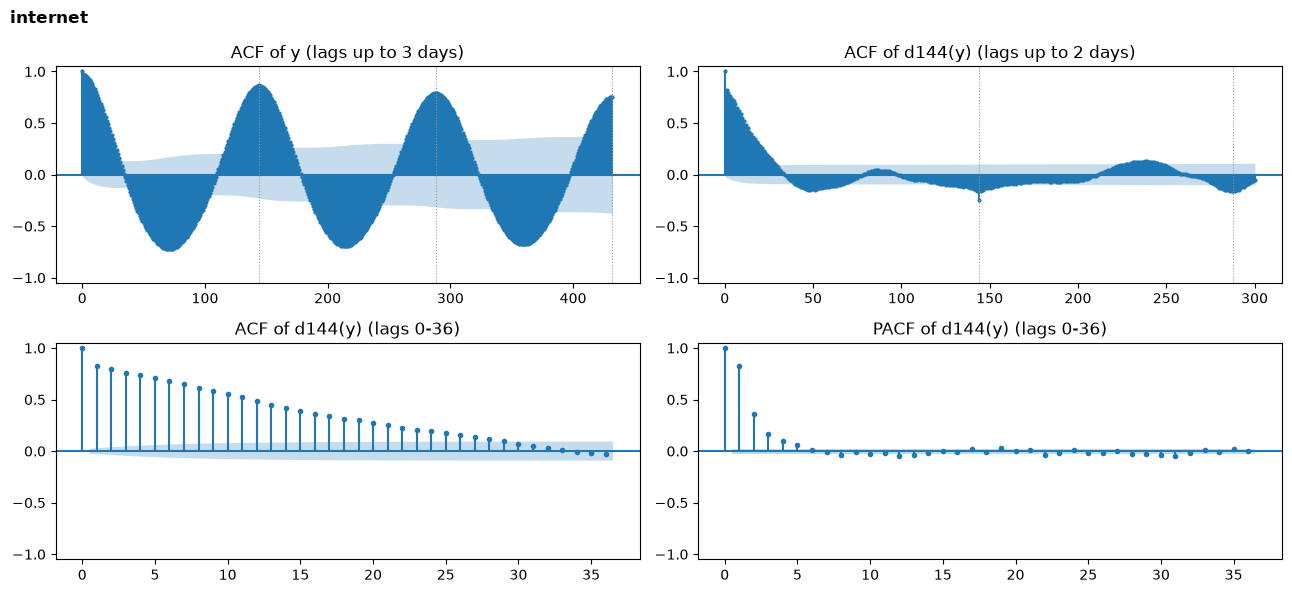

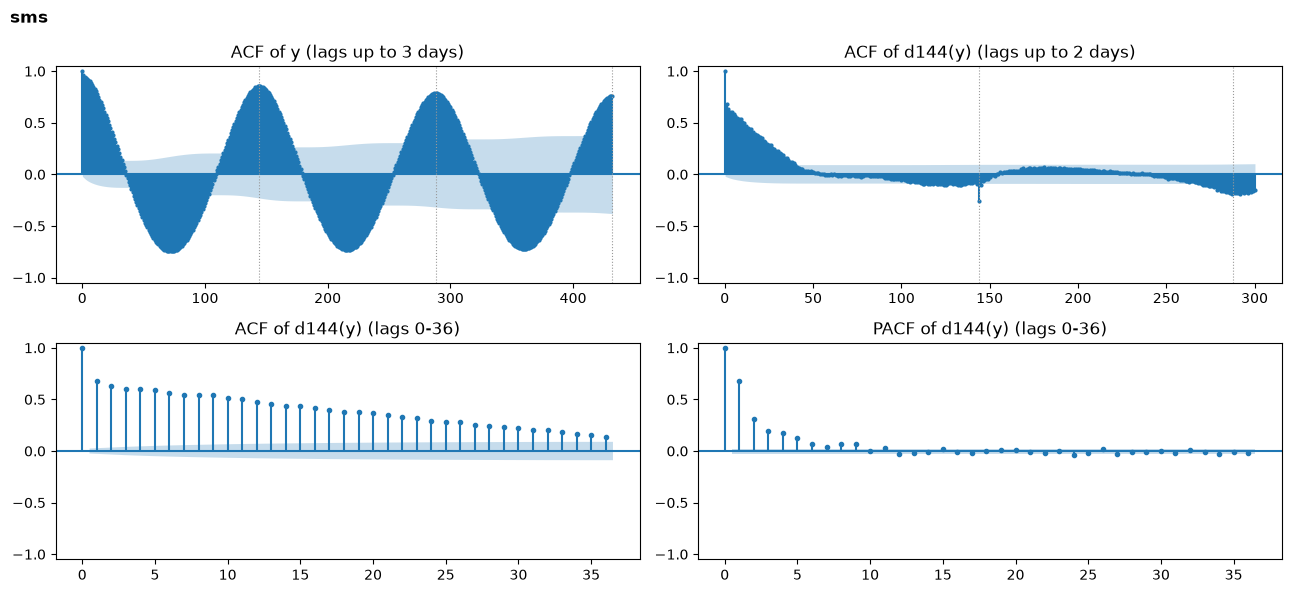

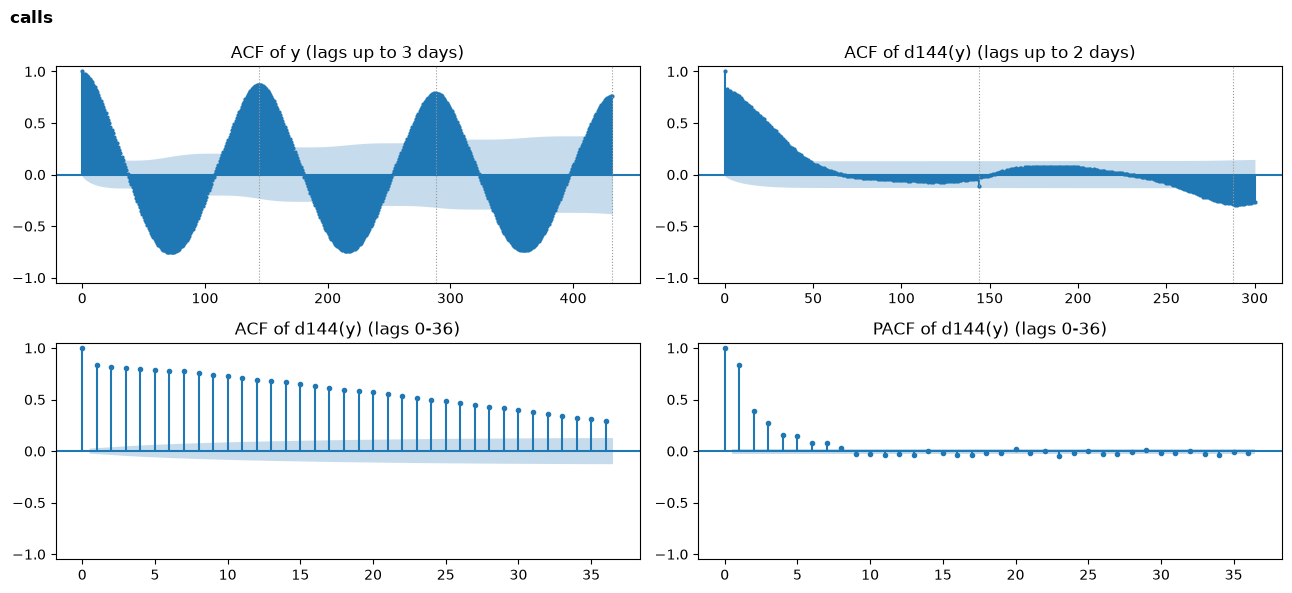

In [10]:
# y: daily seasonality? d144(y): what is left after removing it (p, q, P, Q)
for s in SERIES:
    y = pd.Series(Y[s][:n_train])
    ds = y.diff(SEASON).dropna()
    fig, axes = plt.subplots(2, 2, figsize=(13, 6))
    plot_acf(y, lags=3 * SEASON, ax=axes[0, 0], markersize=2, title="ACF of y (lags up to 3 days)")
    plot_acf(ds, lags=2 * SEASON + 12, ax=axes[0, 1], markersize=2, title="ACF of d144(y) (lags up to 2 days)")
    plot_acf(ds, lags=36, ax=axes[1, 0], markersize=3, title="ACF of d144(y) (lags 0-36)")
    plot_pacf(ds, lags=36, ax=axes[1, 1], markersize=3, method="ywm", title="PACF of d144(y) (lags 0-36)")
    for ax in axes.flat:
        ax.set_ylim(-1.05, 1.05)
    for ax in axes[0]:
        for k in range(SEASON, int(ax.get_xlim()[1]), SEASON):
            ax.axvline(k, color="0.6", ls=":", lw=0.8)
    fig.suptitle(s, x=0.01, ha="left", fontweight="bold")
    fig.tight_layout(); plt.show()

#### Ερμηνεία των ACF / PACF

| | Internet | SMS | Calls |
|:---|:---:|:---:|:---:|
| ACF της $y$ στα lags 144, 288, 432 | 0.87, 0.79, 0.75 | 0.86, 0.79, 0.76 | 0.87, 0.79, 0.76 |
| ACF της $\nabla_{144} y$: πρώτο lag μέσα στη ζώνη $\pm 0.024$ | 33 | 50 | 62 |
| ACF της $\nabla_{144} y$ στα lags 144, 288 | $-0.25$, $-0.15$ | $-0.25$, $-0.17$ | $-0.11$, $-0.29$ |
| PACF της $\nabla_{144} y$, lags 1 έως 4 | 0.82, 0.36, 0.16, 0.10 | 0.68, 0.31, 0.20, 0.17 | 0.83, 0.39, 0.27, 0.16 |

Η ACF της $y$ έχει κορυφές στα 144, 288, 432 που σχεδόν δεν μειώνονται. Το ημερήσιο μοτίβο είναι σχεδόν σταθερό και ένα
ARMA χαμηλής τάξης δεν μπορεί να το περιγράψει. Χρειάζεται λοιπόν εποχική διαφόριση, $D = 1$ με $s = 144$, ή όροι Fourier
όπως στο ARIMA-x. Για τον ίδιο λόγο δεν εκτιμούμε καθαρό ARIMA, που όπως προβλέπει και η εκφώνηση θα αποτύγχανε εδώ.

Η ACF της $\nabla_{144}\, y$ φθίνει ομαλά και μπαίνει στη ζώνη μετά από 33 έως 62 lags, άρα δεν χρειάζεται επιπλέον $d$.

Στα εποχικά lags η εικόνα δεν είναι καθαρή. Στο lag 144 υπάρχει αρνητική ακίδα, όπως θα έδινε ένα εποχικό MA(1). Ένα καθαρό
εποχικό MA(1) όμως θα είχε μόνο αυτή την ακίδα, ενώ εδώ η ACF στο 288 δεν μηδενίζεται, και στα Calls είναι μάλιστα μεγαλύτερη
από ό,τι στο 144. Τα γραφήματα φτάνουν μόνο ως το 288, οπότε δεν μπορούμε να πούμε αν η ACF συνεχίζει να φθίνει (εποχικό AR) ή
αν πρόκειται για κάτι άλλο, π.χ. τη διαφορά εργάσιμης και Σαββατοκύριακου που η $\nabla_{144}$ δεν αφαιρεί (υπόθεση). Κρατάμε την
απλούστερη επιλογή, $P = 0$ και $Q = 1$, που είναι και το εποχικό μέρος του κλασικού «airline» μοντέλου των Box-Jenkins. Άλλες
τιμές των $P, Q$ δεν δοκιμάζουμε, γιατί κάθε fit του SARIMA κρατά περίπου 22 λεπτά.

Η PACF της $\nabla_{144}\, y$ έχει μεγάλες τιμές στα πρώτα 4 έως 5 lags και μετά μικρές, κάτω από 0.1, αν και αρκετές βγαίνουν
ακόμη λίγο έξω από τη ζώνη. Η ACF αντίθετα φθίνει σταδιακά. Η εικόνα μοιάζει περισσότερο με AR($p$) με $p \approx 4$ έως $6$
και $q = 0$, αλλά η PACF δεν μηδενίζεται απότομα, οπότε ένα μικρό ARMA δεν αποκλείεται. Αυτό θα το κρίνει αργότερα το BIC.


### 2.4 Υποψήφια μοντέλα

Η καθαρή ARIMA δεν μπορεί να περιγράψει το ημερήσιο μοτίβο που έδειξε η ACF, όπως προβλέπει και η εκφώνηση, οπότε
εξετάζουμε τις δύο μορφές που το περιλαμβάνουν. Από τις ενότητες 2.2 και 2.3 προκύπτουν:

| Μοντέλο | $d$ | $D$ | $P$ | $Q$ | $p$ | $q$ | Από πού |
|:---|:---:|:---:|:---:|:---:|:---:|:---:|:---|
| SARIMA | 0 | 1 | 0 | 1 | 4 έως 6 | 0 (ή μικρό) | $d$: ADF/KPSS. $D$: κορυφές της ACF στα 144, 288, 432 που φθίνουν αργά. $Q$: ακίδα της ACF της $\nabla_{144} y$ στο 144, με $P = 0$ ως η απλούστερη επιλογή. $p, q$: PACF και ACF της $\nabla_{144} y$. |
| ARIMA-x | 0 | – | – | – | μικρό | μικρό | Οι όροι Fourier αναλαμβάνουν την περιοδικότητα. Την ACF των καταλοίπων της παλινδρόμησης δεν τη σχεδιάσαμε, οπότε δοκιμάζουμε μικρές τάξεις. |

Με αυτές τις τιμές το SARIMA γράφεται:

$$\phi(B)\,(1 - B^{144})\, y_t \;=\; \theta(B)\,(1 + \Theta_1 B^{144})\,\varepsilon_t$$

Στον κώδικα κάνουμε πρώτα τη διαφόριση, $z_t = (1 - B^{144})\, y_t = y_t - y_{t-144}$, και εκτιμούμε στη $z_t$ το υπόλοιπο μέρος,
$\phi(B)\, z_t = \theta(B)\,(1 + \Theta_1 B^{144})\,\varepsilon_t$.

Οι εξωτερικές μεταβλητές $x_t$ του ARIMA-x είναι:

* ημερήσιοι όροι Fourier ($K = 4$, περίοδος 144), για το σχήμα της ημέρας,
* εβδομαδιαίοι όροι Fourier ($K = 2$, περίοδος 1008), για τις διαφορές ανάμεσα στις ημέρες,
* ο δείκτης `offday`: 1 για Κυριακή ή αργία, 0.5 για Σάββατο, 0 για εργάσιμη,
* τα γινόμενα του `offday` με τους 2 πρώτους ημερήσιους όρους, ώστε τις μη εργάσιμες να αλλάζει το σχήμα της ημέρας
  και όχι μόνο το επίπεδο.


In [11]:
WEEK = 7 * SEASON                              # 1008 ten-minute steps


def exog_matrix(idx, k_day=4, k_week=2, k_off=2):
    """Periodicity regressors for ARIMA-x, all known in advance for any future time."""
    slot = (idx.hour * 6 + idx.minute // 10).values
    wpos = idx.dayofweek.values * SEASON + slot
    dt = day_type(idx)
    off = (dt == 2).astype(float) + 0.5 * (dt == 1)   # Sunday/holiday = 1, Saturday = 0.5
    cols = {"const": np.ones(len(idx)), "offday": off}
    for k in range(1, k_day + 1):
        sd, cd = np.sin(2 * np.pi * k * slot / SEASON), np.cos(2 * np.pi * k * slot / SEASON)
        cols[f"d_sin{k}"], cols[f"d_cos{k}"] = sd, cd
        if k <= k_off:
            cols[f"off_sin{k}"], cols[f"off_cos{k}"] = off * sd, off * cd
    for k in range(1, k_week + 1):
        cols[f"w_sin{k}"] = np.sin(2 * np.pi * k * wpos / WEEK)
        cols[f"w_cos{k}"] = np.cos(2 * np.pi * k * wpos / WEEK)
    return pd.DataFrame(cols, index=idx)


X_EXOG = exog_matrix(df.index).values
print("ARIMA-x inputs:", list(exog_matrix(df.index).columns))

ARIMA-x inputs: ['const', 'offday', 'd_sin1', 'd_cos1', 'off_sin1', 'off_cos1', 'd_sin2', 'd_cos2', 'off_sin2', 'off_cos2', 'd_sin3', 'd_cos3', 'd_sin4', 'd_cos4', 'w_sin1', 'w_cos1', 'w_sin2', 'w_cos2']


### 2.5 Εκτίμηση των παραμέτρων και επιλογή τάξης με BIC

Για κάθε υποψήφια τάξη $(p, q)$ μένει να βρούμε τις τιμές των $\phi, \theta, \Theta$ (και των $\beta$ στο
ARIMA-x). Χρησιμοποιούμε το `SARIMAX` του `statsmodels`, που τις εκτιμά με μέγιστη πιθανοφάνεια (MLE): διαλέγει
τις παραμέτρους με τις οποίες τα δεδομένα που παρατηρήσαμε είναι πιο πιθανά. Με κανονικά σφάλματα αυτό είναι
περίπου το ίδιο με το να ελαχιστοποιούμε το $\sum_t \varepsilon_t^2$, δηλαδή τα σφάλματα πρόβλεψης ενός βήματος στο
train.

Το `SARIMAX` γράφει το μοντέλο σε μορφή state-space: ένα διάνυσμα κατάστασης $a_t$ κρατά ό,τι χρειάζεται από το
παρελθόν, και το Kalman filter το ενημερώνει με κάθε νέα τιμή:

$$\hat z_t = Z\,a_t, \qquad a_{t+1} = T\,a_t + K_t\,(z_t - \hat z_t)$$

όπου $z_t$ η σειρά που μοντελοποιούμε. Οι πίνακες $Z, T$ προκύπτουν από τις παραμέτρους. Την ίδια μορφή
χρησιμοποιούμε αργότερα και για την πρόβλεψη.

Κάνουμε την εποχική διαφόριση μόνοι μας (`seasonal_diff`) και δίνουμε στο μοντέλο τη $z_t$. Έτσι η κατάσταση έχει περίπου 146
διαστάσεις αντί για 290 και χάνονται μόνο οι πρώτες 144 τιμές. Παρ' όλα αυτά κάθε fit του SARIMA κράτησε κατά μέσο όρο περίπου
22 λεπτά, ενώ του ARIMA-x, που έχει πολύ μικρότερη κατάσταση, περίπου 11 δευτερόλεπτα. Γι' αυτό τα αποτελέσματα αποθηκεύονται
στο `results/arima_grid` και το κελί ξανατρέχει άμεσα.

Τα ACF/PACF δίνουν ένα εύρος και όχι μία τιμή, οπότε η τελική τάξη επιλέγεται με το BIC στο train:

$$\text{BIC} = -2 \ln L + k \ln n$$

Το $L$ είναι η πιθανοφάνεια και το $k$ το πλήθος των παραμέτρων. Μικρότερο BIC σημαίνει καλύτερη ισορροπία ανάμεσα
στην προσαρμογή και στην πολυπλοκότητα. Δοκιμάζουμε ένα μικρό πλέγμα γύρω από τα εύρη της 2.4:
$p \in \{2, 4, 6\}$, $q \in \{0, 1\}$ για το SARIMA (το $p = 2$ για την περίπτωση που αρκεί ένα μικρό ARMA) και $p \in \{1, 2, 4\}$, $q \in \{0, 1\}$ για το ARIMA-x,
δηλαδή 6 fits ανά μοντέλο και σειρά.

In [12]:
import glob, json, os, time
from joblib import Parallel, delayed
from statsmodels.tsa.statespace.sarimax import SARIMAX

GRID_DIR = "results/arima_grid"                # one JSON per fit: rerunning continues where it stopped
RETRAIN_ARIMA = False
FAMILIES = {"SARIMA": (None, (2, 4, 6), (0, 1)),    # name: (inputs, p values, q values)
            "ARIMA-x": (X_EXOG, (1, 2, 4), (0, 1))}


def seasonal_diff(y):
    return y[SEASON:] - y[:-SEASON]


def make_model(y, family, p, q, X=None):
    if family == "SARIMA":                         # D = 1 done by hand: the model sees z[t] = y[t] - y[t-144]
        return SARIMAX(seasonal_diff(y), order=(p, 0, q), seasonal_order=(0, 0, 1, SEASON))
    return SARIMAX(y, exog=X, order=(p, 0, q))


def fit_one(s, family, p, q):
    path = f"{GRID_DIR}/{s}_{family}_{p}_{q}.json"
    if os.path.exists(path) and not RETRAIN_ARIMA:
        return
    warnings.filterwarnings("ignore")
    X = FAMILIES[family][0]
    t0 = time.perf_counter()
    r = make_model(Y[s][:n_train], family, p, q, None if X is None else X[:n_train]).fit(
        disp=False, maxiter=60 if family == "SARIMA" else 300, cov_type="none")
    with open(path, "w") as f:
        json.dump({"series": s, "model": family, "p": p, "q": q, "BIC": float(r.bic), "params": list(map(float, r.params)),
                   "names": list(r.param_names), "converged": bool(r.mle_retvals.get("converged")),
                   "iterations": int(r.mle_retvals.get("iterations", -1)), "fit_seconds": time.perf_counter() - t0}, f)


os.makedirs(GRID_DIR, exist_ok=True)
jobs = [(s, fam, p, q) for s in SERIES for fam, (_, ps, qs) in FAMILIES.items() for p in ps for q in qs]
Parallel(n_jobs=12)(delayed(fit_one)(*j) for j in jobs)       # slow only the first time

GRID = pd.DataFrame([json.load(open(f)) for f in glob.glob(f"{GRID_DIR}/*.json")])
BEST = GRID.loc[GRID.groupby(["series", "model"])["BIC"].idxmin()].set_index(["series", "model"])
print(f"{len(GRID)} fits, {GRID['converged'].sum()} converged")
for (s, fam), g in GRID.groupby(["series", "model"]):
    print(f"\n{s}, {fam}: BIC (rows p, columns q)")
    print(g.pivot(index="p", columns="q", values="BIC").round(1).to_string())

36 fits, 36 converged

calls, ARIMA-x: BIC (rows p, columns q)
q        0        1
p                  
1  54157.3  52883.6
2  53408.5  52887.8
4  53011.8  52904.7

calls, SARIMA: BIC (rows p, columns q)
q        0        1
p                  
2  53010.5  52373.3
4  52467.6  52379.5
6  52371.4  52377.7

internet, ARIMA-x: BIC (rows p, columns q)
q        0        1
p                  
1  75641.6  74733.6
2  74888.0  74737.8
4  74748.6  74756.7

internet, SARIMA: BIC (rows p, columns q)
q        0        1
p                  
2  73674.2  73468.1
4  73470.6  73477.1
6  73483.8  73493.2

sms, ARIMA-x: BIC (rows p, columns q)
q        0        1
p                  
1  58558.3  57988.3
2  58212.6  57964.0
4  58048.7  57977.7

sms, SARIMA: BIC (rows p, columns q)
q        0        1
p                  
2  57780.3  57230.2
4  57392.6  57239.4
6  57272.7  57252.6


#### Επιλογή με BIC

| | SARIMA $(\cdot)(0,1,1)_{144}$ | ARIMA-x |
|:---|:---:|:---:|
| Internet | (2,0,1) | (1,0,1) |
| SMS | (2,0,1) | (2,0,1) |
| Calls | (6,0,0) | (1,0,1) |

Οι τάξεις είναι μικρές και το BIC προσθέτει συχνά ένα MA που δεν φαινόταν στα γραφήματα. Στο SARIMA το $p = 2$ με
$q = 1$ κάνει τη δουλειά ενός μεγαλύτερου AR με λιγότερες παραμέτρους. Στα Calls οι (6,0,0) και (2,0,1) απέχουν
μόλις 2 μονάδες BIC, δηλαδή ουσιαστικά ισοβαθμούν. Το BIC δεν συγκρίνει το SARIMA με το ARIMA-x, γιατί εκτιμώνται
σε διαφορετικά δεδομένα (διαφορισμένη και αρχική σειρά). Τα συγκρίνουμε αργότερα στο test.

### 2.6 Έλεγχος των τελικών μοντέλων

Αν ένα μοντέλο έχει πιάσει τη δομή της σειράς, τα κατάλοιπά του (τα σφάλματα ενός βήματος στο train) πρέπει να
μοιάζουν με λευκό θόρυβο, χωρίς αυτοσυσχέτιση. Το ελέγχουμε με την ACF των καταλοίπων και το τεστ Ljung-Box, με
H0 ότι δεν υπάρχει αυτοσυσχέτιση ως το lag $h$. Το Q-Q plot δείχνει αν είναι κανονικά, κάτι που χρειάζεται για τα
διαστήματα πρόβλεψης που θα δούμε αργότερα.

In [13]:
from statsmodels.stats.diagnostic import acorr_ljungbox
from scipy import stats


def filter_model(y, s, family, X=None):
    """Run the fitted model over y without changing its parameters."""
    b = BEST.loc[(s, family)]
    return make_model(y, family, int(b["p"]), int(b["q"]), X).filter(b["params"], cov_type="none")


diag, RESID = [], {}
for (s, fam), b in BEST.iterrows():
    X = FAMILIES[fam][0]
    e = filter_model(Y[s][:n_train], s, fam, None if X is None else X[:n_train]).resid[2 * SEASON:]
    RESID[(s, fam)] = e
    lb = acorr_ljungbox(e, lags=[10, SEASON], return_df=True)["lb_pvalue"].values
    r = acf(e, nlags=SEASON + 10)[1:]
    t = df.index[n_train - len(e):n_train]
    day = (t.hour >= 8) & (t.hour < 20)
    diag.append({"series": s, "model": fam, "order": f"({b['p']},0,{b['q']})" + ("(0,1,1)_144" if fam == "SARIMA" else ""),
                 "parameters": len(b["params"]), "sigma": round(np.sqrt(b["params"][-1]), 1),
                 "max |ACF|": round(np.abs(r).max(), 3), "lag of max": int(np.abs(r).argmax() + 1),
                 "Ljung-Box p@10": round(lb[0], 4), "Ljung-Box p@144": round(lb[1], 4),
                 "excess kurtosis": round(stats.kurtosis(e), 1), "std day / night": round(e[day].std() / e[~day].std(), 1)})
print(BEST[["names", "params"]].apply(lambda r: {n: round(v, 3) for n, v in zip(r["names"], r["params"]) if n[:2] in ("ar", "ma")}, axis=1).to_string())
pd.DataFrame(diag).set_index(["series", "model"])

series    model  
calls     ARIMA-x                    {'ar.L1': 0.959, 'ma.L1': -0.647}
          SARIMA     {'ar.L1': 0.368, 'ar.L2': 0.205, 'ar.L3': 0.15...
internet  ARIMA-x                    {'ar.L1': 0.942, 'ma.L1': -0.448}
          SARIMA     {'ar.L1': 0.904, 'ar.L2': 0.061, 'ma.L1': -0.4...
sms       ARIMA-x    {'ar.L1': 1.057, 'ar.L2': -0.121, 'ma.L1': -0....
          SARIMA     {'ar.L1': 1.09, 'ar.L2': -0.112, 'ma.L1': -0.7...


order  parameters  sigma  max |ACF|  \
series   model                                                       
calls    ARIMA-x             (1,0,1)          21   12.9      0.070   
         SARIMA   (6,0,0)(0,1,1)_144           8   13.2      0.072   
internet ARIMA-x             (1,0,1)          21   67.2      0.083   
         SARIMA   (2,0,1)(0,1,1)_144           5   67.0      0.066   
sms      ARIMA-x             (2,0,1)          22   18.9      0.066   
         SARIMA   (2,0,1)(0,1,1)_144           5   19.2      0.064   

                  lag of max  Ljung-Box p@10  Ljung-Box p@144  \
series   model                                                  
calls    ARIMA-x         144          0.0164              0.0   
         SARIMA            8          0.0000              0.0   
internet ARIMA-x         147          0.0000              0.0   
         SARIMA          147          0.0000              0.0   
sms      ARIMA-x         143          0.2365              0.0   
         SARIMA          143          0.0346              0.0   

                  excess kurtosis  std day / night  
series   model                                      
calls    ARIMA-x              2.9              3.2  
         SARIMA               2.7              3.3  
internet ARIMA-x              8.0              1.6  
         SARIMA               6.8              1.6  
sms      ARIMA-x              3.9              2.5  
         SARIMA               3.4              2.6

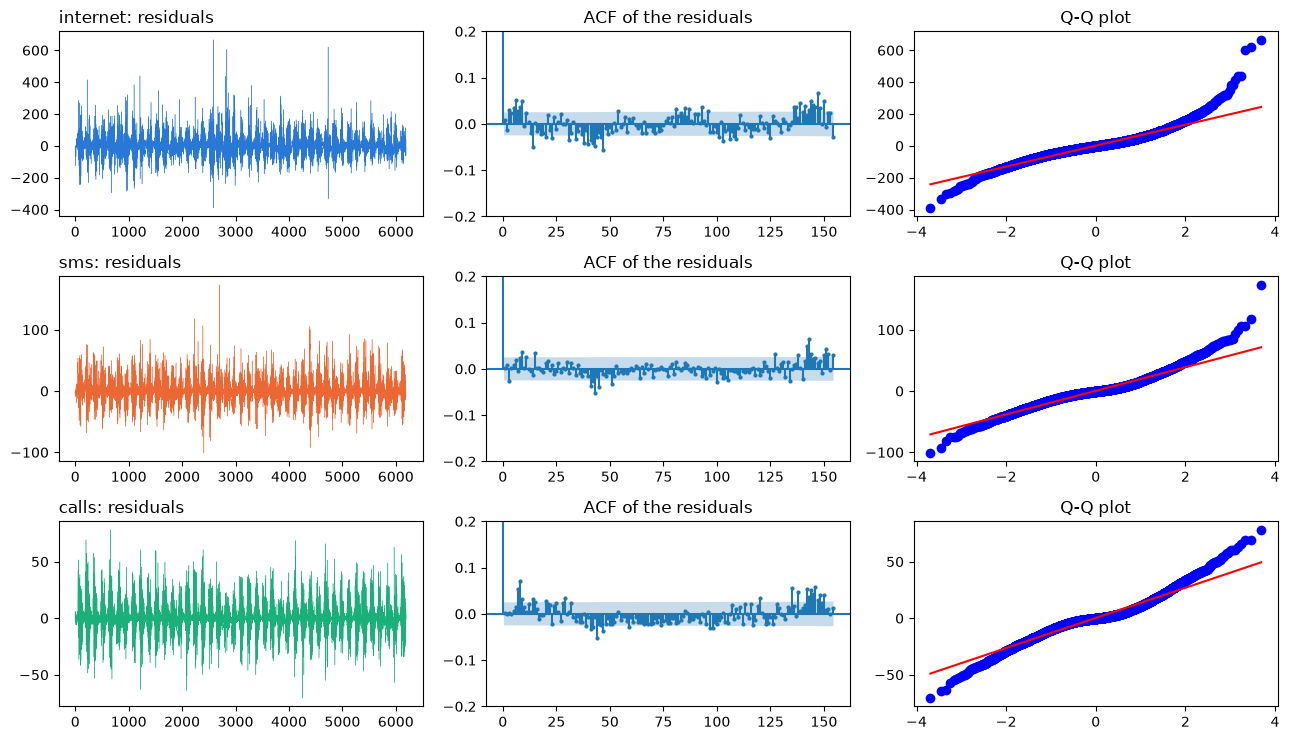

In [14]:
# Residuals of the SARIMA models: time plot, ACF, Q-Q plot
fig, axes = plt.subplots(len(SERIES), 3, figsize=(13, 7.5))
for i, s in enumerate(SERIES):
    e = RESID[(s, "SARIMA")]
    axes[i, 0].plot(e, lw=0.3, color=COLOR[s]); axes[i, 0].set_title(f"{s}: residuals", loc="left")
    plot_acf(e, lags=SEASON + 10, ax=axes[i, 1], markersize=2, title="ACF of the residuals")
    axes[i, 1].set_ylim(-0.2, 0.2)
    stats.probplot(e, plot=axes[i, 2]); axes[i, 2].set_title("Q-Q plot"); axes[i, 2].set_xlabel(""); axes[i, 2].set_ylabel("")
fig.tight_layout(); plt.show()

#### Ερμηνεία

Τα κατάλοιπα είναι κοντά στον λευκό θόρυβο. Η μεγαλύτερη απόλυτη αυτοσυσχέτιση είναι 0.064 έως 0.083, και συνήθως
βρίσκεται γύρω από το lag 144. Το Ljung-Box απορρίπτει παρ' όλα αυτά τη λευκότητα σχεδόν παντού, γιατί με
$n \approx 6000$ σημεία ανιχνεύει και πολύ μικρές αυτοσυσχετίσεις, πρακτικά αμελητέες για την πρόβλεψη.

Τα κατάλοιπα δεν είναι κανονικά: το Q-Q plot δείχνει βαριές ουρές, με υπερβάλλουσα κύρτωση περίπου 6.8 στο Internet
και 2.7 έως 3.4 στα SMS και Calls, λόγω των απρόβλεπτων αιχμών. Είναι επίσης ετεροσκεδαστικά: η τυπική απόκλιση από
τις 08:00 έως τις 20:00 είναι 1.6 (Internet) έως 3.3 (Calls) φορές μεγαλύτερη από των υπόλοιπων ωρών. Άρα ένα
διάστημα σταθερού πλάτους θα είναι πολύ φαρδύ τη νύχτα και πολύ στενό στις αιχμές. Αυτό θα το δούμε αργότερα, στα διαστήματα πρόβλεψης.

Στο SARIMA και στις τρεις σειρές $\Theta_1 \approx -0.99$. Τότε το $(1 - 0.99 B^{144})$ σχεδόν αναιρεί την εποχική
διαφόριση $(1 - B^{144})$, δηλαδή το μοντέλο δεν αντιγράφει τη χθεσινή ημέρα αλλά μαθαίνει ένα σχεδόν σταθερό
ημερήσιο σχήμα από πολλές ημέρες. Είναι ουσιαστικά η ίδια ιδέα με τους ημερήσιους όρους Fourier του ARIMA-x. Η τιμή
είναι κοντά στο όριο της αντιστρεψιμότητας ($|\Theta_1| < 1$), αλλά δεν το ξεπερνά.

### 2.7 Rolling-window πρόβλεψη ($h = 1$ και $H = 5$)

Ακολουθούμε τη διαδικασία των Siami-Namini et al. (ICMLA 2018):

```
history <- train
for t in test:
    model   <- ARIMA(history)        # στο άρθρο: re-fit σε κάθε βήμα
    y_hat_t <- model.forecast()
    history.append(y_t)           # προσθέτουμε την ΠΡΑΓΜΑΤΙΚΗ τιμή, όχι την πρόβλεψη
```

Το κρίσιμο σημείο είναι η τελευταία γραμμή: μετά από κάθε πρόβλεψη το μοντέλο μαθαίνει την πραγματική τιμή, όπως ένα
δίκτυο που μετρά συνεχώς το φορτίο. Στον κώδικα αυτό είναι το `res.forecast(...)` και μετά το `res.extend(...)`.

Η μία διαφορά μας είναι ότι οι παράμετροι εκτιμώνται μία φορά στο train και μένουν σταθερές. Με 2304 σημεία και 22
λεπτά ανά fit το re-fit δεν είναι εφικτό, και με 6624 σημεία στο train λίγες ακόμη τιμές θα άλλαζαν ελάχιστα τις
παραμέτρους. Το `extend` ενημερώνει τη μνήμη του μοντέλου με κάθε νέα τιμή, χωρίς να αλλάζει τους συντελεστές.

Από κάθε σημείο του test προβλέπουμε 5 βήματα. Το πρώτο βήμα δίνει το short-term ($h = 1$). Για το long-term ($H = 5$)
κρατάμε και τα 5 βήματα από κάθε πέμπτο σημείο, οπότε κάθε σημείο προβλέπεται μία φορά. Οι άγνωστες μελλοντικές διαταραχές
τίθενται 0 και η κατάσταση της ενότητας 2.5 προχωρά με το $T$ (αναδρομική πρόβλεψη):

$$\hat z_{t+j \mid t} = Z\, T^{\,j-1} a_{t+1 \mid t}$$

Αυτό κάνει το `res.forecast`, και το `res.extend` είναι το βήμα ενημέρωσης του Kalman filter με τη νέα πραγματική τιμή. Στο SARIMA
προσθέτουμε πίσω την τιμή της προηγούμενης ημέρας, $\hat y_{t+j} = \hat z_{t+j} + y_{t+j-144}$, και στο ARIMA-x τους γνωστούς όρους,
$\hat y_{t+j} = \hat z_{t+j} + \beta^\top x_{t+j}$.

Η εκφώνηση αναφέρει ιστορικό παράθυρο π.χ. $w = 10$. Στην ARIMA το παράθυρο δεν είναι ελεύθερη επιλογή, αλλά προκύπτει
από το μοντέλο, που βλέπει όλο το ιστορικό μέσα από τη μνήμη του. Ένα μοντέλο εκτιμημένο σε 10 σημεία δεν θα έβλεπε καν
την ημερήσια περίοδο.


In [15]:
H_SHORT, H_LONG = 1, 5
idx1 = np.arange(n_train, N)                               # h = 1: every test point
origins5 = np.arange(n_train, N - H_LONG + 1, H_LONG)      # H = 5: every 5th test point
idx5 = (origins5[:, None] + np.arange(H_LONG)).ravel()


def rolling_forecast(s, family):
    """Forecast from each test point, then show the model the actual value. The parameters stay fixed."""
    y, X = Y[s], FAMILIES[family][0]
    res = filter_model(y[:n_train], s, family, None if X is None else X[:n_train])
    paths = np.full((N - n_train, H_LONG), np.nan)         # paths[i, j]: forecast from test point i, j+1 steps ahead
    t0 = time.perf_counter()
    for i, t in enumerate(idx1):
        steps = min(H_LONG, N - t)
        if X is None:                                      # SARIMA forecasts z: add back the value of yesterday
            paths[i, :steps] = res.forecast(steps) + y[t - SEASON:t - SEASON + steps]
            res = res.extend(np.array([y[t] - y[t - SEASON]]))
        else:
            paths[i, :steps] = res.forecast(steps, exog=X[t:t + steps])
            res = res.extend(y[t:t + 1], exog=X[t:t + 1])
    return {"h1": paths[:, 0], "H5": paths[origins5 - n_train].ravel(),
            "seconds_per_forecast": (time.perf_counter() - t0) / len(idx1)}


ARIMA_ROLL = {(s, fam): rolling_forecast(s, fam) for s in SERIES for fam in FAMILIES}
print({k: round(1e3 * v["seconds_per_forecast"], 1) for k, v in ARIMA_ROLL.items()}, "ms per forecast")


{('internet', 'SARIMA'): 8.6, ('internet', 'ARIMA-x'): 2.6, ('sms', 'SARIMA'): 8.5, ('sms', 'ARIMA-x'): 2.7, ('calls', 'SARIMA'): 8.9, ('calls', 'ARIMA-x'): 2.7} ms per forecast


### 2.8 Σύνοψη

Τα ADF/KPSS έδωσαν $d = 0$ και η ACF ισχυρή ημερήσια εποχικότητα, άρα $D = 1$ με $s = 144$. Για το εποχικό μέρος
κρατήσαμε την απλούστερη επιλογή $P = 0$, $Q = 1$, και το BIC επέλεξε μικρά $p, q$. Την αποτίμηση στο test την κάνουμε αργότερα, μαζί με όλα τα υπόλοιπα μοντέλα.

## 3. Deep learning: LSTM

Η ενότητα αυτή εφαρμόζει ένα αναδρομικό νευρωνικό δίκτυο (LSTM) στο ίδιο πρόβλημα, με την ίδια διαδικασία
αποτίμησης (ίδιο train/test, ίδιοι ορίζοντες, ίδια σημεία του test, ίδιες μετρικές), ώστε η σύγκριση με την
οικογένεια ARIMA να είναι δίκαιη. Αυτό είναι και το ζητούμενο του άρθρου των Siami-Namini et al.

### 3.1 Θεωρία

#### 3.1.1 Από τα γραμμικά μοντέλα στα νευρωνικά δίκτυα

Η ARIMA είναι γραμμική: η πρόβλεψη είναι ένα σταθμισμένο άθροισμα προηγούμενων τιμών και διαταραχών. Ένα
νευρωνικό δίκτυο μαθαίνει μια μη γραμμική συνάρτηση $\hat y = f_\theta(\text{ιστορικό})$, με παραμέτρους $\theta$
που εκτιμώνται ελαχιστοποιώντας ένα σφάλμα στο train με gradient descent. Έτσι μπορεί, κατ' αρχήν, να μάθει σχέσεις
που η ARIMA δεν μπορεί να εκφράσει (π.χ. «η άνοδος είναι πιο απότομη τα πρωινά των εργάσιμων»). Το τίμημα είναι
πολλές περισσότερες παράμετροι, ανάγκη για περισσότερα δεδομένα και κίνδυνος υπερπροσαρμογής.

#### 3.1.2 Αναδρομικά δίκτυα (RNN)

Ένα RNN διαβάζει την ακολουθία ένα βήμα τη φορά και κρατά μια κρυφή κατάσταση $h_t$, που λειτουργεί σαν μνήμη
όσων έχει δει ως τώρα:

$$h_t = \tanh\!\big(W x_t + U h_{t-1} + b\big)$$

Οι ίδιοι πίνακες $W, U$ χρησιμοποιούνται σε κάθε βήμα, οπότε το δίκτυο εφαρμόζει τον ίδιο «κανόνα ενημέρωσης» σε
όλη την ακολουθία, όπως ακριβώς η ARIMA εφαρμόζει τους ίδιους συντελεστές σε κάθε $t$. Η πρόβλεψη βγαίνει από την
τελευταία κατάσταση: $\hat y = V h_t + c$.

Το πρόβλημα των εξαφανιζόμενων gradients. Η εκπαίδευση γίνεται με *Backpropagation Through Time*: το gradient του
σφάλματος ως προς μια κατάσταση $k$ βήματα πίσω είναι γινόμενο $k$ Ιακωβιανών:

$$\frac{\partial h_t}{\partial h_{t-k}} \;=\; \prod_{j=0}^{k-1} \frac{\partial h_{t-j}}{\partial h_{t-j-1}} \;=\; \prod_{j=0}^{k-1} \operatorname{diag}\!\big(1 - h_{t-j}^2\big)\, U$$

Αν οι παράγοντες έχουν μέτρο μικρότερο από 1, το γινόμενο μηδενίζεται εκθετικά (vanishing gradient) και το δίκτυο
δεν μπορεί να μάθει εξαρτήσεις από μακρινό παρελθόν. Αν έχουν μέτρο μεγαλύτερο από 1, εκρήγνυται (exploding
gradient) και η εκπαίδευση γίνεται ασταθής. Στο πρόβλημά μας αυτό έχει σημασία: για $w = 144$ το δίκτυο πρέπει να
συνδέσει την τρέχουσα τιμή με τιμές μιας ολόκληρης ημέρας πριν.

#### 3.1.3 LSTM (Hochreiter και Schmidhuber, 1997)

Το LSTM λύνει το πρόβλημα προσθέτοντας μια δεύτερη κατάσταση, την κατάσταση κελιού $c_t$ (μακροπρόθεσμη μνήμη), και
τρεις πύλες που αποφασίζουν τι ξεχνιέται, τι γράφεται και τι διαβάζεται. Κάθε πύλη είναι ένα διάνυσμα με τιμές στο
$(0, 1)$, μέσω της σιγμοειδούς $\sigma(x) = 1 / (1 + e^{-x})$, και πολλαπλασιάζεται στοιχείο προς στοιχείο ($\odot$):

$$
\begin{aligned}
f_t &= \sigma\big(W_f x_t + U_f h_{t-1} + b_f\big) && \text{forget gate: πόσο από την παλιά μνήμη κρατάμε} \\[3pt]
i_t &= \sigma\big(W_i x_t + U_i h_{t-1} + b_i\big) && \text{input gate: πόση νέα πληροφορία γράφουμε} \\[3pt]
\tilde c_t &= \tanh\big(W_c x_t + U_c h_{t-1} + b_c\big) && \text{υποψήφια νέα πληροφορία} \\[3pt]
c_t &= f_t \odot c_{t-1} \;+\; i_t \odot \tilde c_t && \text{ενημέρωση της μνήμης} \\[3pt]
o_t &= \sigma\big(W_o x_t + U_o h_{t-1} + b_o\big) && \text{output gate: τι από τη μνήμη δίνουμε ως έξοδο} \\[3pt]
h_t &= o_t \odot \tanh(c_t) && \text{νέα κρυφή κατάσταση}
\end{aligned}
$$

Γιατί δουλεύει. Η ενημέρωση της μνήμης $c_t = f_t \odot c_{t-1} + i_t \odot \tilde c_t$ είναι προσθετική. Το
gradient από το $c_t$ προς το $c_{t-1}$ είναι απλώς $f_t$, όχι γινόμενο με έναν πίνακα βαρών και μια παράγωγο
$\tanh$. Όταν το δίκτυο μάθει $f_t \approx 1$, η πληροφορία και το gradient περνούν πολλά βήματα σχεδόν
αναλλοίωτα. Οι πύλες μαθαίνονται από τα δεδομένα, οπότε το δίκτυο αποφασίζει μόνο του τι αξίζει να θυμάται (π.χ. «η
κίνηση ανεβαίνει εδώ και μία ώρα») και τι να ξεχάσει.

### 3.2 Διατύπωση ως πρόβλημα επιβλεπόμενης μάθησης

Κόβουμε τη σειρά σε παράθυρα: είσοδος οι τελευταίες $w$ τιμές, στόχος οι επόμενες $h$.

$$(y_{t-w},\; \dots,\; y_{t-1}) \;\longmapsto\; (y_t,\; \dots,\; y_{t+h-1})$$

Εδώ, σε αντίθεση με την ARIMA, το $w$ είναι πραγματική επιλογή, γιατί το δίκτυο βλέπει μόνο ό,τι είναι μέσα στο
παράθυρο. Δοκιμάζουμε $w = 10$ (100 λεπτά), την τιμή της εκφώνησης, και $w = 144$ (24 ώρες), όπου το παράθυρο περιέχει
ολόκληρη την προηγούμενη ημέρα και το δίκτυο μπορεί να μάθει την ημερήσια περιοδικότητα.

Για $H = 5$ το δίκτυο έχει 5 εξόδους και τις βγάζει όλες μαζί. Έτσι ένα λάθος στο βήμα 1 δεν γίνεται είσοδος για το βήμα 2,
όπως στην αναδρομική πρόβλεψη της ARIMA. Για $h = 1$ οι δύο τρόποι ταυτίζονται.


### 3.3 Κανονικοποίηση min-max στο $[0, 1]$

Στην είσοδο οι τιμές μετασχηματίζονται ώστε το train να πιάνει ακριβώς το $[0, 1]$, και στην έξοδο γίνεται το αντίστροφο:

$$\tilde y_t = \frac{y_t - y_{\min}}{y_{\max} - y_{\min}} \qquad\qquad \hat y_t = \hat{\tilde y}_t \,\big(y_{\max} - y_{\min}\big) + y_{\min}$$

Η ARIMA δεν το χρειάζεται, γιατί είναι γραμμική. Το LSTM το χρειάζεται, γιατί οι πύλες του έχουν παράγωγο σχεδόν μηδέν για
μεγάλες εισόδους: με τιμές της τάξης του 1000 θα κολλούσαν στο 0 ή στο 1 και το δίκτυο δεν θα μάθαινε.

Τα $y_{\min}, y_{\max}$ υπολογίζονται μόνο στο train. Αλλιώς η κανονικοποίηση θα «ήξερε» την αιχμή της Πρωτοχρονιάς, δηλαδή
πληροφορία από το μέλλον. Γι' αυτό στο test οι τιμές μπορεί να βγουν λίγο έξω από το $[0, 1]$.


### 3.4 Από-περιοδικοποίηση (deseasonalisation)

Ορίζουμε το προφίλ $S_t$ ως τη μέση τιμή του train για τον ίδιο τύπο ημέρας και το ίδιο δεκάλεπτο (το προφίλ της EDA).
Το δίκτυο μαθαίνει το υπόλοιπο, και στο τέλος προσθέτουμε πίσω το προφίλ, που είναι γνωστό για κάθε μελλοντική στιγμή:

$$r_t = y_t - S_t \qquad\longrightarrow\qquad \text{LSTM} \qquad\longrightarrow\qquad \hat y_t = \hat r_t + S_t$$

Βοηθά γιατί το δίκτυο δεν χρειάζεται να μάθει το ημερήσιο σχήμα και εστιάζει στις αποκλίσεις. Για $w = 10$ είναι ο μόνος
τρόπος να «ξέρει» ότι σε μία ώρα έρχεται η μεσημεριανή αιχμή. Είναι η ίδια ιδέα με το ARIMA-x.

Μπορεί όμως να βλάψει όταν το μοτίβο του test διαφέρει από του train, γιατί τότε το $S_t$ είναι λάθος. Η εορταστική περίοδος
του test είναι ακριβώς τέτοια περίπτωση.


### 3.5 Αρχιτεκτονική και εκπαίδευση

Το δίκτυο έχει 2 στρώματα LSTM με 64 μονάδες και ένα γραμμικό στρώμα εξόδου, συνολικά περίπου 50 χιλιάδες παραμέτρους.
Η πρόβλεψη βγαίνει από την κατάσταση του τελευταίου βήματος του παραθύρου.

Εκπαιδεύεται με MSE και Adam (learning rate $10^{-3}$, batch 128). Το dropout 0.1 ανάμεσα στα στρώματα περιορίζει την
υπερπροσαρμογή, και το gradient clipping προστατεύει από τα exploding gradients.

Το τελευταίο 10% του train, χρονολογικά, είναι το validation. Σταματάμε όταν το validation loss δεν βελτιώνεται για 8
εποχές και κρατάμε τα καλύτερα βάρη (early stopping). Το test δεν χρησιμοποιείται για καμία απόφαση.

Συνολικά εκπαιδεύονται 3 σειρές $\times$ 2 παράθυρα $\times$ 2 εκδοχές (raw, από-περιοδικοποιημένη) $\times$ 2 ορίζοντες $= 24$
δίκτυα. Τα αποτελέσματα αποθηκεύονται στο `results/lstm_notebook.pkl`, και για νέα εκπαίδευση βάζουμε `RETRAIN = True`.


In [16]:
import os
import joblib
import torch
import torch.nn as nn
from joblib import parallel_config

SEED = 0
LSTM_WINDOWS = (10, 144)


def seasonal_profile(idx, y, n_fit):
    """S_t: mean per (day type, 10-min slot), computed on the first n_fit points (the train set)."""
    key = day_type(idx) * SEASON + (idx.hour * 6 + idx.minute // 10).values
    means = pd.Series(y[:n_fit]).groupby(key[:n_fit]).mean()
    return means.reindex(key).values


class LSTMNet(nn.Module):
    def __init__(self, horizon, hidden=64, layers=2, dropout=0.1):
        super().__init__()
        self.lstm = nn.LSTM(1, hidden, layers, batch_first=True, dropout=dropout)
        self.head = nn.Linear(hidden, horizon)

    def forward(self, x):                      # x: (batch, w, 1)
        out, _ = self.lstm(x)
        return self.head(out[:, -1])           # state of the last time step -> h outputs


def make_windows(z, targets, w, h):
    """Inputs z[t-w:t] and targets z[t:t+h] for every t in targets."""
    X = np.stack([z[t - w:t] for t in targets])[..., None].astype(np.float32)
    Yw = np.stack([z[t:t + h] for t in targets]).astype(np.float32)
    return torch.from_numpy(X), torch.from_numpy(Yw)

In [17]:
def run_lstm(s, w, deseason, h, seed=SEED, max_epochs=80, patience=8, threads=4):
    torch.set_num_threads(threads); torch.manual_seed(seed); np.random.seed(seed)
    y = Y[s]
    S = seasonal_profile(df.index, y, n_train) if deseason else np.zeros_like(y)
    r = y - S
    lo, hi = r[:n_train].min(), r[:n_train].max()           # min-max from the train set only
    z = (r - lo) / (hi - lo)

    # training windows; the last 10% (in time) is the validation set
    targets = np.arange(w, n_train - h + 1)
    n_val = int(0.1 * len(targets))
    Xtr, Ytr = make_windows(z, targets[:-n_val], w, h)
    Xva, Yva = make_windows(z, targets[-n_val:], w, h)

    net = LSTMNet(h)
    opt = torch.optim.Adam(net.parameters(), lr=1e-3)
    lossf = nn.MSELoss()
    best, best_state, bad, hist = np.inf, None, 0, []
    t0 = time.perf_counter()
    for ep in range(max_epochs):
        net.train()
        perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), 128):
            b = perm[i:i + 128]
            opt.zero_grad()
            loss = lossf(net(Xtr[b]), Ytr[b])
            loss.backward()
            nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            opt.step()
        net.eval()
        with torch.no_grad():
            tr_loss = lossf(net(Xtr), Ytr).item()
            va_loss = lossf(net(Xva), Yva).item()
        hist.append((tr_loss, va_loss))
        if va_loss < best - 1e-7:                             # early stopping on the validation loss
            best, bad = va_loss, 0
            best_state = {k: v.clone() for k, v in net.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                break
    train_seconds = time.perf_counter() - t0
    net.load_state_dict(best_state); net.eval()

    # Rolling evaluation on the test set: the input is always the last w ACTUAL values
    origins = np.arange(n_train, N) if h == 1 else np.arange(n_train, N - h + 1, h)
    Xte, _ = make_windows(np.r_[z, np.zeros(h)], origins, w, h)
    with torch.no_grad():
        zhat = net(Xte).numpy()
    tidx = origins[:, None] + np.arange(h)[None, :]
    yhat = (zhat * (hi - lo) + lo + S[tidx]).ravel()          # inverse min-max, then add the profile back
    return {"pred": yhat, "origins": origins, "history": hist, "epochs": len(hist),
            "best_epoch": int(np.argmin([v for _, v in hist])) + 1, "train_seconds": train_seconds,
            "params": sum(p.numel() for p in net.parameters())}

In [18]:
RETRAIN = False
LSTM_FILE = "results/lstm_notebook.pkl"
LSTM_JOBS = [(s, w, ds, h) for s in SERIES for w in LSTM_WINDOWS for ds in (False, True) for h in (H_SHORT, H_LONG)]

if RETRAIN or not os.path.exists(LSTM_FILE):
    t0 = time.perf_counter()
    with parallel_config(backend="loky", inner_max_num_threads=4):    # 12 workers x 4 threads
        out = Parallel(n_jobs=12)(delayed(run_lstm)(*j) for j in LSTM_JOBS)
    LSTM_RES = dict(zip(LSTM_JOBS, out))
    joblib.dump(LSTM_RES, LSTM_FILE)
    print(f"trained {len(LSTM_JOBS)} networks in {time.perf_counter() - t0:.0f}s")
else:
    LSTM_RES = joblib.load(LSTM_FILE)
    print("loaded", LSTM_FILE)

pd.DataFrame([{"series": s, "w": w, "deseason": ds, "h": h, "params": v["params"], "epochs": v["epochs"],
               "best epoch": v["best_epoch"], "train (s)": round(v["train_seconds"])}
              for (s, w, ds, h), v in LSTM_RES.items()]).set_index(["series", "w", "deseason", "h"])

loaded results/lstm_notebook.pkl


params  epochs  best epoch  train (s)
series   w   deseason h                                       
internet 10  False    1   50497      64          56        112
                      5   50757      36          28         63
             True     1   50497      41          33         55
                      5   50757      43          35         77
         144 False    1   50497      46          38        745
                      5   50757      36          28        587
             True     1   50497      58          50        800
                      5   50757      27          19        471
sms      10  False    1   50497      43          35         73
                      5   50757      73          65        123
             True     1   50497      57          49         95
                      5   50757      20          12         28
         144 False    1   50497      67          59        849
                      5   50757      26          18        440
             True     1   50497      45          37        689
                      5   50757      18          10        314
calls    10  False    1   50497      40          32         58
                      5   50757      34          26         56
             True     1   50497      56          48         82
                      5   50757      30          22         51
         144 False    1   50497      53          45        667
                      5   50757      60          52        669
             True     1   50497      54          46        668
                      5   50757      30          22        435

Καμπύλες εκμάθησης. Το validation loss ανά εποχή (λογαριθμική κλίμακα) για $h = 1$. Δείχνει αν η εκπαίδευση
συγκλίνει, πόσο γρήγορα, και πού σταμάτησε το early stopping. Οι συγκρίσεις ανάμεσα σε raw και από-περιοδικοποιημένη
εκδοχή εδώ δεν είναι άμεσες, γιατί η κανονικοποίηση γίνεται σε διαφορετικά μεγέθη ($y$ ή $r$).

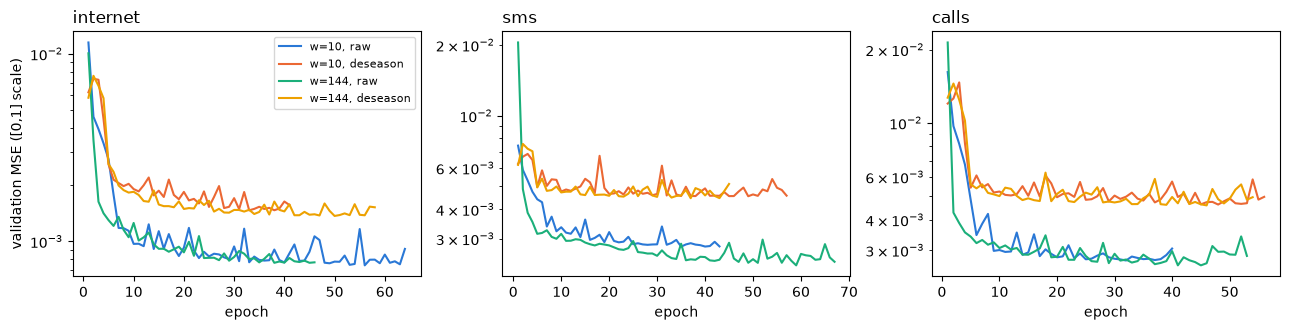

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, s in zip(axes, SERIES):
    for (w, ds), c in zip([(10, False), (10, True), (144, False), (144, True)],
                          ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]):
        hst = np.array(LSTM_RES[(s, w, ds, 1)]["history"])
        ax.plot(np.arange(1, len(hst) + 1), hst[:, 1], color=c, label=f"w={w}, {'deseason' if ds else 'raw'}")
    ax.set_yscale("log"); ax.set_title(s, loc="left"); ax.set_xlabel("epoch")
axes[0].set_ylabel("validation MSE ([0,1] scale)"); axes[0].legend(fontsize=8)
fig.tight_layout(); plt.show()

In [20]:
# Best validation loss converted back to the original units, so raw and deseason are comparable
# (with deseasonalisation S_t is added back exactly, so the error of r equals the error of y)
val = {}
for (s, w, ds, h), v in LSTM_RES.items():
    y = Y[s]
    r = y - (seasonal_profile(df.index, y, n_train) if ds else 0.0)
    rng = r[:n_train].max() - r[:n_train].min()
    val[(s, h, f"LSTM w={w}" + (" deseason" if ds else ""))] = np.sqrt(min(va for _, va in v["history"])) * rng
pd.Series(val).unstack().round(1).rename_axis(["series", "h"])

LSTM w=10  LSTM w=10 deseason  LSTM w=144  LSTM w=144 deseason
series   h                                                                
calls    1       15.2                12.6        14.9                 12.6
         5       19.3                13.8        16.6                 13.6
internet 1       56.6                50.7        57.5                 48.9
         5       86.4                59.4        76.2                 59.6
sms      1       20.8                17.6        19.0                 17.4
         5       25.0                18.4        21.4                 18.3

#### Ερμηνεία της εκπαίδευσης

Όλα τα δίκτυα συγκλίνουν. Η καλύτερη εποχή είναι από 10 έως 65 και το early stopping σταματά 8 εποχές αργότερα,
πολύ πριν από το όριο των 80. Το $w = 144$ κοστίζει περίπου 10 φορές περισσότερο (περίπου 300 έως 850 s ανά δίκτυο,
έναντι 30 έως 120 s για $w = 10$), γιατί το backpropagation through time ξετυλίγει το δίκτυο σε 144 βήματα αντί για
10.

Στο validation η από-περιοδικοποίηση βοηθά σε όλες τις περιπτώσεις. Το RMSE στις αρχικές μονάδες μειώνεται κατά 8%
έως 17% για $h = 1$ (π.χ. Internet, $w = 144$: 48.9 έναντι 57.5) και κατά 14% έως 31% για $H = 5$. Με βάση όσα
ξέρουμε πριν από το test, θα ήταν λοιπόν η λογική επιλογή. Το validation όμως είναι οι τελευταίες 4.6 ημέρες του
train (11/12 έως 16/12), δηλαδή κανονικές ημέρες. Αργότερα θα δούμε ότι στο test η εικόνα αλλάζει.

Στο test ακολουθούμε τον ψευδοκώδικα της ενότητας 2.7: σε κάθε αφετηρία η είσοδος του δικτύου είναι οι τελευταίες
$w$ πραγματικές τιμές, τα βάρη μένουν σταθερά και οι αφετηρίες είναι ίδιες με της ARIMA. Οι προβλέψεις αποτιμώνται
αργότερα.

## 4. Foundation model: TimesFM 3.0

### 4.1 Θεωρία

Τα ARIMA και LSTM ξέρουν μόνο ό,τι έμαθαν από τις 6624 τιμές του train. Ένα foundation model ακολουθεί τη λογική των LLMs:
ένα μεγάλο transformer εκπαιδεύεται μία φορά σε τεράστιο όγκο χρονοσειρών από πολλά πεδία και μαθαίνει γενικά μοτίβα,
όπως επίπεδα, τάσεις, περιοδικότητες και αιχμές.

Το χρησιμοποιούμε με δύο τρόπους. Στο zero-shot δεν εκπαιδεύεται καθόλου στα δεδομένα μας: του δίνουμε το ιστορικό ως
context, όπως ένα prompt, και το συνεχίζει. Στο fine-tuning συνεχίζουμε την εκπαίδευση με μικρό learning rate σε δικά μας
δεδομένα.

| | ARIMA / LSTM | Foundation model |
|:---|:---|:---|
| Γνώση | μόνο από τη συγκεκριμένη σειρά | από πολλές σειρές, μεταφέρεται (*transfer learning*) |
| Εκπαίδευση στα δεδομένα μας | απαραίτητη | προαιρετική (zero-shot ή fine-tuning) |
| Παράμετροι | από μερικές έως περίπου 50 χιλιάδες | εκατοντάδες εκατομμύρια |
| Κόστος | στην εκπαίδευση | κυρίως στο inference |

Το TimesFM (Google Research, Das et al., ICML 2024) είναι decoder-only transformer, όπως τα GPT:

* Η σειρά κόβεται σε κομμάτια (patches) των 32 σημείων, και κάθε κομμάτι παίζει τον ρόλο ενός token. Έτσι 1024 τιμές γίνονται
  32 tokens.
* Κάθε context κανονικοποιείται με τον δικό του μέσο και τυπική απόκλιση (RevIN), οπότε Internet και SMS αντιμετωπίζονται
  με τον ίδιο τρόπο.
* Η προσοχή (attention) συγκρίνει άμεσα το τρέχον κομμάτι με οποιοδήποτε παλαιότερο, π.χ. την ίδια ώρα πριν από μία
  εβδομάδα, ενώ ένα LSTM πρέπει να το κουβαλήσει στη μνήμη του.
* Η έξοδος είναι πιθανοτική: για κάθε βήμα δίνει τα ποσοστημόρια $0.1, \dots, 0.9$. Ως πρόβλεψη παίρνουμε τη διάμεσο.

Το TimesFM 3.0 έχει περίπου 331 εκατομμύρια παραμέτρους και 20 στρώματα. Προβλέπουμε κάθε σειρά μόνη της, όπως και με τα
άλλα μοντέλα. Τα βάρη έχουν άδεια μη εμπορικής χρήσης, κάτι που μετράει αν ένας πάροχος θέλει να το χρησιμοποιήσει.


### 4.2 Ρύθμιση των πειραμάτων

Zero-shot. Σε κάθε σημείο $t$ του test δίνουμε ως context τις 1024 πραγματικές τιμές πριν από το $t$ (περίπου 7.1 ημέρες,
άρα μια ολόκληρη εβδομάδα) και παίρνουμε πρόβλεψη 5 βημάτων. Τα σημεία είναι ίδια με της ενότητας 2.7, και καμία
προεπεξεργασία δεν χρειάζεται. Οι 2304 προβλέψεις ανά σειρά τρέχουν σε batches των 128, σε CPU.

Fine-tuning. Εκπαιδεύουμε μόνο τα 2 τελευταία από τα 20 στρώματα και το output head, περίπου το 10% του μοντέλου. Με
περίπου 6 χιλιάδες σημεία, ένα πλήρες fine-tuning θα κινδύνευε να «ξεχάσει» όσα έμαθε το μοντέλο. Χρησιμοποιούμε την ίδια
loss με την προεκπαίδευση (pinball loss), AdamW με learning rate $3 \cdot 10^{-5}$, 30 φορές μικρότερο από το LSTM, batch 16 και
300 βήματα, σε τυχαία παράθυρα του train.

Οι τελευταίες 5 ημέρες του train είναι το validation, και κρατάμε τα βάρη με το μικρότερο validation loss. Αν κανένα
βήμα δεν βελτιώσει το zero-shot, μένουν τα αρχικά βάρη.

Για κάθε σειρά αξιολογούμε zero-shot, κάνουμε fine-tuning και αξιολογούμε ξανά. Η εκτέλεση παίρνει περίπου μισή ώρα, οπότε τα
αποτελέσματα αποθηκεύονται στο `results/timesfm_notebook.pkl`. Για νέα εκτέλεση βάζουμε `RETRAIN_TFM = True`.


In [21]:
TFM_CONTEXT = 1024            # context: the last 1024 values (~7.1 days)
TFM_THREADS = 32              # one process with 32 threads was the fastest setting on kamino (CPU only)


def tfm_rolling(fc, y, batch=128):
    """Rolling evaluation: at every test origin t the context is the last TFM_CONTEXT ACTUAL values."""
    origins = np.arange(n_train, N)
    ctx = [y[t - TFM_CONTEXT:t] for t in origins]
    fc.config.per_core_batch_size = batch
    t0 = time.perf_counter()
    outs = list(fc.predict_batch(ctx, horizon=H_LONG, return_quantiles=True))
    seconds = time.perf_counter() - t0
    paths = np.stack([o.forecast for o in outs])               # (n_test, 5): median per lead
    quant = np.stack([o.quantiles for o in outs])              # (n_test, 5, 9): quantiles 0.1 ... 0.9
    return {"h1": paths[:, 0],                                 # lead 1 from every origin
            "H5": paths[origins5 - n_train].ravel(),           # leads 1..5 from every 5th origin
            "q_h1": quant[:, 0], "quantiles": list(fc.config.quantiles),
            "seconds_per_forecast": seconds / len(origins)}


def finetune_tfm(fc, y, steps=300, lr=3e-5, n_layers=2, batch=16, horizon_ft=16, eval_every=20, seed=SEED):
    """Partial fine-tuning: only the last n_layers transformer layers and the output head are trained."""
    from timesfm3 import TimesFM3Torch
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    m = fc.model
    decode = TimesFM3Torch.decode.__wrapped__                  # decode without @torch.no_grad, so gradients flow
    for p in m.parameters():
        p.requires_grad_(False)
    params = list(m.output_head.parameters())
    for layer in m.transformer_stack.layers[-n_layers:]:
        params += list(layer.parameters())
    for p in params:
        p.requires_grad_(True)
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=0.0)
    q = torch.tensor(m.quantiles, dtype=torch.float32)
    scale = float(np.std(y[:n_train]))                         # loss in units of the train std
    n_val = 5 * SEASON                                         # validation: the last 5 days of the train set
    fit_starts = np.arange(TFM_CONTEXT, n_train - n_val - horizon_ft + 1)
    val_starts = np.linspace(n_train - n_val, n_train - horizon_ft, 48).astype(int)

    def loss_on(starts):
        X = torch.from_numpy(np.stack([y[t - TFM_CONTEXT:t] for t in starts]).astype(np.float32))[:, None, :]
        T = torch.from_numpy(np.stack([y[t:t + horizon_ft] for t in starts]).astype(np.float32))
        out = decode(m, target=X, horizon=horizon_ft)[:, 0]    # (batch, horizon, quantiles)
        e = (T[..., None] - out) / scale
        return torch.maximum(q * e, (q - 1) * e).mean()       # pinball loss over all quantiles

    def val_loss():
        with torch.no_grad():
            return float(np.mean([loss_on(val_starts[i:i + 16]).item() for i in range(0, len(val_starts), 16)]))

    snapshot = lambda: [p.detach().clone() for p in params]
    best, best_state, best_step = val_loss(), snapshot(), 0  # step 0 = the pretrained weights
    log = [(0, np.nan, best)]
    t0 = time.perf_counter()
    for step in range(1, steps + 1):
        loss = loss_on(rng.choice(fit_starts, batch, replace=False))
        opt.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(params, 1.0); opt.step()
        if step % eval_every == 0:
            v = val_loss()
            log.append((step, loss.item(), v))
            if v < best:                                       # early stopping: keep the best weights
                best, best_state, best_step = v, snapshot(), step
    with torch.no_grad():
        for p, b in zip(params, best_state):
            p.copy_(b)
    for p in m.parameters():
        p.requires_grad_(False)
    return {"log": log, "zero_shot_val": log[0][2], "best_val": best, "best_step": best_step,
            "train_seconds": time.perf_counter() - t0, "trainable_params": sum(p.numel() for p in params),
            "total_params": sum(p.numel() for p in m.parameters())}


def run_timesfm(s):
    from timesfm3 import TimesFM3Forecaster
    fc = TimesFM3Forecaster.from_pretrained(device="cpu")      # fresh pretrained weights for every series
    out = {"zero": tfm_rolling(fc, Y[s])}
    out["ft_info"] = finetune_tfm(fc, Y[s])
    out["ft"] = tfm_rolling(fc, Y[s])
    return out

In [22]:
RETRAIN_TFM = False
TFM_FILE = "results/timesfm_notebook.pkl"

if RETRAIN_TFM or not os.path.exists(TFM_FILE):
    torch.set_num_threads(TFM_THREADS)
    t0 = time.perf_counter()
    TFM_RES = {s: run_timesfm(s) for s in SERIES}              # series one after the other, all threads each
    joblib.dump(TFM_RES, TFM_FILE)
    print(f"TimesFM: 3 series in {time.perf_counter() - t0:.0f}s")
else:
    TFM_RES = joblib.load(TFM_FILE)
    print("loaded", TFM_FILE)

pd.DataFrame([{"series": s, "trainable params": v["ft_info"]["trainable_params"],
               "total params": v["ft_info"]["total_params"],
               "val loss zero-shot": v["ft_info"]["zero_shot_val"], "val loss fine-tuned": v["ft_info"]["best_val"],
               "val change %": 100 * (v["ft_info"]["best_val"] / v["ft_info"]["zero_shot_val"] - 1),
               "best step": v["ft_info"]["best_step"], "fine-tune (s)": round(v["ft_info"]["train_seconds"]),
               "ms / forecast": 1000 * v["zero"]["seconds_per_forecast"]}
              for s, v in TFM_RES.items()]).set_index("series").round(4)

loaded results/timesfm_notebook.pkl


,trainable params,total params,val loss zero-shot,val loss fine-tuned,val change %,best step,fine-tune (s),ms / forecast
series,,,,,,,,
internet,33522176,330710976,0.0924,0.0692,-25.1197,280,425,47.5256
sms,33522176,330710976,0.0823,0.0730,-11.2432,300,436,44.4044
calls,33522176,330710976,0.0595,0.0514,-13.7226,300,426,46.9936


Καμπύλες fine-tuning. Το validation loss κάθε 20 βήματα, ως λόγος προς το zero-shot (βήμα 0). Τιμή κάτω από 1
σημαίνει ότι το fine-tuning βελτίωσε το μοντέλο στις τελευταίες 5 ημέρες του train.

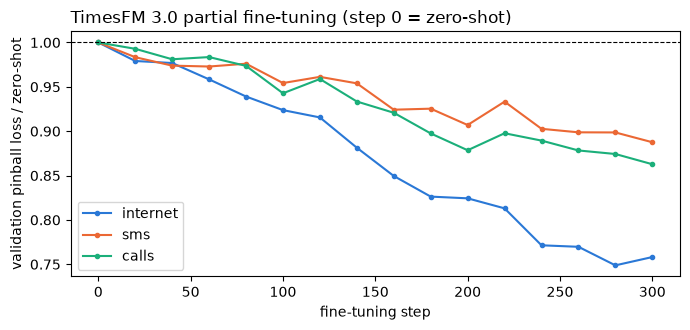

In [23]:
fig, ax = plt.subplots(figsize=(7, 3.4))
for s, c in zip(SERIES, ["#2a78d6", "#eb6834", "#1baf7a"]):
    lg = np.array(TFM_RES[s]["ft_info"]["log"])
    ax.plot(lg[:, 0], lg[:, 2] / lg[0, 2], color=c, marker="o", ms=3, label=s)
ax.axhline(1, color="k", lw=0.8, ls="--")
ax.set_xlabel("fine-tuning step"); ax.set_ylabel("validation pinball loss / zero-shot")
ax.set_title("TimesFM 3.0 partial fine-tuning (step 0 = zero-shot)", loc="left"); ax.legend()
fig.tight_layout(); plt.show()

#### Ερμηνεία του fine-tuning

Εκπαιδεύεται περίπου το 10% του μοντέλου: 33.5 εκατομμύρια από τις 331 εκατομμύρια παραμέτρους (2 στρώματα και το
output head). Κάθε fine-tuning κράτησε περίπου 7 λεπτά σε CPU (300 βήματα), περίπου όσο ένα LSTM με $w = 144$.

Το validation loss μειώθηκε σε όλες τις σειρές: κατά 25% στο Internet, 11% στο SMS και 14% στα Calls. Το καλύτερο
βήμα είναι το 280 ή το 300, δηλαδή στο τέλος, οπότε με περισσότερα βήματα θα έπεφτε πιθανότατα κι άλλο. Με βάση όσα
ξέρουμε πριν από το test, η fine-tuned εκδοχή είναι λοιπόν η λογική επιλογή. Όπως όμως και με την
από-περιοδικοποίηση του LSTM, το validation είναι κανονικές ημέρες του Δεκεμβρίου, ενώ το test όχι.

Το inference κοστίζει περίπου 45 ms ανά πρόβλεψη σε batches των 128, με 32 threads, πολύ ακριβότερα από ARIMA και
LSTM, αλλά το zero-shot δεν χρειάζεται καμία εκπαίδευση.

Οι προβλέψεις αποτιμώνται αργότερα, με τις ίδιες αφετηρίες όπως τα υπόλοιπα μοντέλα.

## 5. Αποτίμηση και σύγκριση: RMSE, MAE, MAPE, MASE

Όλα τα μοντέλα αποτιμώνται στα ίδια σημεία του test. Μαζί τους βάζουμε δύο απλούς κανόνες που ένα μοντέλο πρέπει να νικά:

* Naive (persistence): «η κίνηση θα μείνει όπως είναι τώρα»,
* Seasonal naive: «η κίνηση θα είναι όπως χθες την ίδια ώρα».

Στις συγκρίσεις κάθε οικογένεια εκπροσωπείται από ένα μοντέλο, που ορίζουμε από πριν για να μην επιλέγουμε με βάση το
test: το SARIMA, το LSTM $w = 144$ (raw), που βλέπει μια ολόκληρη ημέρα, και το TimesFM zero-shot.

### 5.1 Ορισμοί και τι μετράει κάθε μετρική

Με $e_t = y_t - \hat y_t$ τα σφάλματα στα $n$ σημεία του test, και $m = 144$:

| Μετρική | Τύπος | Μονάδα | Τι μετράει |
|:---|:---|:---|:---|
| RMSE | $\sqrt{\tfrac1n \sum_t e_t^2}$ | μονάδες της σειράς | τετραγωνικό σφάλμα: τα μεγάλα σφάλματα μετράνε δυσανάλογα. Ελαχιστοποιείται από τη μέση τιμή της κατανομής πρόβλεψης |
| MAE | $\tfrac1n \sum_t \lvert e_t\rvert$ | μονάδες της σειράς | τυπικό μέγεθος σφάλματος, ανθεκτικό σε ακραίες τιμές. Ελαχιστοποιείται από τη διάμεσο |
| MAPE | $\tfrac{100}{n} \sum_t \lvert e_t / y_t\rvert$ | % | μέσο σχετικό σφάλμα ανά σημείο |
| WAPE | $100 \, \sum_t \lvert e_t\rvert \,/\, \sum_t \lvert y_t\rvert$ | % | το ποσοστό του συνολικού όγκου που προβλέφθηκε λάθος (πρόσθετη μετρική) |
| MASE | $\dfrac{\tfrac1n \sum_t \lvert e_t\rvert}{\tfrac{1}{n_{tr}-m} \sum_{t=m+1}^{n_{tr}} \lvert y_t - y_{t-m}\rvert}$ | αδιάστατη | MAE του μοντέλου ως πολλαπλάσιο του MAE της seasonal naive στο train |

Ο λόγος RMSE / MAE δείχνει πόσο «βαριές» είναι οι ουρές των σφαλμάτων: για κανονικά σφάλματα είναι
$\sqrt{\pi/2} \approx 1.25$. Τιμές πάνω από αυτό σημαίνουν ότι λίγα, μεγάλα σφάλματα (οι αιχμές) κυριαρχούν.

#### MASE: γιατί χρησιμοποιείται και τι μας προσφέρει παραπάνω

$$\text{MASE} = \frac{\tfrac1n \sum_t \lvert e_t\rvert}{\tfrac{1}{n_{tr}-144} \sum_{t=145}^{n_{tr}} \lvert y_t - y_{t-144}\rvert}$$

Ο παρονομαστής είναι το σφάλμα του κανόνα «όπως χθες» στο train. Έτσι MASE $= 0.3$ σημαίνει ότι το μοντέλο κάνει το 30% του
σφάλματος αυτού του κανόνα, και κάτω από 1 σημαίνει ότι τον νικά. Τα RMSE, MAE και MAPE δεν λένε από μόνα τους αν μια
τιμή είναι καλή.

Είναι ανεξάρτητη της κλίμακας, οπότε συγκρίνει σειρές μεταξύ τους: ένα MAE 30 είναι εξαιρετικό στο Internet αλλά τεράστιο
στα SMS. Η MAPE το πετυχαίνει διαιρώντας με το $y_t$, και γι' αυτό εκρήγνυται όταν $y_t \to 0$. Η MASE διαιρεί με μία σταθερά,
οπότε δεν έχει αυτό το πρόβλημα. Είναι επίσης συμμετρική, ενώ η MAPE τιμωρεί περισσότερο την υπερεκτίμηση: αν $y_t = 100$, η
πρόβλεψη 300 δίνει 200%, ενώ καμία υποεκτίμηση δεν ξεπερνά το 100%.

Τέλος, είναι ανεξάρτητη από τη σταθερά ανωνυμοποίησης $k$, που απλοποιείται, όπως και στις MAPE και WAPE αλλά όχι
στις RMSE και MAE. Επιτρέπει έτσι σύγκριση μεταξύ σειρών και οριζόντων με έναν αριθμό, άρα και μέσο όρο πάνω σε όλα
τα κελιά ενός δικτύου.

Ένα λεπτό σημείο: ο παρονομαστής υπολογίζεται στο train, όχι στο test. Γι' αυτό η MASE συγκρίνει το μοντέλο με
μια σταθερή κλίμακα αναφοράς που δεν αλλάζει από μοντέλο σε μοντέλο, και όχι με το πόσο καλά τα πήγε η seasonal
naive στο ίδιο test (εκεί η seasonal naive έχει MASE πάνω από 1). Για το πραγματικό «κατώφλι»
χρήσιμου μοντέλου κοιτάμε επιπλέον τη σύγκριση με το Naive, που εξετάζουμε παρακάτω.

Ο πρώτος πίνακας δίνει τη MASE όλων των μοντέλων. Ο δεύτερος δείχνει τα δύο σημεία αναφοράς και τα τρία βασικά μοντέλα με όλες
τις μετρικές. Μετά μετράμε πόσες τιμές του test είναι κοντά στο μηδέν, για να φανεί η συμπεριφορά της MAPE.


In [24]:
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)   # .loc on the unsorted index
warnings.filterwarnings("ignore", message="Mean of empty slice")
MASE_SCALE = {s: np.mean(np.abs(Y[s][SEASON:n_train] - Y[s][:n_train - SEASON])) for s in SERIES}


def metrics(y, yhat, s):
    e = y - yhat
    pos = y > 0                                                # MAPE is undefined where y = 0
    return {"RMSE": np.sqrt(np.mean(e ** 2)), "MAE": np.mean(np.abs(e)),
            "MAPE %": 100 * np.mean(np.abs(e[pos] / y[pos])),
            "WAPE %": 100 * np.sum(np.abs(e)) / np.sum(np.abs(y)),
            "MASE": np.mean(np.abs(e)) / MASE_SCALE[s]}


# All forecasts: PRED[(series, horizon)][model] = (test indices, predictions)
PRED = {}
for s in SERIES:
    y = Y[s]
    P1 = {"Naive": (idx1, y[idx1 - 1]), "Seasonal naive": (idx1, y[idx1 - SEASON])}
    P5 = {"Naive": (idx5, np.repeat(y[origins5 - 1], H_LONG)), "Seasonal naive": (idx5, y[idx5 - SEASON])}
    for fam in FAMILIES:
        P1[fam], P5[fam] = (idx1, ARIMA_ROLL[(s, fam)]["h1"]), (idx5, ARIMA_ROLL[(s, fam)]["H5"])
    for key, name in [("zero", "TimesFM zero-shot"), ("ft", "TimesFM fine-tuned")]:
        P1[name], P5[name] = (idx1, TFM_RES[s][key]["h1"]), (idx5, TFM_RES[s][key]["H5"])
    PRED[(s, 1)], PRED[(s, 5)] = P1, P5
for (s, w, ds, h), v in LSTM_RES.items():
    PRED[(s, h)][f"LSTM w={w}" + (" deseason" if ds else "")] = (idx1 if h == 1 else idx5, v["pred"])
ORDER = ["Naive", "Seasonal naive", *FAMILIES, "LSTM w=10", "LSTM w=144", "LSTM w=10 deseason", "LSTM w=144 deseason",
         "TimesFM zero-shot", "TimesFM fine-tuned"]

rows = [{"series": s, "h": h, "model": m, **metrics(Y[s][idx], yhat, s)}
        for (s, h), models in PRED.items() for m, (idx, yhat) in models.items()]
FINAL = pd.DataFrame(rows).set_index(["series", "h", "model"])


# The model that represents each family in the comparisons, fixed before looking at the test set
MAIN = {"ARIMA": "SARIMA", "LSTM": "LSTM w=144", "TimesFM": "TimesFM zero-shot"}
GROUP_COLOR = {"ARIMA": "#eb6834", "LSTM": "#2a78d6", "TimesFM": "#1baf7a"}

# MASE of every model (lowest per column highlighted)
columns = [(s, h) for s in SERIES for h in (1, 5)]
display(FINAL["MASE"].unstack(["series", "h"])[columns].loc[ORDER].style.format("{:.3f}").highlight_min(color="#d6e6f9"))

# Per series and horizon: the two baselines and the best model of each family, with every metric
show = [(s, h, m) for s, h in columns
        for m in ["Naive", "Seasonal naive", *MAIN.values()]]
display(FINAL.loc[show].style.format({"RMSE": "{:.1f}", "MAE": "{:.1f}", "MAPE %": "{:.1f}",
                                      "WAPE %": "{:.1f}", "MASE": "{:.3f}"}))

# Why MAPE misbehaves: how many test values are (close to) zero, and the MAPE on them
for s in SERIES:
    y = Y[s][n_train:]
    m = MAIN["TimesFM"]
    ape = np.abs(y - PRED[(s, 1)][m][1]) / np.where(y > 0, y, np.nan)
    print(f"{s:9s} test values = 0: {np.sum(y == 0):3d}, < 1: {np.sum(y < 1):3d} | MAPE ({m}, h=1): "
          f"on y < 1 {100 * np.nanmean(ape[y < 1]):7.0f}%, on y >= 1 {100 * np.nanmean(ape[y >= 1]):5.1f}%")

internet  test values = 0:   0, < 1:   0 | MAPE (TimesFM zero-shot, h=1): on y < 1     nan%, on y >= 1   7.4%
sms       test values = 0:   0, < 1:  80 | MAPE (TimesFM zero-shot, h=1): on y < 1    8294%, on y >= 1  31.0%
calls     test values = 0: 120, < 1: 311 | MAPE (TimesFM zero-shot, h=1): on y < 1   19048%, on y >= 1  29.1%


### 5.2 Συγκριτικός σχολιασμός των αποτελεσμάτων

Με κάθε μετρική εκτός από τη MAPE, το TimesFM είναι πρώτο σε όλες τις σειρές και στους δύο ορίζοντες. Ακολουθούν SARIMA και
LSTM με μικρές διαφορές, κοντά στο Naive. Η seasonal naive είναι παντού τελευταία, με MASE 1.12 έως 1.50, γιατί ο κανόνας
«όπως χθες» αποτυγχάνει στις γιορτές και στη μετάβαση από εργάσιμη σε Σαββατοκύριακο.

| MAE ($h = 1$ / $H = 5$) | Internet | SMS | Calls |
|:---|:---:|:---:|:---:|
| Naive | 36.9 / 58.6 | 15.9 / 20.1 | 9.8 / 13.4 |
| SARIMA | 36.1 / 52.5 | 16.1 / 19.9 | 9.4 / 11.8 |
| LSTM $w = 144$ | 33.7 / 55.3 | 16.1 / 20.4 | 9.3 / 11.4 |
| TimesFM zero-shot | 29.1 / 38.2 | 13.8 / 16.4 | 8.0 / 9.3 |

Ο λόγος RMSE / MAE είναι περίπου 1.4 έως 1.6 στο Internet, κοντά στο 1.25 των κανονικών σφαλμάτων, και 2 έως 2.7 στα SMS, γιατί
λίγες απότομες αιχμές δίνουν πολύ μεγάλα σφάλματα. Στα SMS, για $h = 1$, το SARIMA και το LSTM έχουν μεγαλύτερο RMSE από το
Naive (39.1 και 43.0 έναντι 32.0) με σχεδόν ίδιο MAE: τις περισσότερες στιγμές είναι εξίσου καλά, αλλά στις αιχμές κάνουν
μεγαλύτερα λάθη. Το TimesFM βελτιώνει και τις δύο μετρικές (RMSE 29.1).

Το TimesFM κάνει λάθος στο 6.1% (Internet), 16.5% (SMS) και 11.4% (Calls) του συνολικού όγκου για $h = 1$, και στο 7.9%, 19.5%
και 13.2% για $H = 5$. Η δυσκολία ανά σειρά είναι ίδια σε όλα τα μοντέλα: Internet < Calls < SMS.

Η MAPE αποτυγχάνει, όπως αναμενόταν. Στο Internet αλλάζει την κατάταξη: για $H = 5$ το SARIMA (16.5%) και το LSTM (16.3%)
φαίνονται χειρότερα από το Naive (14.5%), ενώ η MASE δείχνει το αντίθετο (0.43 και 0.45 έναντι 0.48), γιατί η MAPE δίνει το
ίδιο βάρος σε ένα σχετικό σφάλμα τη νύχτα και το μεσημέρι.

Στα SMS και Calls οι τιμές της (περίπου 300% έως 2800%) δεν έχουν νόημα. Το test έχει 80 δεκάλεπτα SMS και 311 Calls με
$y_t < 1$, όπου η MAPE του TimesFM είναι 8294% και 19048%, ενώ στα υπόλοιπα 31% και 29%. Ένα σφάλμα 2 μονάδων στις 4 το πρωί
μετράει όσο εκατοντάδες σφάλματα το μεσημέρι.


### 5.3 Σύγκριση ARIMA και LSTM

Οι Siami-Namini et al. βρήκαν ότι το LSTM μείωσε το σφάλμα κατά 84% έως 87% σε σχέση με την ARIMA, σε μηνιαίες οικονομικές
σειρές. Εδώ οι διαφορές είναι λίγα τοις εκατό. Η MASE του LSTM $w = 144$ σε σχέση με το SARIMA είναι:

| | $h = 1$ | $H = 5$ |
|:---|:---:|:---:|
| Internet | $-6\%$ (LSTM καλύτερο) | $+5\%$ (SARIMA καλύτερο) |
| SMS | περίπου ίσα | $+2\%$ |
| Calls | περίπου ίσα | $-4\%$ |

Η διαφορά είναι μικρή για αρκετούς λόγους. Οι σειρές μας είναι κυρίως γραμμικές και περιοδικές, οπότε το SARIMA τις περιγράφει
ήδη καλά, και στα 10 λεπτά η τελευταία τιμή είναι από μόνη της πολύ καλή πρόβλεψη. Οι οικονομικές σειρές του άρθρου έχουν
τάσεις και αλλαγές επιπέδου, όπου η ARIMA δυσκολεύεται πολύ περισσότερο. Επίσης το εορταστικό test δυσκολεύει όλα τα μοντέλα,
γιατί κανένα δεν έχει δει Χριστούγεννα.

Το μέγεθος του παραθύρου αλλάζει ελάχιστα το αποτέλεσμα: στο Internet, $h = 1$, έχουμε MASE 0.277 για $w = 10$ και 0.276 για
$w = 144$. Στο $H = 5$ το $w = 144$ βοηθά ουσιαστικά μόνο στα Calls (0.510 έναντι 0.552) και στα SMS είναι χειρότερο (0.770
έναντι 0.734), ενώ κοστίζει 10 φορές περισσότερο στην εκπαίδευση. Μεταξύ των δύο ARIMA το SARIMA είναι ίσο ή καλύτερο σχεδόν
παντού.


### 5.4 Από-περιοδικοποίηση και fine-tuning: κανονικές ημέρες ή γιορτές;

Η από-περιοδικοποίηση και το fine-tuning βελτίωσαν το validation, αλλά όχι το test. Για να φανεί γιατί, χωρίζουμε το test σε κανονικές
ημέρες (17/12 έως 23/12) και εορταστική περίοδο (24/12 έως 01/01).

In [25]:
# MASE on normal days (17/12 - 23/12) and on the holidays (24/12 - 01/01)
cut = df.index.get_loc(pd.Timestamp("2013-12-24"))
rows = []
for s in SERIES:
    for h in (1, 5):
        for m in ORDER[2:]:
            idx, yhat = PRED[(s, h)][m]
            e = np.abs(Y[s][idx] - yhat) / MASE_SCALE[s]
            rows.append({"series": s, "h": h, "model": m,
                         "normal days": e[idx < cut].mean(), "holidays": e[idx >= cut].mean()})
split = pd.DataFrame(rows).set_index(["series", "h", "model"]).unstack(["series", "h"])
display(split.loc[ORDER[2:]].round(3))

# How much wider is the residual r_t = y_t - S_t in the test set than in the train set?
for s in SERIES:
    S = seasonal_profile(df.index, Y[s], n_train)
    r = Y[s] - S
    lo, hi = r[:n_train].min(), r[:n_train].max()
    z = (r[n_train:] - lo) / (hi - lo)
    print(f"{s:9s} std(r): train {r[:n_train].std():6.1f}, test {r[n_train:].std():6.1f} "
          f"(x{r[n_train:].std() / r[:n_train].std():.1f}); test points outside [0, 1]: {100 * np.mean((z < 0) | (z > 1)):.1f}%")

normal days                                    holidays  \
series                 internet           sms         calls        internet   
h                             1      5      1      5      1      5        1   
model                                                                         
SARIMA                    0.293  0.372  0.557  0.625  0.434  0.494    0.297   
ARIMA-x                   0.299  0.374  0.542  0.606  0.427  0.483    0.336   
LSTM w=10                 0.316  0.480  0.584  0.705  0.465  0.593    0.246   
LSTM w=144                0.308  0.411  0.560  0.669  0.460  0.539    0.251   
LSTM w=10 deseason        0.320  0.398  0.548  0.623  0.428  0.496    0.498   
LSTM w=144 deseason       0.315  0.398  0.550  0.620  0.428  0.491    0.458   
TimesFM zero-shot         0.279  0.345  0.537  0.579  0.403  0.429    0.206   
TimesFM fine-tuned        0.271  0.330  0.540  0.573  0.406  0.426    0.211   

                                                        
series                        sms         calls         
h                        5      1      5      1      5  
model                                                   
SARIMA               0.475  0.645  0.851  0.408  0.559  
ARIMA-x              0.559  0.661  0.866  0.425  0.582  
LSTM w=10            0.432  0.608  0.756  0.376  0.519  
LSTM w=144           0.485  0.642  0.850  0.384  0.488  
LSTM w=10 deseason   0.745  0.711  0.956  0.522  0.707  
LSTM w=144 deseason  0.788  0.719  0.995  0.531  0.700  
TimesFM zero-shot    0.287  0.510  0.648  0.328  0.411  
TimesFM fine-tuned   0.301  0.526  0.687  0.331  0.422

internet  std(r): train  101.0, test  227.0 (x2.2); test points outside [0, 1]: 5.3%
sms       std(r): train   21.5, test   73.7 (x3.4); test points outside [0, 1]: 2.8%
calls     std(r): train   16.9, test   39.8 (x2.4); test points outside [0, 1]: 5.6%


Η από-περιοδικοποίηση είναι συνολικά χειρότερη από το raw LSTM (π.χ. Internet $h = 1$: 0.40 έως 0.42 έναντι 0.28), παρότι στο
validation ήταν καλύτερη. Στις κανονικές ημέρες βοηθά: στα SMS, $H = 5$, με $w = 144$, δίνει 0.62 έναντι 0.67 και στα Calls 0.49
έναντι 0.54. Στις γιορτές όμως η MASE σχεδόν διπλασιάζεται (Internet $H = 5$: 0.75 έως 0.79, έναντι 0.43 έως 0.49), γιατί το
προφίλ $S_t$ περιμένει κανονικές ημέρες. Το υπόλοιπο $r_t$ στο test έχει 2.2 έως 3.4 φορές μεγαλύτερη τυπική απόκλιση από ό,τι
στο train. Το raw LSTM, αντίθετα, ακολουθεί το πρόσφατο επίπεδο. Η απάντηση στο ερώτημα της εκφώνησης είναι λοιπόν ότι η
από-περιοδικοποίηση βοηθά όταν το μέλλον μοιάζει με το παρελθόν και βλάπτει όταν αλλάζει.

Το fine-tuning δεν βελτίωσε το test, παρότι βελτίωσε το validation κατά 11% έως 25%. Στο Internet τα δύο είναι ίδια (0.237
έναντι 0.238 και 0.314 έναντι 0.313), ενώ στα SMS και Calls το fine-tuned είναι 1% έως 3% χειρότερο. Στις κανονικές ημέρες είναι
ελαφρώς καλύτερο στο Internet ($H = 5$: 0.330 έναντι 0.345) και στις γιορτές χειρότερο (0.301 έναντι 0.287), γιατί
προσαρμόστηκε στο μοτίβο Νοεμβρίου και Δεκεμβρίου. Για αυτό το test το zero-shot αρκεί.

Το TimesFM αντέχει τις γιορτές καλύτερα από όλα: για $H = 5$ έχει MASE 0.29 (Internet), 0.65 (SMS) και 0.41 (Calls), έναντι 0.48 /
0.85 / 0.56 για το SARIMA, γιατί ακολουθεί το επίπεδο των τελευταίων 7 ημερών. Και στις τρεις περιπτώσεις η αιτία είναι ίδια:
ένα μοντέλο που ταιριάζει καλύτερα στο παρελθόν δεν προβλέπει απαραίτητα καλύτερα ένα μέλλον που συμπεριφέρεται διαφορετικά
(*distribution shift*).


### 5.5 Απεικονίσεις: πραγματική σειρά και προβλέψεις στο test set

Πρώτα ολόκληρο το test με τα τρία βασικά μοντέλα, και μετά μεγεθύνσεις για $H = 5$ σε κανονικές ημέρες και στις γιορτές.


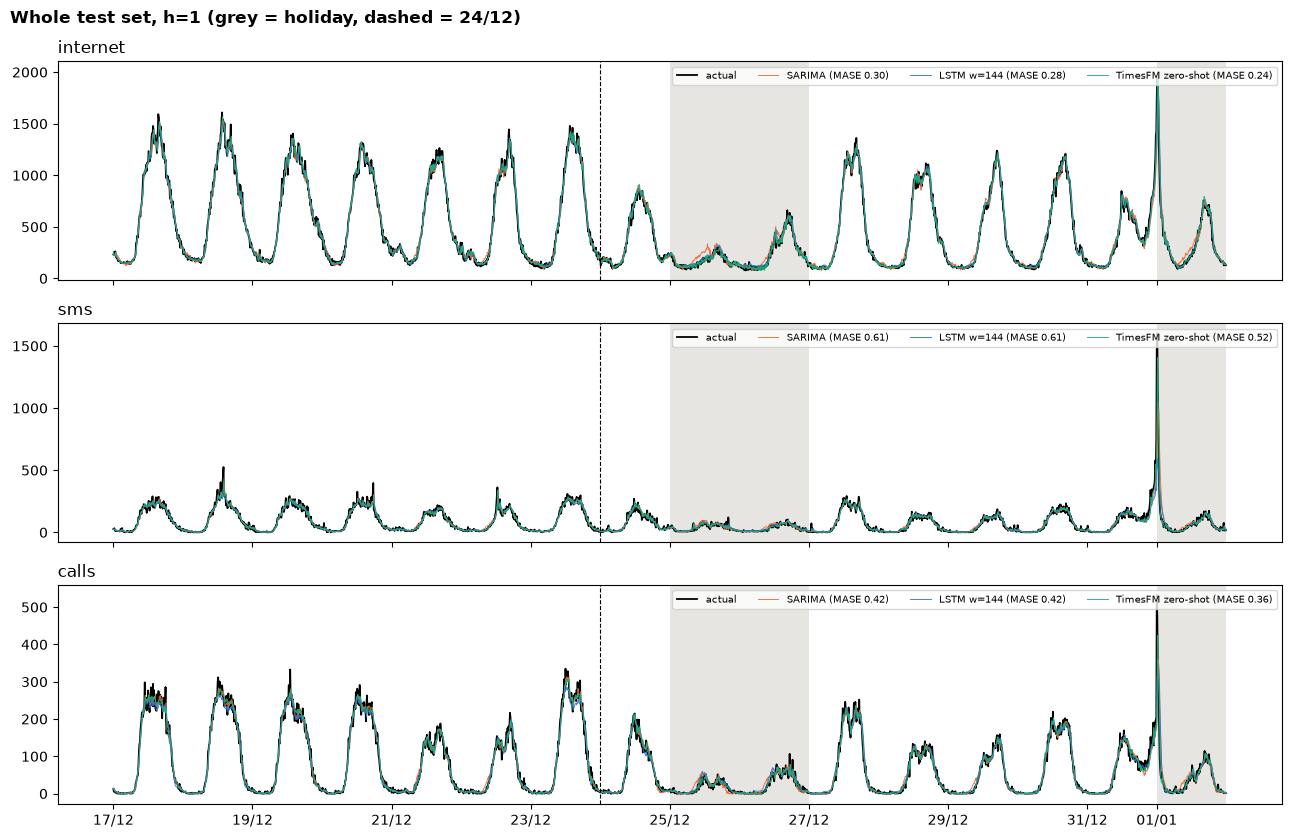

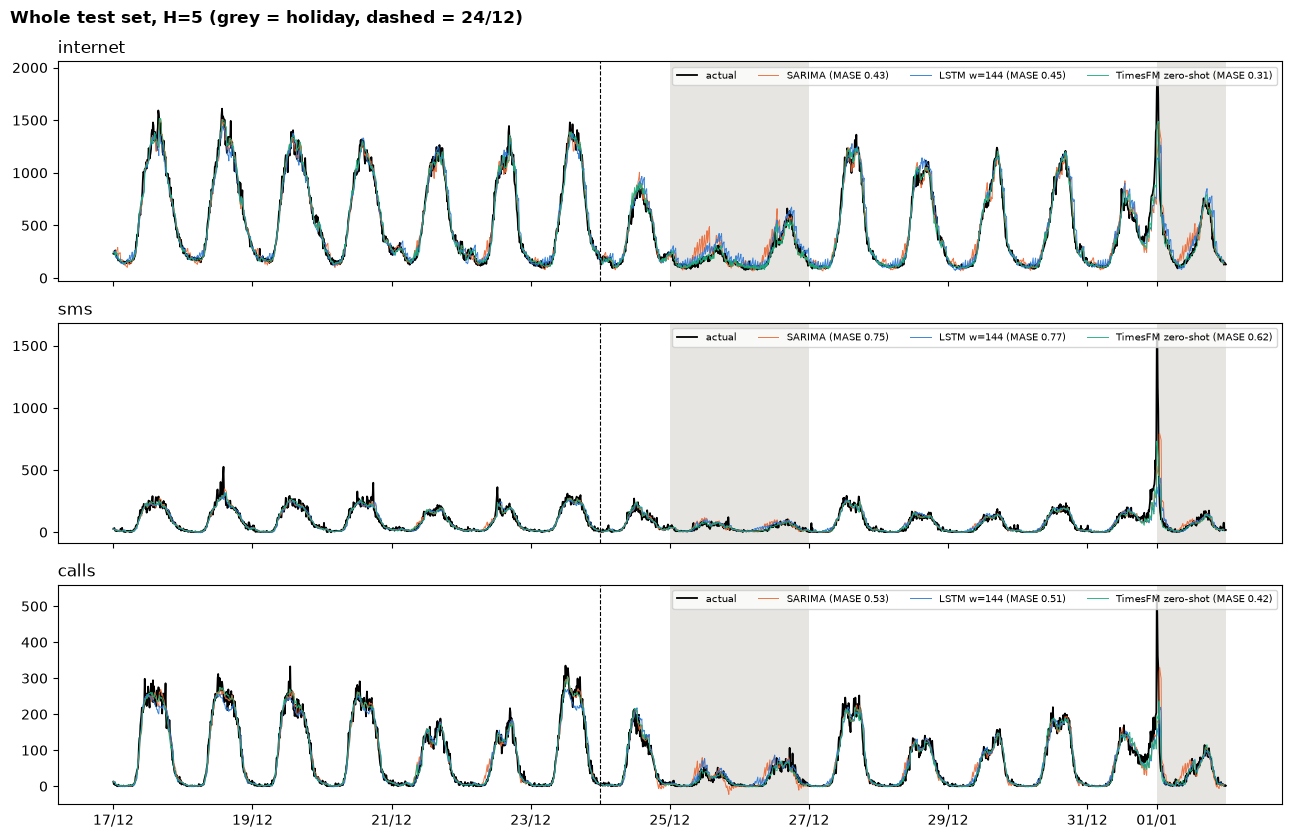

In [26]:
# Whole test set, best model of each family
for h in (1, 5):
    fig, axes = plt.subplots(len(SERIES), 1, figsize=(13, 8.5), sharex=True)
    for ax, s in zip(axes, SERIES):
        ax.plot(df.index[n_train:], Y[s][n_train:], color="k", lw=1.3, label="actual")
        for fam, m in MAIN.items():
            idx, yhat = PRED[(s, h)][m]
            ax.plot(df.index[idx], yhat, color=GROUP_COLOR[fam], lw=0.7, alpha=0.9,
                    label=f"{m} (MASE {FINAL.loc[(s, h, m), 'MASE']:.2f})")
        for d in HOLIDAYS[HOLIDAYS >= df.index[n_train]]:
            ax.axvspan(d, d + pd.Timedelta("1D"), color="#e6e5e1", lw=0)
        ax.axvline(pd.Timestamp("2013-12-24"), color="k", lw=0.8, ls="--")
        ax.set_title(s, loc="left"); ax.legend(fontsize=7.5, ncol=4, loc="upper right")
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
    fig.suptitle(f"Whole test set, {'h=1' if h == 1 else 'H=5'} (grey = holiday, dashed = 24/12)",
                 x=0.01, ha="left", fontweight="bold")
    fig.tight_layout(); plt.show()

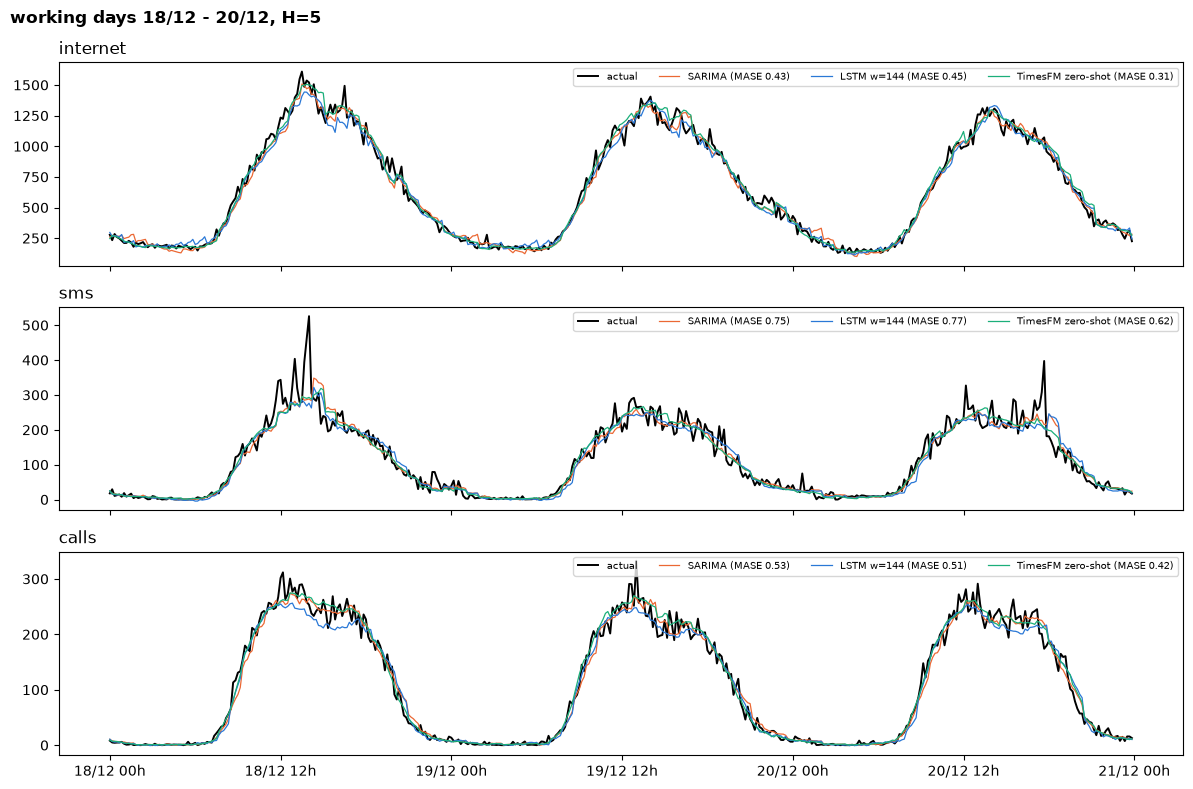

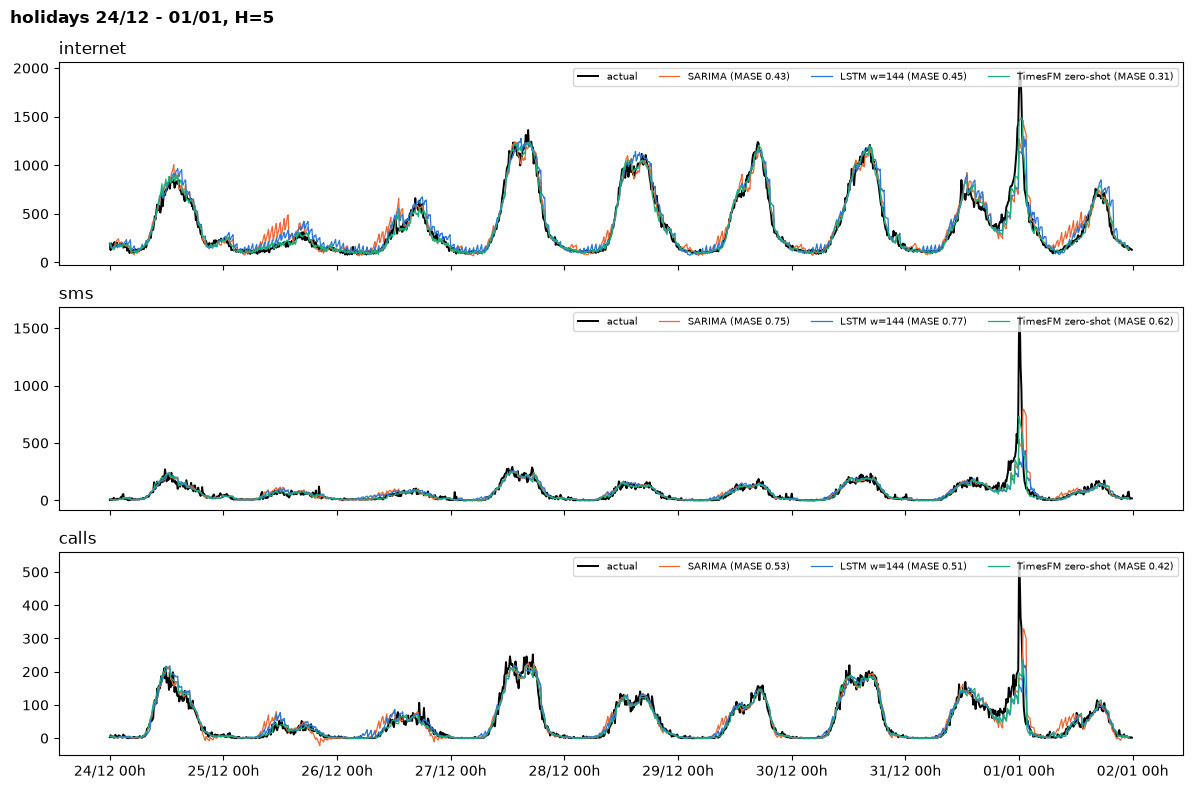

In [27]:
# Close-ups (H=5): the three main models on normal working days and on the holidays
for period, title in [(slice("2013-12-18", "2013-12-20"), "working days 18/12 - 20/12"),
                      (slice("2013-12-24", "2014-01-01"), "holidays 24/12 - 01/01")]:
    fig, axes = plt.subplots(len(SERIES), 1, figsize=(12, 8), sharex=True)
    for ax, s in zip(axes, SERIES):
        act_ = df[s].loc[period]
        ax.plot(act_.index, act_.values, color="k", lw=1.4, label="actual")
        for grp, m in MAIN.items():
            idx, yhat = PRED[(s, 5)][m]
            ser = pd.Series(yhat, index=df.index[idx]).loc[period]
            ax.plot(ser.index, ser.values, color=GROUP_COLOR[grp], lw=0.9,
                    label=f"{m} (MASE {FINAL.loc[(s, 5, m), 'MASE']:.2f})")
        ax.set_title(s, loc="left"); ax.legend(fontsize=7.5, ncol=4, loc="upper right")
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m %Hh"))
    fig.suptitle(f"{title}, H=5", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout(); plt.show()


#### Τι δείχνουν οι απεικονίσεις

Όλα τα μοντέλα πιάνουν πολύ καλά το ημερήσιο σχήμα. Στις κανονικές ημέρες οι προβλέψεις σχεδόν καλύπτουν την πραγματική
σειρά, και οι διαφορές των μετρικών αφορούν το ύψος της κορυφής και τις απότομες μεταβολές. Τη νύχτα το σφάλμα είναι πολύ
μικρό, και τα μεγάλα σφάλματα εμφανίζονται στις ώρες κίνησης, όπου ένα λάθος προκαλεί συμφόρηση.

Τις αιχμές δεν τις προβλέπει κανένα μοντέλο. Η Πρωτοχρονιά (Internet περίπου 2000, SMS περίπου 1600, Calls περίπου 500)
υποεκτιμάται από όλα και πιάνεται μόνο μερικώς, με καθυστέρηση: μια αιχμή χωρίς προηγούμενο εμφανίζεται στην πρόβλεψη ένα
βήμα αργότερα (*lag effect*).

Στις γιορτές τα μοντέλα του train περιμένουν κανονική ημέρα και υπερεκτιμούν, ενώ το TimesFM προσαρμόζεται πιο γρήγορα στο
χαμηλό επίπεδο. Στα Calls στις 26/12 οι προβλέψεις του SARIMA πέφτουν και κάτω από το μηδέν, κάτι που δεν έχει φυσικό νόημα.


### 5.6 Πότε το forecasting «έχει επιτύχει»;

Μία τιμή μετρικής από μόνη της δεν λέει αν η πρόβλεψη πέτυχε. Χρειάζεται σύγκριση με κάτι. Προτείνουμε τρία κριτήρια:

1. MASE $< 1$. Είναι πολύ χαλαρό: εδώ το περνούν όλα εκτός από τη seasonal naive, ακόμη και το Naive, γιατί σε 10 λεπτά η
   τελευταία τιμή είναι πολύ καλύτερη πρόβλεψη από την τιμή χθες.
2. Βελτίωση έναντι του Naive. Αυτό είναι το πραγματικό κατώφλι, γιατί το Naive δεν κοστίζει τίποτα. Μιλάμε για επιτυχία αν το
   MAE είναι τουλάχιστον 10% μικρότερο από του Naive, για οριακή βελτίωση από 0% έως 10%, και για αποτυχία αν δεν υπάρχει
   βελτίωση. Το όριο του 10% είναι επιλογή μας.
3. Τηλεπικοινωνιακό κριτήριο. Το σφάλμα πρέπει να είναι μικρό σε σχέση με το περιθώριο χωρητικότητας (headroom) που κρατά ο
   πάροχος, συνήθως 15% έως 30% πάνω από την αναμενόμενη ζήτηση. Αυτό το κρίνουμε με τη WAPE και με τα διαστήματα της ενότητας
   5.8.

Ο πρώτος πίνακας δίνει τη βελτίωση κάθε μοντέλου έναντι του Naive και ο δεύτερος εφαρμόζει το κριτήριο 2 στα τρία βασικά μοντέλα.


In [28]:
# Improvement over the persistence (Naive) forecast, % of its MAE (positive = better than Naive)
gain = {}
for (s, h, m), v in FINAL["MASE"].items():
    if m not in ("Naive", "Seasonal naive"):
        gain[(m, s, h)] = 100 * (1 - v / FINAL.loc[(s, h, "Naive"), "MASE"])
gain = pd.Series(gain).unstack([1, 2])[columns].loc[ORDER[2:]]
display(gain.style.format("{:+.1f}").background_gradient(cmap="RdYlGn", vmin=-30, vmax=30))


def verdict(g):
    return "fail" if g <= 0 else ("success" if g >= 10 else "marginal")


pd.DataFrame({(s, h): {m: f"{verdict(gain.loc[m, (s, h)])} ({gain.loc[m, (s, h)]:+.1f}%)" for m in MAIN.values()}
              for s, h in columns})


internet                                 sms  \
                                  1                 5                 1   
SARIMA             marginal (+2.2%)  success (+10.3%)      fail (-0.8%)   
LSTM w=144         marginal (+8.6%)  marginal (+5.7%)      fail (-0.8%)   
TimesFM zero-shot  success (+21.1%)  success (+34.8%)  success (+13.3%)   

                                                calls                    
                                  5                 1                 5  
SARIMA             marginal (+1.0%)  marginal (+4.3%)  success (+11.4%)  
LSTM w=144             fail (-1.5%)  marginal (+4.8%)  success (+14.8%)  
TimesFM zero-shot  success (+18.6%)  success (+17.7%)  success (+30.1%)

#### Αποτίμηση ανά περίπτωση

Το TimesFM πετυχαίνει σε όλες τις περιπτώσεις (+13.3% έως +34.8%). Το SARIMA πετυχαίνει μόνο στο long-term σε Internet (+10.3%) και
Calls (+11.4%), οριακά, και το LSTM $w = 144$ μόνο στο long-term σε Calls (+14.8%). Στο short-term κανένα από τα δύο δεν ξεπερνά το
οριακό, γιατί σε 10 λεπτά η persistence είναι πολύ δυνατή.

Τα SMS είναι η πιο δύσκολη σειρά: το SARIMA και το LSTM δεν νικούν ουσιαστικά το Naive (−1.5% έως +1.0%), ενώ το TimesFM το βελτιώνει
σημαντικά. Η από-περιοδικοποιημένη LSTM αποτυγχάνει παντού (−2% έως −39%), εξαιτίας των γιορτών (ενότητα 5.4).

Με το κριτήριο 3, στο Internet το TimesFM κάνει λάθος στο 6.1% του όγκου για $h = 1$ και 7.9% για $H = 5$, πολύ κάτω από ένα τυπικό
headroom. Στα SMS (16.5% και 19.5%) το σφάλμα είναι συγκρίσιμο με το headroom, αν και ο όγκος τους είναι πολύ μικρός σε σχέση με το
Internet.


### 5.7 Έχουν οι μετρικές φυσική ερμηνεία;

Τα RMSE και MAE εκφράζονται στις μονάδες της σειράς, αλλά οι τιμές του dataset είναι κλιμακωμένες με μια άγνωστη σταθερά
$k$. Επιπλέον το Internet μετρά CDRs και όχι bytes, οπότε ένα MAE 29 δεν είναι 29 MB. Ερμηνεύονται μόνο σχετικά: MAE 29 όταν η κορυφή της ημέρας είναι 1200 έως 1600 είναι περίπου
2% της κορυφής.

Η MAPE έχει θεωρητικά ερμηνεία (μέσο σχετικό σφάλμα), αλλά εδώ εκρήγνυται στις νυχτερινές τιμές κοντά στο μηδέν. Η WAPE έχει
καθαρή ερμηνεία: το ποσοστό του όγκου που προβλέφθηκε λάθος, και συγκρίνεται απευθείας με το περιθώριο χωρητικότητας. Η MASE δεν
είναι φυσικό μέγεθος, αλλά σύγκριση με έναν απλό κανόνα, και γι' αυτό είναι η κατάλληλη κύρια μετρική για τη σύγκριση μοντέλων. Η
κάλυψη ενός διαστήματος, που εξετάζουμε στη συνέχεια, έχει επίσης φυσικό νόημα: δείχνει πόσο συχνά η ζήτηση ξεπερνά το όριο που διαστασιολογήσαμε.


### 5.8 Bonus: διαστήματα πρόβλεψης 95% για το short-term

Για τη διαστασιολόγηση πόρων χρειαζόμαστε ένα εύρος που περιέχει τη μελλοντική τιμή με πιθανότητα 95%. (Αυστηρά λέγεται διάστημα
πρόβλεψης, γιατί αφορά μια μελλοντική τιμή και όχι μια παράμετρο.) Το υπολογίζουμε για το SARIMA και το TimesFM zero-shot.

SARIMA. Για $h = 1$ το σφάλμα πρόβλεψης είναι ακριβώς το $\varepsilon_{t+1}$. Αν είναι κανονικό, το διάστημα είναι
$\hat y_{t+1} \pm 1.96\, \hat\sigma$, με $\hat\sigma$ από το train. Το πλάτος του είναι ίδιο τη νύχτα και στην κορυφή.

TimesFM. Το μοντέλο δίνει τα ποσοστημόρια $q_{0.1}, \dots, q_{0.9}$, αλλά για το 95% χρειαζόμαστε τα $q_{0.025}$ και $q_{0.975}$. Τα
προσεγγίζουμε θεωρώντας κανονική κατανομή γύρω από τη διάμεσο:

$$\hat\sigma_t = \frac{q_{0.9} - q_{0.1}}{2 \cdot 1.2816}, \qquad q_{0.5} \;\pm\; 1.96 \, \hat\sigma_t$$

Το 1.2816 είναι το ποσοστημόριο 0.9 της τυπικής κανονικής. Εδώ το $\hat\sigma_t$ αλλάζει σε κάθε σημείο, δηλαδή το μοντέλο εκτιμά
διαφορετική αβεβαιότητα για κάθε πρόβλεψη.

Μετράμε την κάλυψη, δηλαδή το ποσοστό των σημείων του test που πέφτουν μέσα στο διάστημα (στόχος περίπου 95%), το μέσο πλάτος
(στενότερο είναι καλύτερο, αν η κάλυψη είναι σωστή) και πόσο συχνά το κάτω όριο είναι αρνητικό.


In [29]:
Z95 = 1.959964                                                 # standard normal 97.5% quantile
PI = {}
for s in SERIES:
    # SARIMA: the one-step error is the innovation, with variance sigma^2
    sd = np.sqrt(BEST.loc[(s, "SARIMA"), "params"][-1])
    h1 = ARIMA_ROLL[(s, "SARIMA")]["h1"]
    PI[(s, "SARIMA")] = (h1 - Z95 * sd, h1 + Z95 * sd)

    # TimesFM: Gaussian approximation around the median, sigma from the 10%-90% quantile spread
    t = TFM_RES[s]["zero"]
    qs = list(np.round(t["quantiles"], 3))
    q10, q50, q90 = (t["q_h1"][:, qs.index(q)] for q in (0.1, 0.5, 0.9))
    sig = (q90 - q10) / (2 * 1.281552)
    PI[(s, "TimesFM zero-shot")] = (q50 - Z95 * sig, q50 + Z95 * sig)

rows = []
for (s, m), (lo, hi) in PI.items():
    y = Y[s][idx1]
    inside = (y >= lo) & (y <= hi)
    rows.append({"series": s, "model": m, "coverage %": 100 * inside.mean(),
                 "normal days %": 100 * inside[idx1 < cut].mean(), "holidays %": 100 * inside[idx1 >= cut].mean(),
                 "below lower %": 100 * np.mean(y < lo), "above upper %": 100 * np.mean(y > hi),
                 "mean width / MASE scale": np.mean(hi - lo) / MASE_SCALE[s],
                 "lower bound < 0 %": 100 * np.mean(lo < 0)})
COVERAGE = pd.DataFrame(rows).set_index(["series", "model"])
COVERAGE.round(2)


coverage %  normal days %  holidays %  \
series   model                                                      
internet SARIMA                  98.13          98.41       97.92   
         TimesFM zero-shot       92.14          92.36       91.98   
sms      SARIMA                  91.80          91.07       92.36   
         TimesFM zero-shot       91.88          92.96       91.05   
calls    SARIMA                  92.53          91.47       93.36   
         TimesFM zero-shot       92.53          93.25       91.98   

                            below lower %  above upper %  \
series   model                                             
internet SARIMA                      0.61           1.26   
         TimesFM zero-shot           2.86           4.99   
sms      SARIMA                      3.26           4.95   
         TimesFM zero-shot           1.17           6.94   
calls    SARIMA                      3.34           4.12   
         TimesFM zero-shot           1.48           5.99   

                            mean width / MASE scale  lower bound < 0 %  
series   model                                                          
internet SARIMA                                2.15              11.55  
         TimesFM zero-shot                     1.07               0.00  
sms      SARIMA                                2.85              44.14  
         TimesFM zero-shot                     2.24              23.05  
calls    SARIMA                                2.31              46.92  
         TimesFM zero-shot                     1.63              35.11

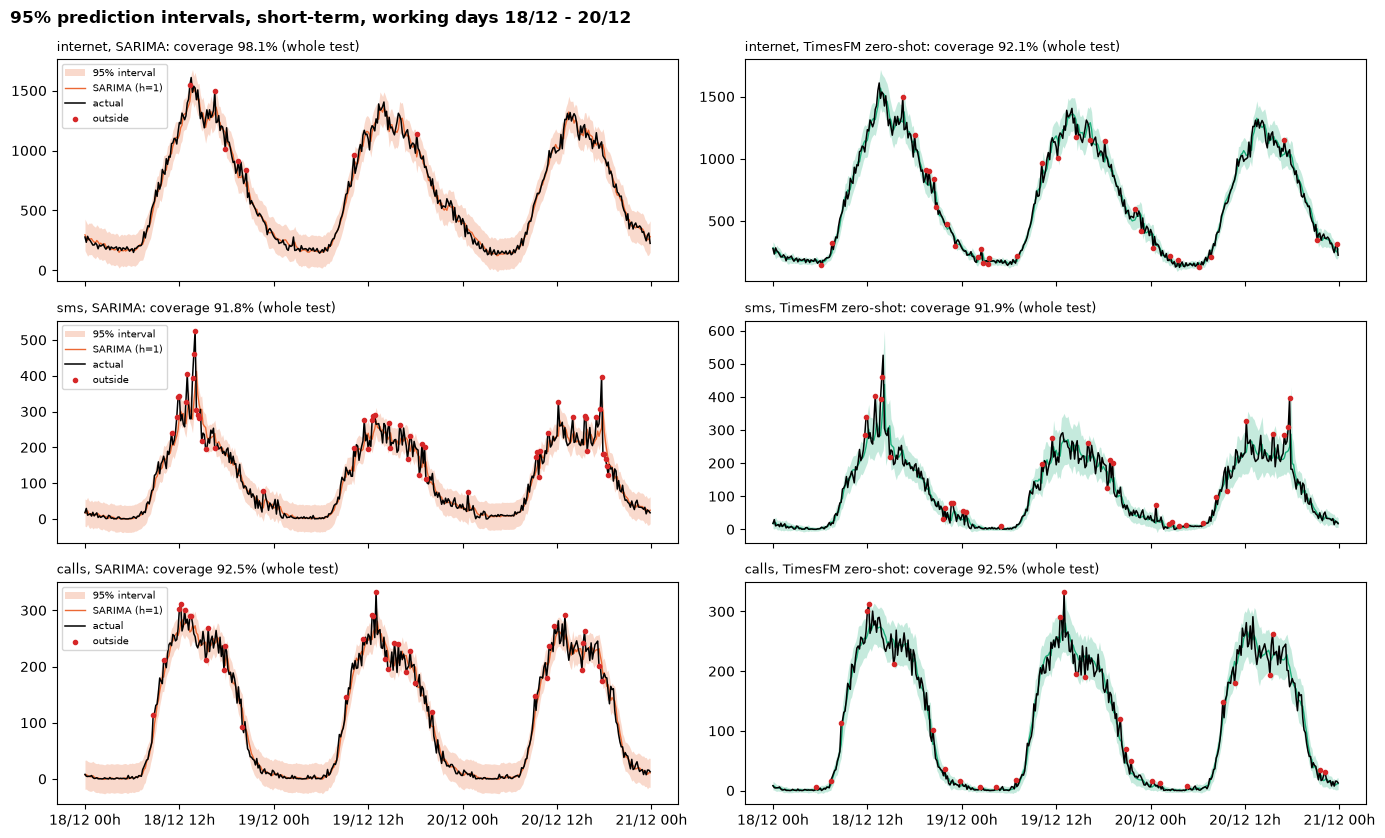

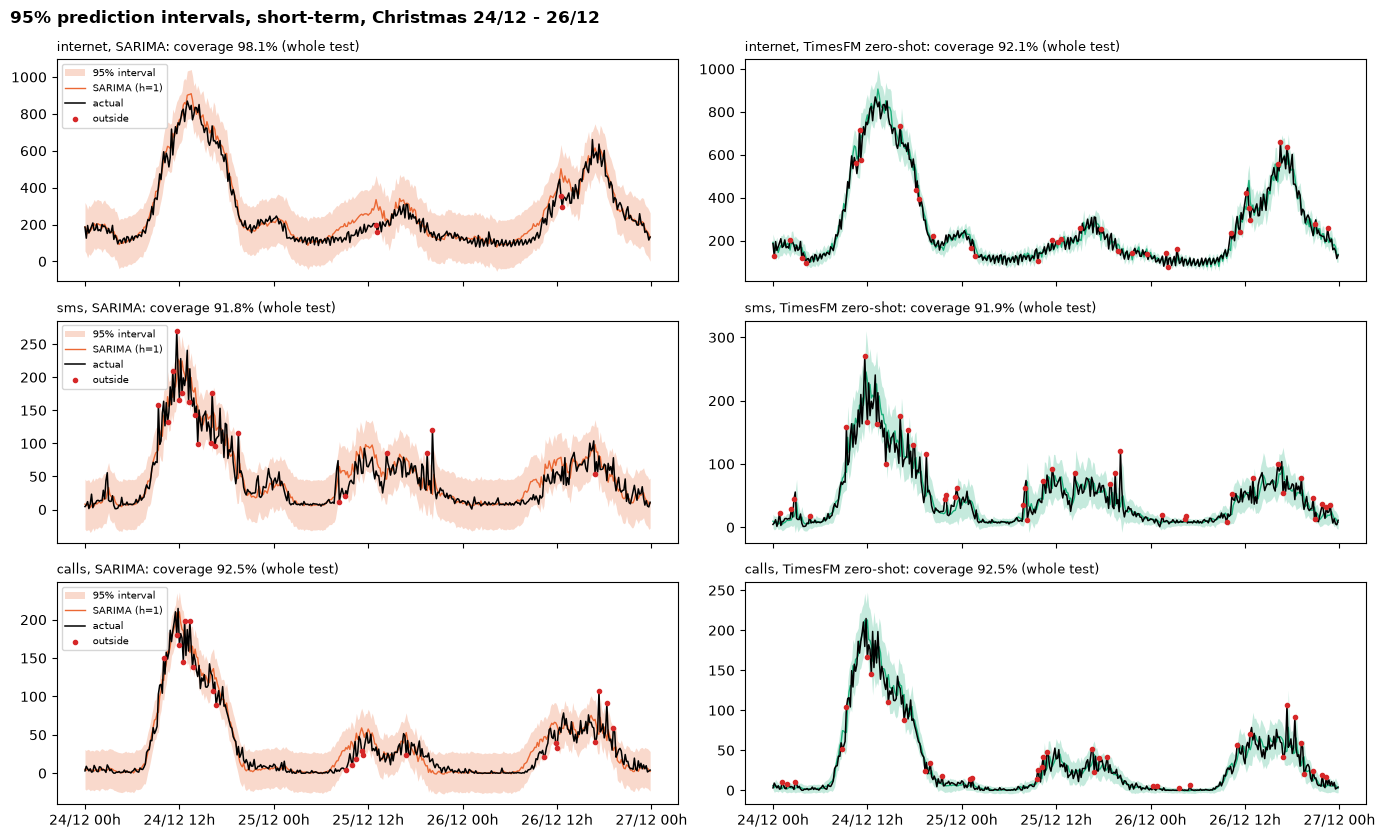

In [30]:
for period, title in [(slice("2013-12-18", "2013-12-20"), "working days 18/12 - 20/12"),
                      (slice("2013-12-24", "2013-12-26"), "Christmas 24/12 - 26/12")]:
    fig, axes = plt.subplots(len(SERIES), 2, figsize=(14, 8.5), sharex=True)
    tt = df.index[idx1]
    sel = (tt >= pd.Timestamp(period.start)) & (tt < pd.Timestamp(period.stop) + pd.Timedelta("1D"))
    for i, s in enumerate(SERIES):
        for ax, m, c in [(axes[i, 0], "SARIMA", GROUP_COLOR["ARIMA"]),
                         (axes[i, 1], "TimesFM zero-shot", GROUP_COLOR["TimesFM"])]:
            lo, hi = PI[(s, m)]
            ax.fill_between(tt[sel], lo[sel], hi[sel], color=c, alpha=0.25, lw=0, label="95% interval")
            ax.plot(tt[sel], PRED[(s, 1)][m][1][sel], color=c, lw=1, label=f"{m} (h=1)")
            ax.plot(tt[sel], Y[s][idx1][sel], color="k", lw=1.1, label="actual")
            out = sel & ((Y[s][idx1] < lo) | (Y[s][idx1] > hi))
            ax.scatter(tt[out], Y[s][idx1][out], color="#d62728", s=9, zorder=3, label="outside")
            ax.set_title(f"{s}, {m}: coverage {COVERAGE.loc[(s, m), 'coverage %']:.1f}% (whole test)",
                         loc="left", fontsize=9.5)
        axes[i, 0].legend(fontsize=7, loc="upper left")
    for ax in axes[-1]:
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m %Hh"))
    fig.suptitle(f"95% prediction intervals, short-term, {title}", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout(); plt.show()

#### Ερμηνεία των διαστημάτων

| 95% διάστημα, $h = 1$ | Internet | SMS | Calls |
|:---|:---:|:---:|:---:|
| SARIMA: κάλυψη | 98.1% | 91.8% | 92.5% |
| SARIMA: μέσο πλάτος / κλίμακα MASE | 2.15 | 2.85 | 2.31 |
| TimesFM: κάλυψη | 92.1% | 91.9% | 92.5% |
| TimesFM: μέσο πλάτος / κλίμακα MASE | 1.07 | 2.24 | 1.63 |

Το πλάτος του SARIMA είναι σταθερό. Τη νύχτα το διάστημα είναι υπερβολικά φαρδύ και πηγαίνει κάτω από το μηδέν (στο 12% των σημείων
για το Internet, στο 44% έως 47% για SMS και Calls), και στην κορυφή είναι πολύ στενό. Στο Internet η κάλυψη είναι 98%, πάνω από
τον στόχο. Στα SMS και Calls είναι 92%, λίγο κάτω, λόγω των απρόβλεπτων αιχμών.

Τα διαστήματα του TimesFM προσαρμόζονται: είναι στενά τη νύχτα και φαρδύτερα στην κορυφή. Με παρόμοια κάλυψη στα SMS και Calls είναι
21% έως 29% στενότερα, και στο Internet περίπου τα μισά, με κάλυψη όμως 92%. Και στις τρεις σειρές καλύπτει λίγο κάτω από το 95%. Τα
σημεία εκτός είναι κυρίως πάνω από το διάστημα (SMS: 6.9% πάνω, 1.2% κάτω), γιατί τις ανοδικές αιχμές δεν τις προβλέπει κανείς. Το
αρνητικό κάτω όριο (23% έως 35% των σημείων σε SMS και Calls) στην πράξη κόβεται στο 0.

Η κάλυψη δεν πέφτει ουσιαστικά στις γιορτές, γιατί για $h = 1$ η πρόβλεψη βασίζεται κυρίως στην τελευταία πραγματική τιμή.

Τηλεπικοινωνιακά, το άνω όριο είναι αυτό που χρειάζεται για τη διαστασιολόγηση: αν δεσμεύουμε χωρητικότητα ίση με το $q_{0.975}$, η
ζήτηση την ξεπερνά περίπου στο 2.5% των δεκαλέπτων. Ένα πολύ φαρδύ διάστημα σπαταλά πόρους και ενέργεια, ιδίως τη νύχτα, και ένα
πολύ στενό οδηγεί σε συμφόρηση τη στιγμή που μετράει. Η υποκάλυψη του TimesFM θα μπορούσε να διορθωθεί με conformal prediction, που
ρυθμίζει το πλάτος με βάση τα πρόσφατα σφάλματα.


## 6. Τηλεπικοινωνιακή σημασία, ενορχήστρωση σε 6G και χρόνοι inference

### 6.1 Η τηλεπικοινωνιακή σημασία των αποτελεσμάτων

Internet. Με WAPE 6.1% ($h = 1$) και 7.9% ($H = 5$) ο πάροχος ξέρει 10 έως 50 λεπτά πριν από την αιχμή πόση χωρητικότητα θα χρειαστεί,
με σφάλμα πολύ μικρότερο από ένα τυπικό περιθώριο. Μπορεί έτσι να ενεργοποιήσει carriers ή small cells και να κλιμακώσει UPF και CU-UP
πριν φτάσει η αιχμή.

Νύχτα. Η κίνηση είναι χαμηλή και το σφάλμα πολύ μικρό, οπότε ο εξοπλισμός μπορεί να απενεργοποιηθεί με ασφάλεια για εξοικονόμηση
ενέργειας, που είναι βασικός στόχος του 6G.

Calls. Η φωνή είναι ευαίσθητη σε καθυστέρηση και χρειάζεται εγγυημένο ρυθμό. Με καλή πρόβλεψη του ημερήσιου προφίλ οι πόροι της δεσμεύονται
δυναμικά, αντί να κρατούνται μόνιμα για τη χειρότερη περίπτωση.

SMS και αιχμές. Τα SMS φορτώνουν κυρίως το control plane. Στην Πρωτοχρονιά έφτασαν περίπου 70 φορές το κανονικό σε 10 λεπτά, κάτι που δεν
προβλέπεται από το ιστορικό. Για τέτοια γεγονότα χρειάζεται ημερολόγιο εκδηλώσεων και περιθώριο ασφαλείας.

Γιορτές. Ένα μοντέλο εκπαιδευμένο σε κανονικές ημέρες υπερεκτιμά τα Χριστούγεννα, που σημαίνει σπατάλη πόρων. Ο ίδιος μηχανισμός σε μια
ασυνήθιστα υψηλή ημέρα θα σήμαινε συμφόρηση, οπότε τα μοντέλα πρέπει να παρακολουθούνται συνεχώς.

Zero-shot. Το καλύτερο μοντέλο δεν χρειάστηκε εκπαίδευση ανά κυψέλη. Αυτό απλοποιεί πολύ τη λειτουργία σε δίκτυο με χιλιάδες κυψέλες
και καλύπτει και νέες κυψέλες χωρίς μεγάλο ιστορικό.

Διαστήματα. Η υποεκτίμηση (συμφόρηση, παραβίαση SLA) κοστίζει συνήθως πολύ περισσότερο από την υπερεκτίμηση (ενέργεια, δεσμευμένοι πόροι).
Γι' αυτό η διαστασιολόγηση πρέπει να γίνεται με ένα άνω όριο της πρόβλεψης και όχι με τη σημειακή τιμή.

### 6.2 Ενορχήστρωση σε πραγματικό δίκτυο 6G πραγματικού χρόνου

Ο κλειστός βρόχος ακολουθεί το ETSI ZSM και την αρχιτεκτονική O-RAN, όπου η «ευφυΐα» του RAN βρίσκεται σε δύο ελεγκτές: τον Non-RT RIC, με
βρόχους πάνω από 1 s και εφαρμογές που λέγονται rApps, και τον Near-RT RIC, με βρόχους από 10 ms έως 1 s και εφαρμογές που λέγονται xApps.

1. Monitor. Οι μετρήσεις φορτίου κάθε κυψέλης ρέουν από τους σταθμούς βάσης (διεπαφές E2 και O1) και αποθηκεύονται σε βάση χρονοσειρών.
2. Analyze. Ένα forecasting rApp στον Non-RT RIC τρέχει σε κάθε νέο δεκάλεπτο και βγάζει για κάθε κυψέλη πρόβλεψη με ποσοστημόρια. Είναι
   ακριβώς το rolling-window σχήμα του notebook.
3. Decide. Η χωρητικότητα ορίζεται από ένα άνω ποσοστημόριο, $C_{t+h} = \hat q_\tau(y_{t+h})$. Το $\tau$ προκύπτει από το κόστος,
   $\tau^* = c_{\text{under}} / (c_{\text{under}} + c_{\text{over}})$: υψηλό για ένα slice URLLC, χαμηλότερο για eMBB. Η απόφαση περνά στον Near-RT
   RIC ως πολιτική (A1 policy).
4. Execute. Ενεργοποίηση carriers ή small cells πριν από την αιχμή, αναδιανομή PRBs μεταξύ slices, predictive autoscaling των UPF, CU-UP και
   MEC, απενεργοποίηση εξοπλισμού τη νύχτα, load balancing προς γειτονικές κυψέλες.
5. Feedback. Μετά από κάθε δεκάλεπτο η πραγματική τιμή συγκρίνεται με την πρόβλεψη. Αν το μοντέλο γίνει χειρότερο από το Naive για αρκετό
   διάστημα (*concept drift*, όπως στις γιορτές), ο βρόχος γυρίζει σε ένα απλό εφεδρικό μοντέλο και ζητά επανεκπαίδευση.

### 6.3 Χρόνοι εκπαίδευσης και inference

Το επόμενο κελί μετρά στον ίδιο υπολογιστή (CPU, χωρίς GPU) τον χρόνο μίας πρόβλεψης 5 βημάτων και τον μέσο χρόνο όταν πολλές προβλέψεις
γίνονται μαζί σε batch. Για τα ARIMA ο χρόνος περιλαμβάνει και την ενημέρωση με τη νέα τιμή, και δεν υπάρχει batch. Για τα LSTM μετράμε
ένα δίκτυο με την ίδια αρχιτεκτονική. Το κελί φορτώνει ξανά το TimesFM και παίρνει περίπου ένα λεπτό.


In [31]:
from timesfm3 import TimesFM3Forecaster


def median_ms(fn, reps):
    """Median wall time of fn() over reps runs, in ms."""
    ts = []
    for _ in range(reps):
        t0 = time.perf_counter(); fn(); ts.append(time.perf_counter() - t0)
    return 1e3 * np.median(ts)


s, t = "internet", n_train + 100                               # any series and origin: the cost is the same
timing = []

# ARIMA family: mean cost of one step of the rolling loop (forecast + update). statsmodels has no batching.
for fam in FAMILIES:
    ms = 1e3 * np.mean([ARIMA_ROLL[(ss, fam)]["seconds_per_forecast"] for ss in SERIES])
    timing.append({"model": fam, "parameters": len(BEST.loc[(s, fam), "params"]),
                   "training (s)": GRID.loc[GRID["model"] == fam, "fit_seconds"].mean(),
                   "single forecast (ms)": ms, "batched (ms / forecast)": ms})

# LSTM: same architecture as in section 3 (the weights do not change the cost of a forward pass)
for w in LSTM_WINDOWS:
    net = LSTMNet(H_LONG).eval()
    x1, xb = torch.randn(1, w, 1), torch.randn(len(idx1), w, 1)
    with torch.no_grad():
        torch.set_num_threads(1)
        single = median_ms(lambda: net(x1), 50)
        torch.set_num_threads(TFM_THREADS)
        batched = median_ms(lambda: net(xb), 3) / len(idx1)
    timing.append({"model": f"LSTM w={w}", "parameters": sum(p.numel() for p in net.parameters()),
                   "training (s)": np.mean([v["train_seconds"] for (ss, ww, ds, h), v in LSTM_RES.items() if ww == w]),
                   "single forecast (ms)": single, "batched (ms / forecast)": batched})

# TimesFM: single forecast with the pretrained weights, batched cost from the rolling evaluation of section 4
torch.set_num_threads(TFM_THREADS)
fc = TimesFM3Forecaster.from_pretrained(device="cpu")
ctx = Y[s][t - TFM_CONTEXT:t]
fc.predict(ctx, horizon=H_LONG)                                # warm-up
single = median_ms(lambda: fc.predict(ctx, horizon=H_LONG), 5)
for key, name, train in [("zero", "TimesFM zero-shot", 0.0),
                         ("ft", "TimesFM fine-tuned", np.mean([TFM_RES[ss]["ft_info"]["train_seconds"] for ss in SERIES]))]:
    timing.append({"model": name, "parameters": TFM_RES[s]["ft_info"]["total_params"], "training (s)": train,
                   "single forecast (ms)": single,
                   "batched (ms / forecast)": 1e3 * np.mean([TFM_RES[ss][key]["seconds_per_forecast"] for ss in SERIES])})
del fc

TIMING = pd.DataFrame(timing).set_index("model")
# One forecast per cell every 10 minutes: compute time for a network of 10 000 cells, batched, on this CPU
TIMING["10k cells, one cycle (s)"] = TIMING["batched (ms / forecast)"] * 10_000 / 1e3
print(f"CPU: {os.cpu_count()} threads, no GPU. LSTM single: 1 thread. LSTM batched and TimesFM: {TFM_THREADS} threads.")
TIMING.style.format({"parameters": "{:,.0f}", "training (s)": "{:.2f}", "single forecast (ms)": "{:.3f}",
                     "batched (ms / forecast)": "{:.4f}", "10k cells, one cycle (s)": "{:.1f}"})

CPU: 192 threads, no GPU. LSTM single: 1 thread. LSTM batched and TimesFM: 32 threads.


,parameters,training (s),single forecast (ms),batched (ms / forecast),"10k cells, one cycle (s)"
model,,,,,
SARIMA,5,1312.77,8.661,8.6612,86.6
ARIMA-x,21,10.96,2.670,2.6698,26.7
LSTM w=10,"50,757",72.85,0.237,0.0068,0.1
LSTM w=144,"50,757",611.09,0.849,0.1713,1.7
TimesFM zero-shot,"330,710,976",0.00,495.398,46.3079,463.1
TimesFM fine-tuned,"330,710,976",428.90,495.398,44.4253,444.3


#### Ευνοούν οι χρόνοι μια online, real-time διαδικασία;

Οι χρόνοι αλλάζουν λίγο από εκτέλεση σε εκτέλεση, οπότε δίνουμε τάξεις μεγέθους:

| | Εκπαίδευση | Μία πρόβλεψη | Σε batch, ανά πρόβλεψη | 10 000 κυψέλες ανά κύκλο |
|:---|:---:|:---:|:---:|:---:|
| SARIMA | περίπου 22 λεπτά | περίπου 9 ms | περίπου 9 ms | περίπου 1.5 λεπτό |
| ARIMA-x | περίπου 11 s | περίπου 3 ms | περίπου 3 ms | περίπου 27 s |
| LSTM | 1 έως 10 λεπτά | 0.2 έως 0.9 ms | κάτω από 0.2 ms | κάτω από 2 s |
| TimesFM 3.0 | καμία (zero-shot), περίπου 7 λεπτά (fine-tuning) | περίπου 0.5 s | περίπου 45 ms | περίπου 7.5 λεπτά |

Η εκπαίδευση γίνεται offline, οπότε τα 22 λεπτά του SARIMA δεν είναι πρόβλημα αν τα μοντέλα ανανεώνονται σπάνια, αλλά σε χιλιάδες
κυψέλες γίνονται το πιο ακριβό μέρος του. Στο inference το LSTM είναι το πιο γρήγορο, κάτω από 1 ms. Τα ARIMA χρειάζονται μερικά ms με το
`statsmodels`, που είναι αρκετό για τους αργούς βρόχους του Near-RT RIC αλλά όχι για τους πιο γρήγορους. Το TimesFM δεν χρειάζεται εκπαίδευση,
αλλά έχει το ακριβότερο inference, εκατοντάδες φορές πιο αργό από το LSTM σε αυτόν τον server (32 threads, χωρίς GPU).

Το συμπέρασμα εξαρτάται από τη χρονική κλίμακα του βρόχου. Για απόφαση ανά 10 λεπτά όλες οι μέθοδοι είναι αρκετά γρήγορες σε μία κυψέλη.
Σε 10 000 κυψέλες το TimesFM χρειάζεται περίπου 7.5 λεπτά ανά κύκλο, που χωράει στα 10 λεπτά αλλά χωρίς περιθώριο, ενώ με GPU ο χρόνος
μειώνεται σημαντικά. Για βρόχους κάτω του δευτερολέπτου το TimesFM σε CPU δεν είναι κατάλληλο.

Στην πράξη θα προτείναμε μια ιεραρχική αρχιτεκτονική. Το TimesFM (με GPU) τρέχει στον Non-RT RIC για προβλέψεις λεπτών έως ωρών, όπου η ακρίβειά
του (13% έως 27% μικρότερη MASE από SARIMA και LSTM) αξίζει το κόστος. Ελαφριά μοντέλα τρέχουν στον Near-RT RIC για τις γρήγορες διορθώσεις και
λειτουργούν και ως εφεδρικά.


## Αναφορές

1. G. Barlacchi et al., "A multi-source dataset of urban life in the city of Milan and the Province of Trentino,"
   *Scientific Data* 2, 150055, 2015. doi:10.1038/sdata.2015.55
2. Telecom Italia, "Telecommunications - SMS, Call, Internet - MI," Harvard Dataverse, 2015.
   doi:10.7910/DVN/EGZHFV
3. S. Siami-Namini, N. Tavakoli, A. Siami Namin, "A Comparison of ARIMA and LSTM in Forecasting Time Series," *IEEE
   ICMLA*, 2018. doi:10.1109/ICMLA.2018.00227
4. G. E. P. Box, G. M. Jenkins, G. C. Reinsel, G. M. Ljung, *Time Series Analysis: Forecasting and Control*, 5th ed.,
   Wiley, 2015.
5. R. J. Hyndman, A. B. Koehler, "Another look at measures of forecast accuracy," *International Journal of
   Forecasting* 22(4), 2006.
6. R. J. Hyndman, G. Athanasopoulos, *Forecasting: Principles and Practice*, 3rd ed., OTexts, 2021.
7. S. Hochreiter, J. Schmidhuber, "Long Short-Term Memory," *Neural Computation* 9(8), 1997.
8. A. Das, W. Kong, R. Sen, Y. Zhou, "A decoder-only foundation model for time-series forecasting," *ICML*, 2024, και
   google-research/timesfm (TimesFM 3.0).
9. ETSI GS ZSM 002, *Zero-touch network and Service Management (ZSM); Reference Architecture*.
10. 3GPP TS 23.288, *Architecture enhancements for 5G System to support network data analytics services*.
11. O-RAN Alliance, *O-RAN Architecture Description* (Non-RT RIC, Near-RT RIC, διεπαφές A1, E2, O1).